# Capítulo 7 — Testes de hipóteses frequentistas
**Igor Stellet · Estatística Bayesiana · 2026.2**

Vamos transformar uma pergunta científica em uma comparação quantitativa: **se um modelo descrevesse o experimento, que resultados esperaríamos encontrar em suas repetições?** Primeiro construímos a distribuição de uma estatística sob esse modelo; depois localizamos o resultado observado nessa distribuição.

O fio condutor é o capítulo 7 do **Gregory**, principalmente §§7.2–7.4, e os **slides 85–114 da Parte 2**. O notebook foi organizado em quatro partes:

1. Galáxia e toxina no rio: hipótese nula, qui-quadrado, construção da Student, diferença de médias, Welch e escolha das caudas.
2. Distribuições completas: posições estelares, escolaridade no Rio e em Salvador e as notas da P1 de Física 1.
3. Histogramas e aderência: origem da multinomial, teste de Pearson, quasares e Copas do Mundo de 2002 a 2026, individualmente e em conjunto.
4. A fábula das estrelas semelhantes ao Sol: regra de parada, binomial, binomial negativa, posterior e comparação de modelos.

**Notação.** Letras maiúsculas representam resultados que variam entre repetições; minúsculas representam valores observados. $H_0$ é o modelo de referência; $H_1$ especifica a mudança que queremos detectar. Reservaremos $\alpha$ para a taxa de erro tipo I escolhida antes da análise e $p_{\rm valor}$ para a probabilidade de cauda calculada com os dados.

In [1]:
from pathlib import Path
from io import StringIO
import base64, zlib, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from scipy import stats, special, optimize, integrate
from IPython.display import display, Markdown

%config InlineBackend.figure_format = 'retina'
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'font.size': 11, 'axes.titlesize': 12,
                     'axes.labelsize': 11, 'legend.fontsize': 9,
                     'grid.alpha': .22, 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.dpi': 110,
                     'savefig.dpi': 230, 'pdf.fonttype': 42, 'ps.fonttype': 42})
BLUE, GOLD, GREEN, PURPLE, RED = '#2878B5', '#B58618', '#27856D', '#8055A3', '#BD5254'
SEED = 20261028
def rng_for(offset):
    """Uma semente por experimento torna cada simulação reproduzível isoladamente."""
    return np.random.default_rng(SEED + offset)

SALVAR_ARQUIVOS = False
BASE_DIR = Path.cwd()  # Execute preferencialmente na pasta do notebook.
FIG_DIR = BASE_DIR / 'figuras' / 'capitulo_7'
TABLE_DIR = BASE_DIR / 'tabelas' / 'capitulo_7'
def figure_done(fig, name):
    if SALVAR_ARQUIVOS:
        FIG_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(FIG_DIR / f'{name}.pdf', bbox_inches='tight')
        fig.savefig(FIG_DIR / f'{name}.png', bbox_inches='tight')
    plt.show()
def table(rows, columns=None, name=None, digits=6):
    df = rows.copy() if isinstance(rows, pd.DataFrame) else pd.DataFrame(rows, columns=columns)
    # Algarismos significativos preservam probabilidades pequenas em notação científica.
    with pd.option_context('display.max_columns', None, 'display.max_colwidth', None,
                           'display.float_format', lambda x: f'{x:.{digits}g}'):
        display(df)
    if SALVAR_ARQUIVOS and name:
        TABLE_DIR.mkdir(parents=True, exist_ok=True)
        df.to_csv(TABLE_DIR / f'{name}.csv', index=False)
        # Um tabular simples e independente de bibliotecas extras.
        def esc(x):
            s = f'{x:.{digits}g}' if isinstance(x, (float, np.floating)) else str(x)
            return s.replace('&', r'\&').replace('%', r'\%').replace('_', r'\_')
        lines = [r'\begin{tabular}{'+'l'*len(df.columns)+'}', r'\hline',
                 ' & '.join(map(esc, df.columns))+r' \\', r'\hline']
        lines += [' & '.join(map(esc, row))+r' \\' for row in df.itertuples(index=False, name=None)]
        lines += [r'\hline', r'\end{tabular}']
        (TABLE_DIR / f'{name}.tex').write_text('\n'.join(lines), encoding='utf-8')
    return df

def mc_tail(reference, observed):
    """Cauda Monte Carlo com correção de uma contagem; inclui empates."""
    reference = np.asarray(reference)
    p = (1 + np.count_nonzero(reference >= observed - 1e-12)) / (len(reference) + 1)
    return p, np.sqrt(p * (1-p) / (len(reference)+1))
def verdict(p, alpha=.05):
    return 'rejeitar H0 neste nível' if p < alpha else 'manter H0 entre os modelos compatíveis neste nível'

checks = []
def check(name, condition):
    if not bool(condition): raise AssertionError(name)
    checks.append(name)

print('Exportação:', SALVAR_ARQUIVOS, '| Semente-base:', SEED)

Exportação: False | Semente-base: 20261028


## Parte 1 — Do modelo à distribuição da estatística
### 1.1 O que estamos testando? — slides 86–88

No exemplo da galáxia, $H_0$ afirma que um fluxo verdadeiro constante, somado aos erros instrumentais conhecidos, produz os dados. A alternativa de interesse acrescenta variabilidade intrínseca. No rio, $H_0$ afirma $\mu_1=\mu_2$; a alternativa admite médias diferentes.

Uma **estatística** é uma função dos dados, como $\bar X$, $S^2$, $T$ ou $Q$. Sua **distribuição de referência** descreve os valores dessa função em repetições do experimento sob $H_0$. A palavra “repetição” inclui o tamanho da amostra, a seleção dos objetos, o tratamento dos parâmetros desconhecidos e a regra de parada.

Escolhida uma medida de discrepância que cresce com o afastamento relevante, escrevemos

$$p_{\rm valor}=P_{H_0}\{T(D^*)\geq T(D_{\rm obs})\}.$$

$D^*$ representa uma nova amostra obtida pelo mesmo procedimento. Essa probabilidade é calculada **condicionando no modelo**. Uma probabilidade posterior para $H_0$ envolve outra pergunta: comparar modelos com verossimilhanças e probabilidades a priori, usando Bayes.

Fixar $\alpha=0{,}05$ significa escolher um procedimento cuja probabilidade de rejeitar $H_0$, quando ele gera os dados, seja no máximo 5%. Esse é o **erro tipo I**. Sob uma alternativa específica, a probabilidade de manter $H_0$ é o **erro tipo II**, $\beta$; a potência é $1-\beta$. A potência depende do tamanho do efeito, dos erros e da quantidade de dados. Uma conclusão científica deve acompanhar a decisão com a estimativa do efeito e sua incerteza.

### 1.2 Galáxia: os dados originais e a hipótese de fluxo constante — slides 89–94

Usamos a **Tabela 7.1 do Gregory, p. 164**. Cada $X_i$ é uma medida de fluxo em mJy, realizada no dia $t_i$. O modelo é

$$X_i=\mu+\varepsilon_i,\qquad \varepsilon_i\overset{\rm ind}{\sim}\mathcal N(0,\sigma^2),\qquad \sigma=2{,}7\ \mathrm{mJy}.$$

$\mu$ é constante e desconhecido. Aqui $\sigma$ é a incerteza instrumental conhecida de cada medida. A dispersão amostral $s$ será calculada a partir dos dados e tem outro papel.

O produto das densidades normais fornece

$$\log L(\mu)=C-\frac{1}{2\sigma^2}\sum_i(x_i-\mu)^2.$$

Derivando, $d\log L/d\mu=\sum_i(x_i-\mu)/\sigma^2=0$, obtemos $\widehat\mu=\bar x$. A segunda derivada é $-n/\sigma^2<0$, confirmando o máximo. Queremos saber se a dispersão que permanece em torno desse melhor fluxo constante é compatível com os erros instrumentais.

,Dia,Fluxo (mJy),Erro instrumental (mJy)
0,0,14.2,2.7
1,718,5,2.7
2,1097,3.3,2.7
3,1457.1,15.5,2.7
4,2524.1,4.2,2.7
5,3607.7,9.2,2.7
6,3630.1,8.2,2.7
7,4033.1,3.2,2.7
8,4161.3,5.6,2.7
9,5355.9,9.9,2.7


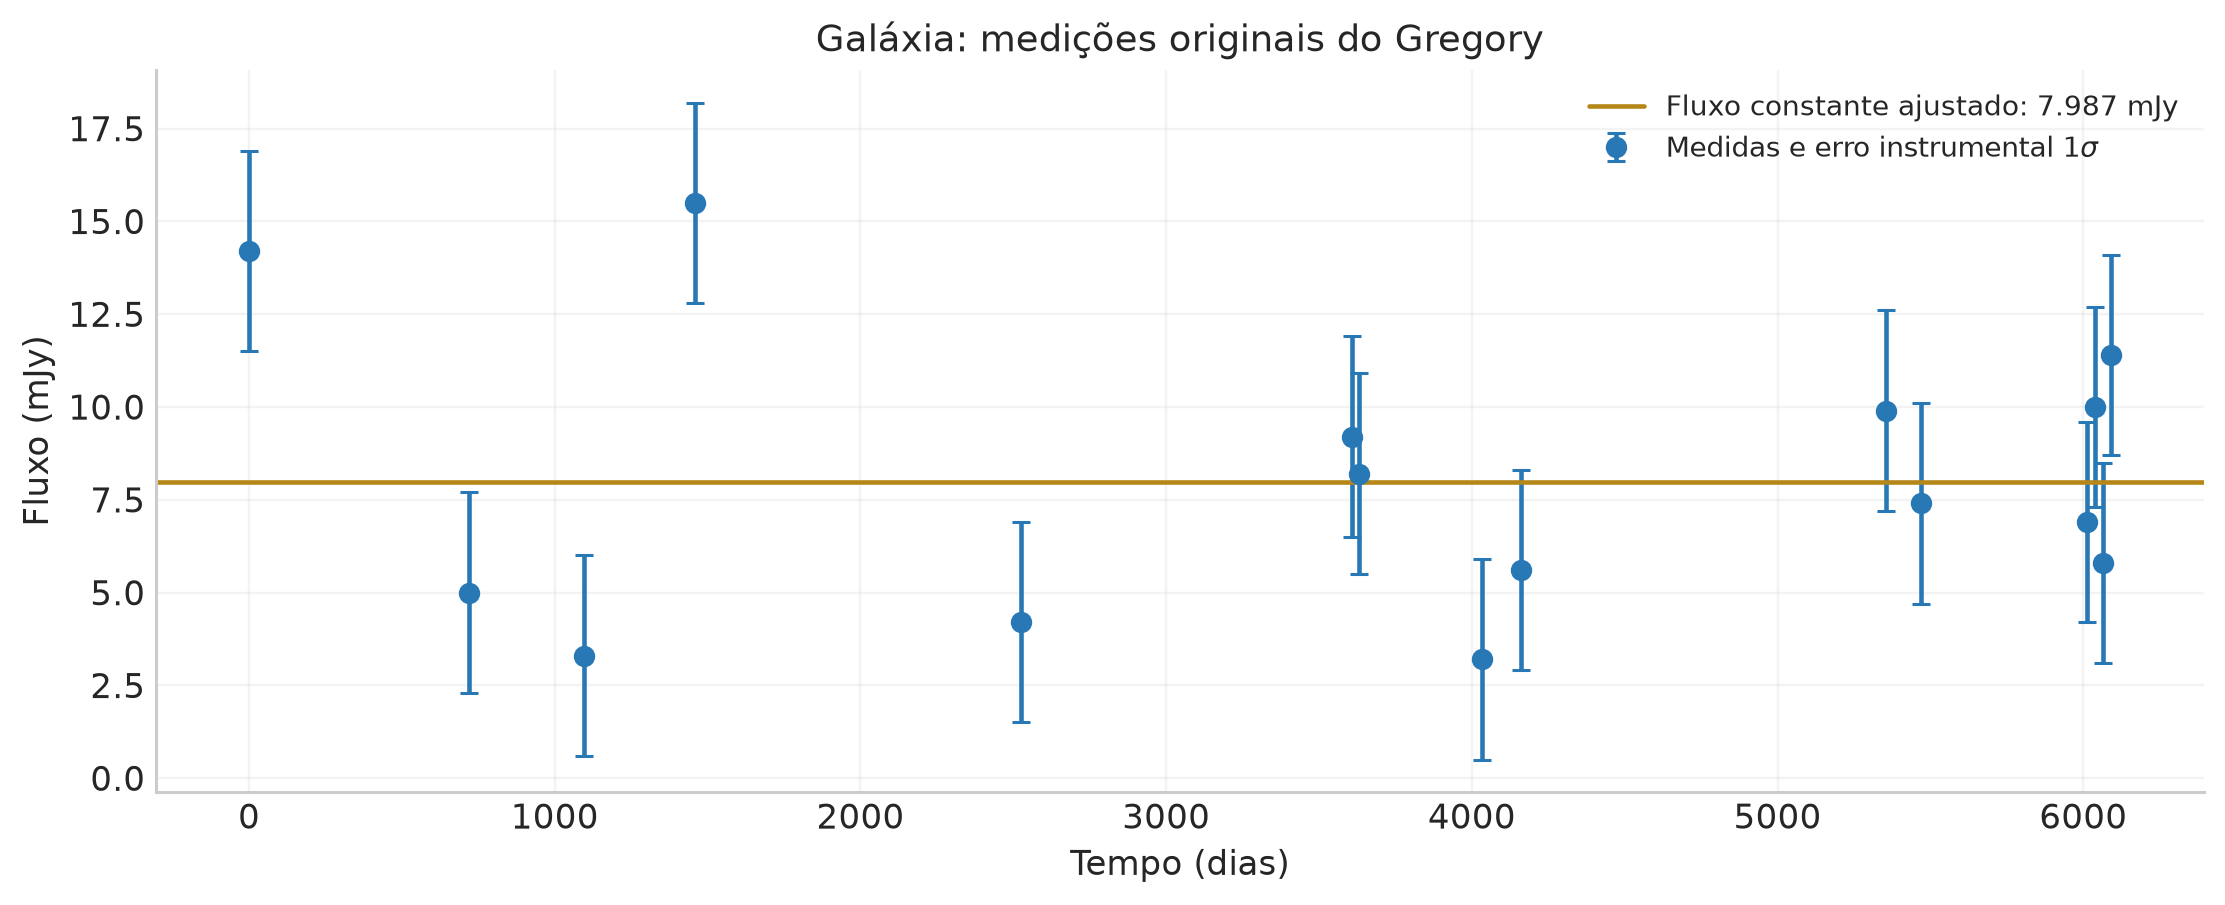

In [2]:
radio_days = np.array([0,718,1097,1457.1,2524.1,3607.7,3630.1,4033.1,
                       4161.3,5355.9,5469.1,6012.4,6038.3,6063.2,6089.3])
radio_flux = np.array([14.2,5,3.3,15.5,4.2,9.2,8.2,3.2,5.6,9.9,7.4,6.9,10,5.8,11.4])
radio_sigma = 2.7
radio_n = len(radio_flux)
radio_mean = radio_flux.mean()
radio_s = radio_flux.std(ddof=1)
radio_nu = radio_n - 1
radio_q = np.sum(((radio_flux-radio_mean)/radio_sigma)**2)
radio_p = stats.chi2.sf(radio_q, radio_nu)
table(pd.DataFrame({'Dia': radio_days, 'Fluxo (mJy)': radio_flux,
                    'Erro instrumental (mJy)': radio_sigma}), name='radio_dados')
fig, ax = plt.subplots(figsize=(10,4), layout='constrained')
ax.errorbar(radio_days, radio_flux, yerr=radio_sigma, fmt='o', color=BLUE,
            capsize=3, label=r'Medidas e erro instrumental $1\sigma$')
ax.axhline(radio_mean, color=GOLD, label=fr'Fluxo constante ajustado: {radio_mean:.3f} mJy')
ax.set(xlabel='Tempo (dias)', ylabel='Fluxo (mJy)', title='Galáxia: medições originais do Gregory')
ax.legend(); figure_done(fig, '01_radio_serie')

### 1.3 Por que a referência é $\chi^2_{n-1}$?

Defina $Z_i=(X_i-\mu)/\sigma$. O vetor $\mathbf Z$ tem $n$ componentes normais padrão independentes. Os resíduos após ajustar a média são

$$\frac{\mathbf X-\bar X\mathbf1}{\sigma}
=\left(I-\frac{\mathbf1\mathbf1^T}{n}\right)\mathbf Z=P\mathbf Z.$$

A matriz $P$ retira a componente paralela a $\mathbf1$: $P\mathbf1=0$. Ela preserva as $n-1$ direções perpendiculares, satisfazendo $P^2=P$. Uma rotação ortogonal separa essas direções e preserva a normal padrão. Portanto,

$$Q=\sum_i\frac{(X_i-\bar X)^2}{\sigma^2}
=\sum_{j=1}^{n-1}\widetilde Z_j^2\sim\chi^2_{n-1}.$$

O grau de liberdade retirado corresponde à média estimada com os mesmos dados. A definição por soma de quadrados leva à densidade

$$f_{\chi^2_\nu}(q)=\frac{q^{\nu/2-1}e^{-q/2}}{2^{\nu/2}\Gamma(\nu/2)},\quad q>0,
\qquad \Gamma(a)=\int_0^\infty u^{a-1}e^{-u}\,du.$$

Essa forma resulta da integração angular da normal multivariada e da mudança radial $q=r^2$; o jacobiano radial produz $q^{\nu/2-1}$, e a integral Gamma normaliza a densidade. Usando $\Gamma(a+1)=a\Gamma(a)$ em $\int qf(q)dq$ e $\int q^2f(q)dq$, encontramos $E[Q]=\nu$ e $\operatorname{Var}(Q)=2\nu$.

Variabilidade adicional tende a elevar a dispersão: a região relevante é a **cauda direita de $Q$**. A sensibilidade deste teste à variabilidade também depende da validade do modelo de erros: uma incerteza instrumental subestimada ou erros correlacionados podem elevar $Q$.

,Quantidade,Valor
0,n,15
1,Média (mJy),7.98667
2,s amostral (mJy),3.7424
3,sigma instrumental (mJy),2.7
4,Q observado,26.8968
5,Graus de liberdade,14
6,p da cauda direita,0.0198573
7,(Q-nu)/sqrt(2 nu),2.43726
8,z normal de cauda unilateral equivalente,2.05671
9,z normal de caudas bilaterais equivalentes,2.32903


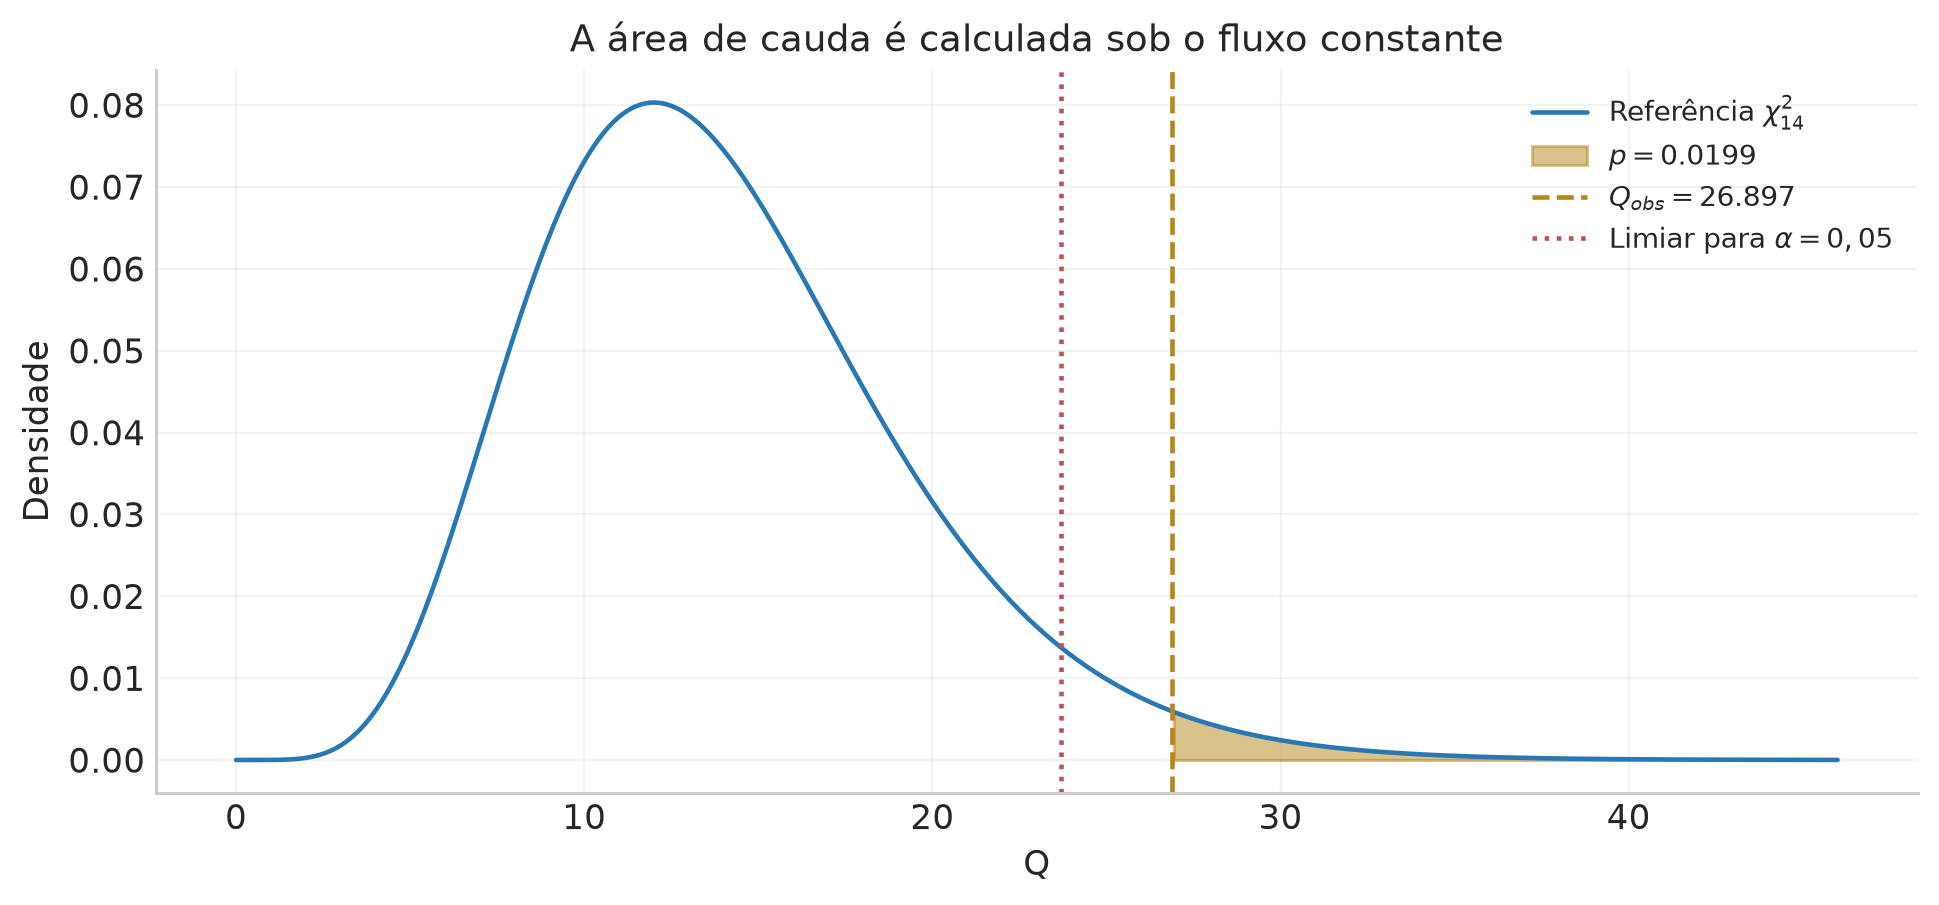

Com $\alpha=0,05$, a decisão é **rejeitar H0 neste nível**. O valor $1-p$ é a área complementar da referência; uma probabilidade para a hipótese exige um modelo bayesiano. A distância padronizada de $Q$ e o equivalente gaussiano de cauda diferem porque a qui-quadrado é assimétrica.

**Conferência com a fonte:** a soma dos fluxos da Tabela 7.1 é 119.8 mJy, fornecendo $\bar x=7.986667$ mJy e $Q=26.896754$. O texto do livro e os slides citam $Q=26,76$. A diferença é pequena, mas os números da tabela produzem o valor calculado aqui; mantivemos todas as medidas como publicadas. As duas versões fornecem uma cauda de aproximadamente 2% e a mesma decisão nos níveis de 5% e 1%.

In [3]:
radio_z_standard = (radio_q-radio_nu)/np.sqrt(2*radio_nu)
radio_z_one = stats.norm.isf(radio_p)
radio_z_two = stats.norm.isf(radio_p/2)
table([['n',radio_n], ['Média (mJy)',radio_mean], ['s amostral (mJy)',radio_s],
       ['sigma instrumental (mJy)',radio_sigma], ['Q observado',radio_q],
       ['Graus de liberdade',radio_nu], ['p da cauda direita',radio_p],
       ['(Q-nu)/sqrt(2 nu)',radio_z_standard],
       ['z normal de cauda unilateral equivalente',radio_z_one],
       ['z normal de caudas bilaterais equivalentes',radio_z_two]],
      ['Quantidade','Valor'], name='radio_resultados')
q = np.linspace(0,46,1000)
fig, ax = plt.subplots(figsize=(8.7,4), layout='constrained')
ax.plot(q,stats.chi2.pdf(q,radio_nu),color=BLUE,label=r'Referência $\chi^2_{14}$')
ax.fill_between(q,0,stats.chi2.pdf(q,radio_nu),where=q>=radio_q,color=GOLD,alpha=.5,
                label=fr'$p={radio_p:.4f}$')
ax.axvline(radio_q,color=GOLD,ls='--',label=fr'$Q_{{obs}}={radio_q:.3f}$')
ax.axvline(stats.chi2.isf(.05,radio_nu),color=RED,ls=':',label=r'Limiar para $\alpha=0,05$')
ax.set(xlabel='Q',ylabel='Densidade',title='A área de cauda é calculada sob o fluxo constante')
ax.legend(); figure_done(fig,'02_radio_cauda')
display(Markdown(fr'Com $\alpha=0,05$, a decisão é **{verdict(radio_p)}**. '
                    r'O valor $1-p$ é a área complementar da referência; uma probabilidade para a hipótese exige um modelo bayesiano. '
                    r'A distância padronizada de $Q$ e o equivalente gaussiano de cauda diferem porque a qui-quadrado é assimétrica.'))
check('Q e variância amostral', np.isclose(radio_q,radio_nu*radio_s**2/radio_sigma**2))
check('Cauda radio por quadratura', np.isclose(radio_p,integrate.quad(lambda v:stats.chi2.pdf(v,radio_nu),radio_q,np.inf)[0]))
display(Markdown(fr'**Conferência com a fonte:** a soma dos fluxos da Tabela 7.1 é {radio_flux.sum():.1f} mJy, '
                    fr'fornecendo $\bar x={radio_mean:.6f}$ mJy e $Q={radio_q:.6f}$. '
                    r'O texto do livro e os slides citam $Q=26,76$. A diferença é pequena, mas os números da tabela '
                    r'produzem o valor calculado aqui; mantivemos todas as medidas como publicadas. '
                    r'As duas versões fornecem uma cauda de aproximadamente 2% e a mesma decisão nos níveis de 5% e 1%.'))

### 1.4 O conjunto de referência em uma simulação

Vamos gerar 30 mil observações hipotéticas de **15 medidas cada**, todas com o mesmo fluxo verdadeiro e $\sigma=2{,}7$. Em cada repetição estimamos a média outra vez e calculamos $Q$. Assim reproduzimos exatamente o procedimento que aplicamos à galáxia.

Para uma referência contínua correta, $F_Q(Q)$ é uniforme em $[0,1]$: $P\{F_Q(Q)\le u\}=P\{Q\le F_Q^{-1}(u)\}=u$. Logo $p=1-F_Q(Q)$ também é uniforme. Uma fração próxima de $\alpha$ dos experimentos sob $H_0$ atravessa o limiar. Em testes discretos, os saltos da CDF costumam produzir probabilidades de rejeição menores ou iguais ao nível nominal.

Se examinarmos $m$ galáxias constantes com esse procedimento, o número esperado de falsos positivos é $m\alpha$ pela linearidade da esperança. Interpretar cada detecção exige considerar quantas buscas foram realizadas.

### 1.5 Student: por que a incerteza do denominador importa?

Para uma amostra normal IID, temos

$$\bar X\sim\mathcal N(\mu,\sigma^2/n),\qquad
U=\frac{(n-1)S^2}{\sigma^2}\sim\chi^2_{n-1}.$$

A média é a componente na direção $\mathbf1$; $S^2$ depende das componentes perpendiculares. Na normal multivariada, essas componentes ortogonais são independentes. Assim, $Z=(\bar X-\mu)/(\sigma/\sqrt n)$ é normal padrão e independente de $U$.

Se $\sigma$ é conhecido, usamos $Z$. Se estimamos a dispersão pelos dados, o denominador também varia:

$$T=\frac{\bar X-\mu}{S/\sqrt n}
=\frac{Z}{\sqrt{U/\nu}},\qquad \nu=n-1.$$

Algumas amostras têm $S$ pequeno e produzem valores de $|T|$ grandes. A Student incorpora essa flutuação e tem caudas mais largas que a normal. **Seu objetivo aqui é fornecer uma distribuição de referência para uma média padronizada por um erro estimado.** A população continua sendo assumida normal; a distribuição de $T$ é que se torna Student.

#### Construção da densidade, com o jacobiano

Partimos de $Z\sim\mathcal N(0,1)$ e $U\sim\chi^2_\nu$ independentes. Transformamos $(z,u)$ em $(t,u)$:

$$z=t\sqrt{u/\nu},\quad \left|\frac{\partial(z,u)}{\partial(t,u)}\right|=\sqrt{u/\nu}.$$

O produto das duas densidades, multiplicado pelo jacobiano, dá

$$f_{T,U}(t,u)=\frac{u^{(\nu+1)/2-1}}{\sqrt{2\pi\nu}\,2^{\nu/2}\Gamma(\nu/2)}
\exp\left[-\frac{u}{2}\left(1+\frac{t^2}{\nu}\right)\right].$$

Para integrar $u$, usamos $a=(\nu+1)/2$, $c=(1+t^2/\nu)/2$ e $v=cu$:

$$\int_0^\infty u^{a-1}e^{-cu}du=c^{-a}\Gamma(a).$$

Substituindo e simplificando os fatores de 2,

$$\boxed{f_{t_\nu}(t)=\frac{\Gamma((\nu+1)/2)}{\sqrt{\nu\pi}\Gamma(\nu/2)}
\left(1+\frac{t^2}{\nu}\right)^{-(\nu+1)/2}},\qquad t\in\mathbb R.$$

A dedução admite qualquer $\nu>0$, inclusive valores fracionários. Na aplicação de uma amostra, $\nu=n-1$ é inteiro; em Welch ele será um grau de liberdade efetivo.

### 1.6 Propriedades da Student, com suas condições

A PDF é simétrica em torno de zero, com moda e mediana em zero. Nas caudas, ela decai como $|t|^{-(\nu+1)}$. Portanto $E[|T|^r]$ é finito quando $r<\nu$: integrar $|t|^{r-\nu-1}$ no infinito exige $r-\nu<0$.

Para $\nu>1$, a simetria e a existência da integral dão $E[T]=0$. Para $\nu>2$, a independência permite calcular

$$E[T^2]=E[Z^2]E[\nu/U]=\nu\frac{\Gamma(\nu/2-1)}{2\Gamma(\nu/2)}
=\frac{\nu}{\nu-2}.$$

Logo $\operatorname{Var}(T)=\nu/(\nu-2)$ para $\nu>2$. Para $1<\nu\le2$, a média existe e o segundo momento diverge: a variância é infinita. Em $\nu=1$ obtemos a Cauchy, cuja média usual e variância são indefinidas. O zero continua sendo seu centro de simetria.

Quando $\nu$ cresce, $U/\nu$ tem média 1 e variância $2/\nu$, concentrando-se em 1. O denominador se estabiliza e $T$ converge para a normal padrão. Esse limite explica por que a aproximação normal melhora com mais informação sobre a dispersão.

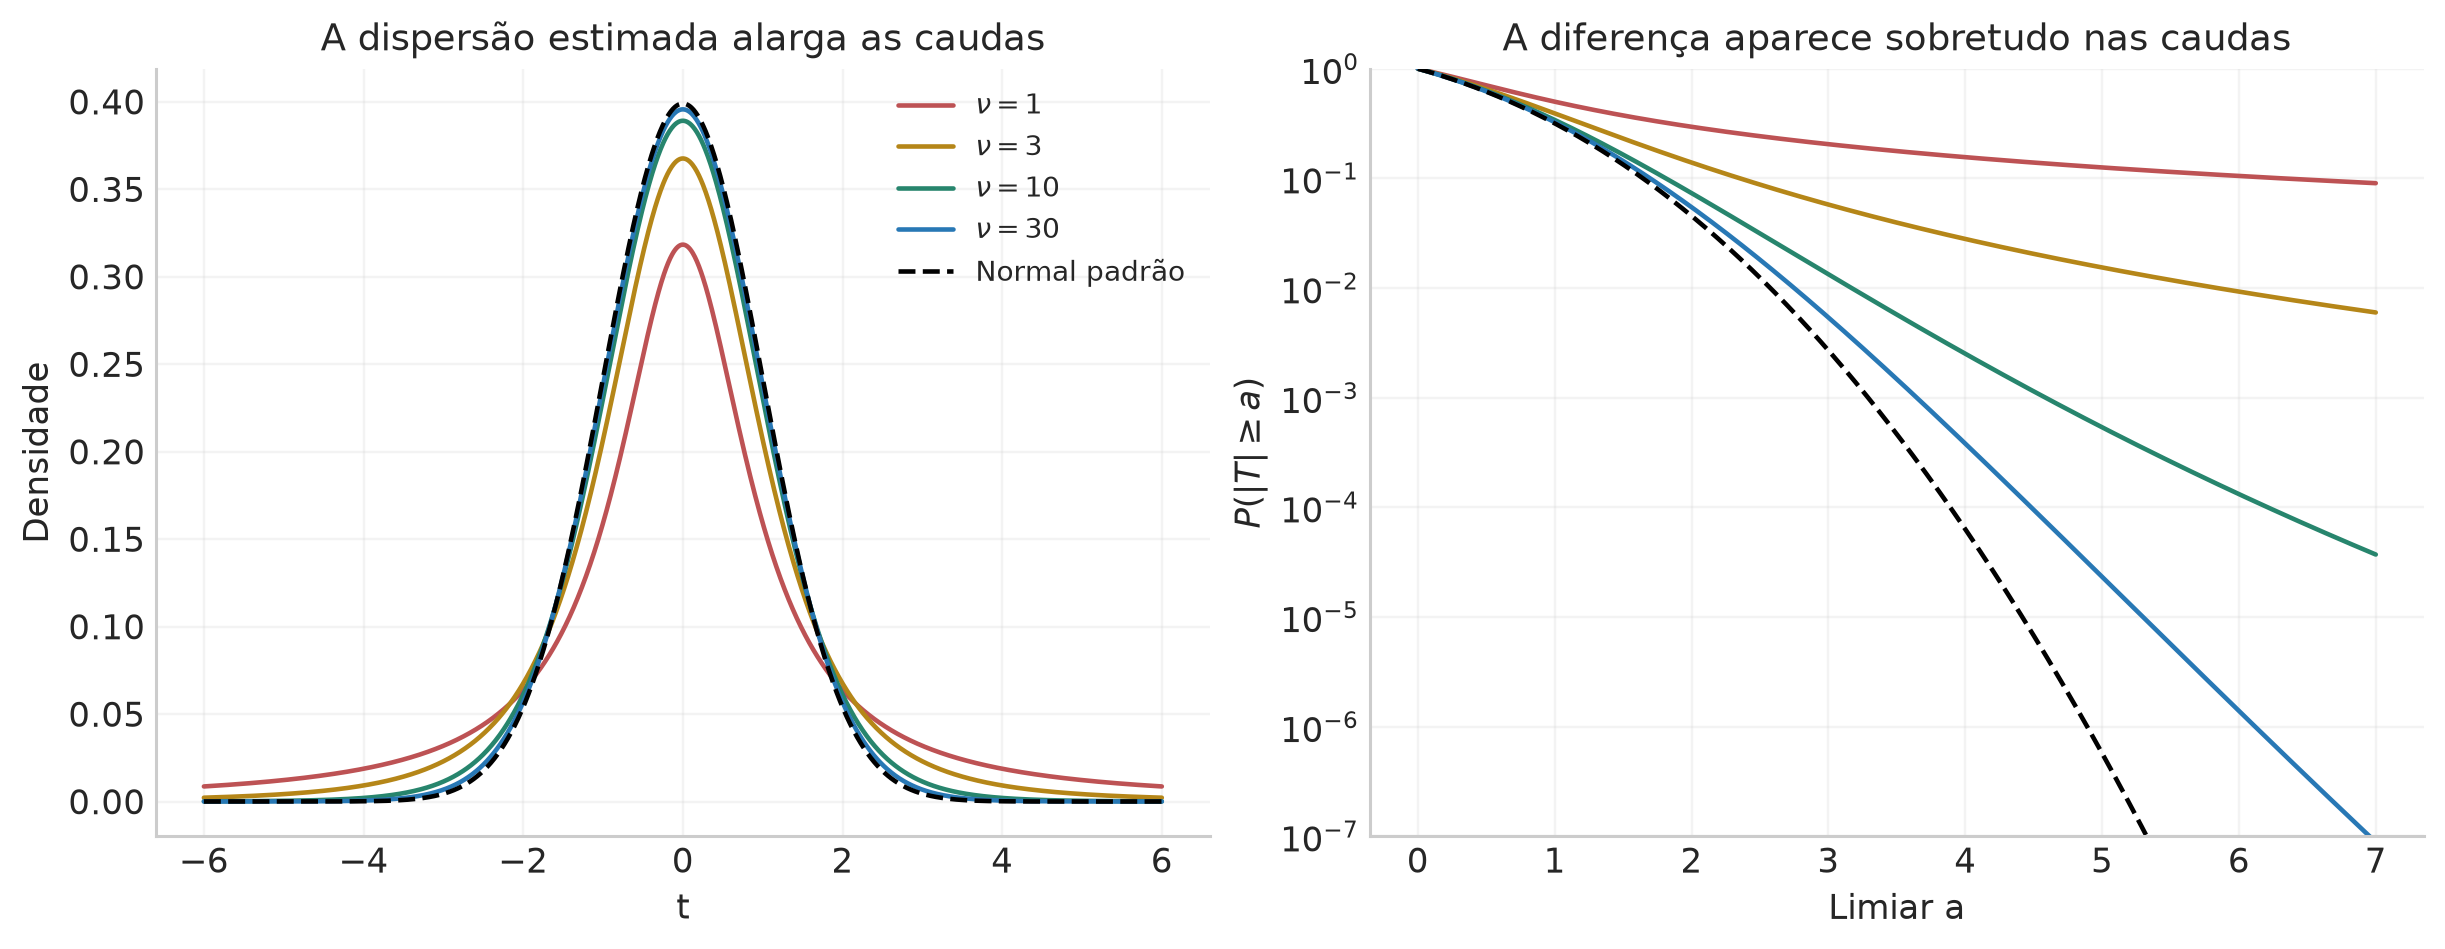

,nu,Média,Variância,Limiar bilateral 5%,P(|T| >= 3)
0,1,indefinida,indefinida,12.7062,0.204833
1,2,0,infinita,4.30265,0.095466
2,3,0,3,3.18245,0.0576689
3,5,0,1.66667,2.57058,0.0300992
4,18,0,1.125,2.10092,0.00768541
5,100,0,1.02041,1.98397,0.00340792


In [6]:
def student_pdf_from_derivation(t,nu):
    t=np.asarray(t)
    logc=special.gammaln((nu+1)/2)-special.gammaln(nu/2)-.5*np.log(nu*np.pi)
    return np.exp(logc-(nu+1)/2*np.log1p(t*t/nu))

tgrid=np.linspace(-6,6,1400)
fig,axes=plt.subplots(1,2,figsize=(11,4.2),layout='constrained')
for nu,color in [(1,RED),(3,GOLD),(10,GREEN),(30,BLUE)]:
    axes[0].plot(tgrid,student_pdf_from_derivation(tgrid,nu),color=color,label=fr'$\nu={nu}$')
    xx=np.linspace(0,7,500)
    axes[1].semilogy(xx,2*stats.t.sf(xx,nu),color=color)
axes[0].plot(tgrid,stats.norm.pdf(tgrid),'k--',lw=1.5,label='Normal padrão')
axes[1].semilogy(xx,2*stats.norm.sf(xx),'k--',lw=1.5)
axes[0].set(xlabel='t',ylabel='Densidade',title='A dispersão estimada alarga as caudas');axes[0].legend()
axes[1].set(xlabel='Limiar a',ylabel=r'$P(|T|\geq a)$',title='A diferença aparece sobretudo nas caudas',ylim=(1e-7,1))
figure_done(fig,'04_student_propriedades')
table([[nu, 'indefinida' if nu<=1 else 0,
        ('indefinida' if nu<=1 else 'infinita') if nu<=2 else nu/(nu-2), stats.t.isf(.025,nu),2*stats.t.sf(3,nu)]
       for nu in [1,2,3,5,18,100]],
      ['nu','Média','Variância','Limiar bilateral 5%','P(|T| >= 3)'],name='student_propriedades')
for nu in [1,3,17.83122374]:
    check(f'PDF Student nu={nu}',np.allclose(student_pdf_from_derivation(tgrid,nu),stats.t.pdf(tgrid,nu)))
    check(f'Normalização Student nu={nu}',np.isclose(integrate.quad(lambda t:student_pdf_from_derivation(t,nu),-np.inf,np.inf)[0],1))

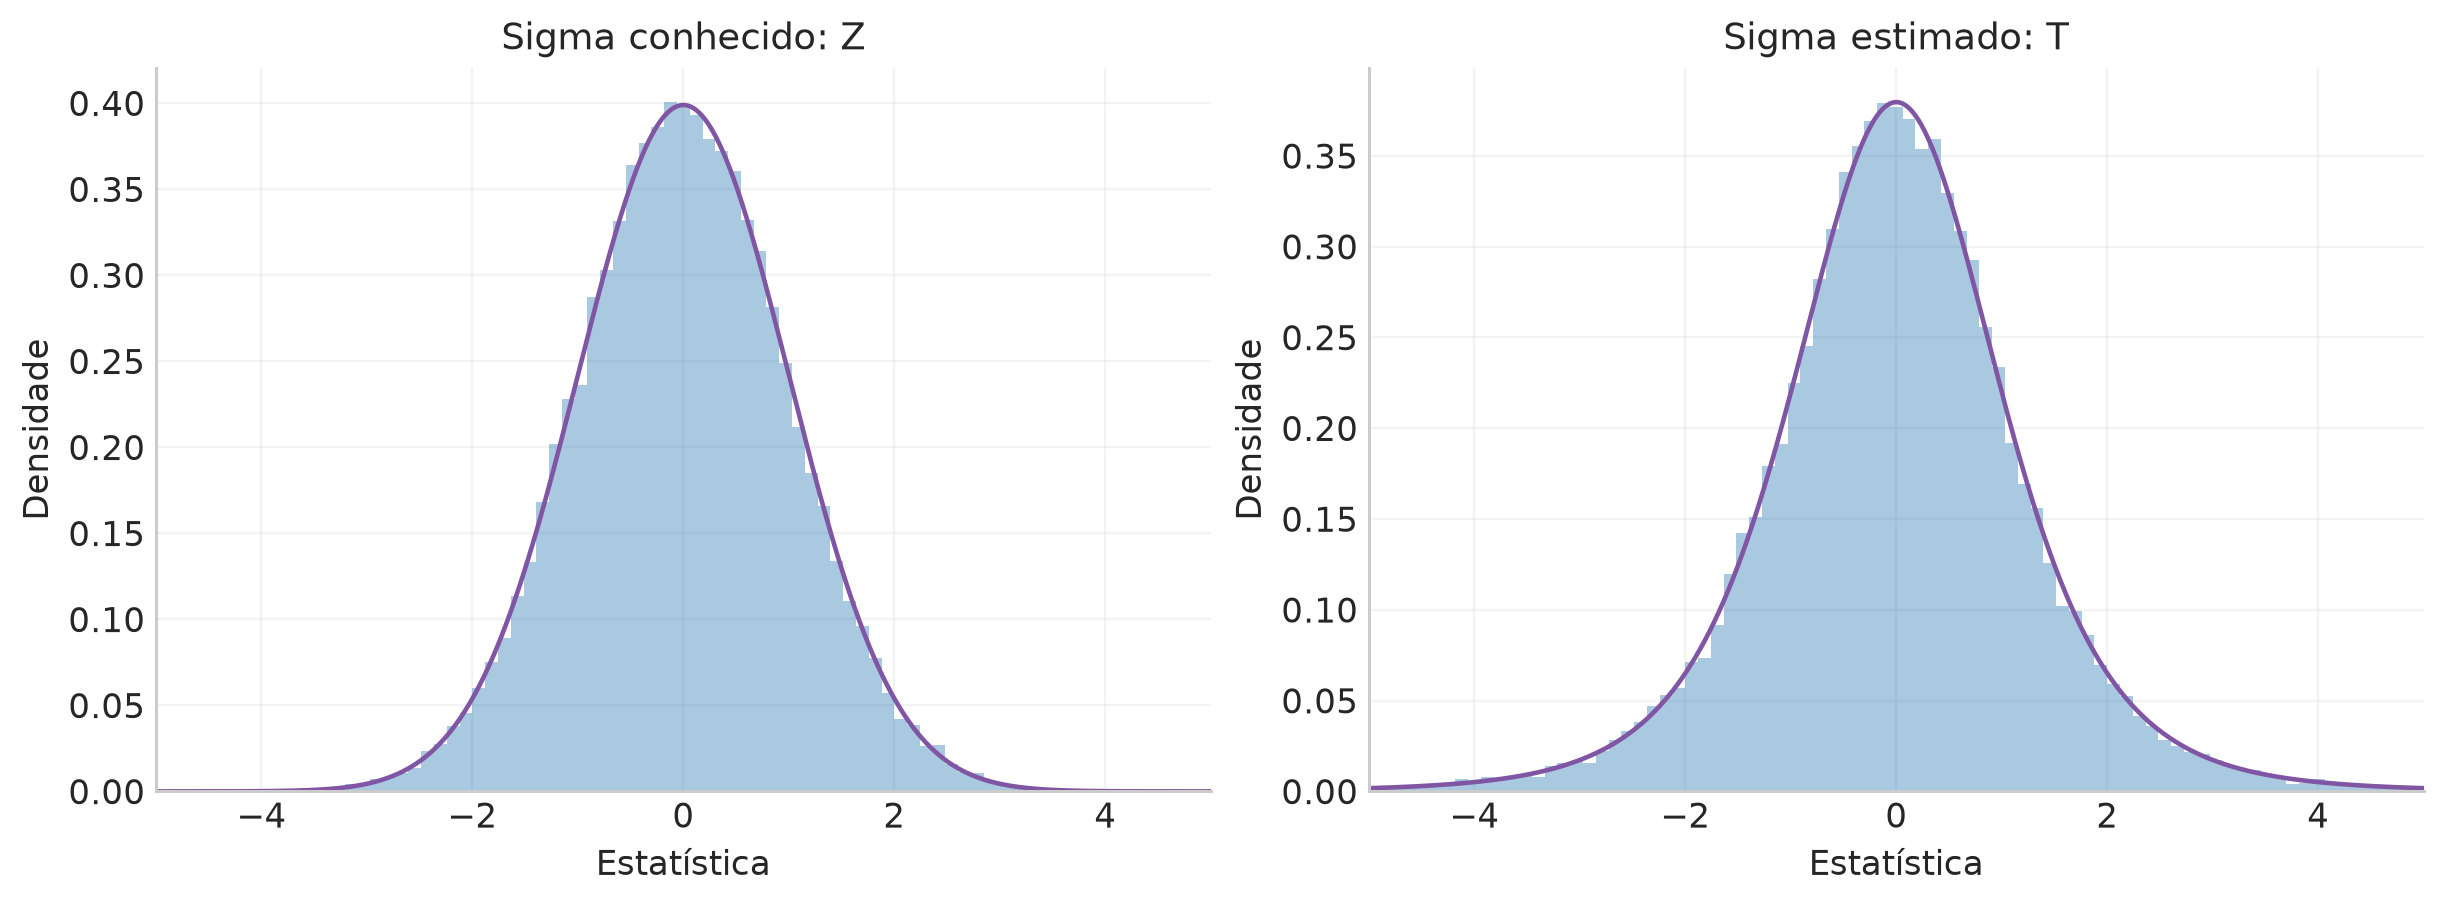

,Procedimento sob H0,Fração de rejeições
0,Normal usada com sigma conhecido,0.04978
1,Student usada com S estimado,0.05038
2,Quantil normal usado com S estimado,0.10724


In [7]:
# A mesma amostra fornece média e S; a simulação verifica essa construção.
rng=rng_for(2); ns=6; mu_known=10.; sigma_known=2.
samples=rng.normal(mu_known,sigma_known,size=(50000,ns))
zsim=(samples.mean(1)-mu_known)/(sigma_known/np.sqrt(ns))
tsim=(samples.mean(1)-mu_known)/(samples.std(1,ddof=1)/np.sqrt(ns))
fig,axes=plt.subplots(1,2,figsize=(11,4),layout='constrained')
for ax,values,pdf,title in [(axes[0],zsim,stats.norm.pdf,'Sigma conhecido: Z'),
                             (axes[1],tsim,lambda t:stats.t.pdf(t,ns-1),'Sigma estimado: T')]:
    ax.hist(values,bins=np.linspace(-6,6,100),density=False,
            weights=np.full(len(values),1/(len(values)*12/99)),color=BLUE,alpha=.4)
    ax.plot(tgrid,pdf(tgrid),color=PURPLE)
    ax.set(xlabel='Estatística',ylabel='Densidade',title=title,xlim=(-5,5))
figure_done(fig,'05_student_amostras')
table([['Normal usada com sigma conhecido',np.mean(np.abs(zsim)>stats.norm.isf(.025))],
       ['Student usada com S estimado',np.mean(np.abs(tsim)>stats.t.isf(.025,ns-1))],
       ['Quantil normal usado com S estimado',np.mean(np.abs(tsim)>stats.norm.isf(.025))]],
      ['Procedimento sob H0','Fração de rejeições'],name='student_calibracao');

### 1.7 O “$Z$ conjunto”: uma combinação linear de duas médias — slide 95

Considere duas amostras independentes, de tamanhos $n_1,n_2$, com médias populacionais $\mu_1,\mu_2$ e variâncias $\sigma_1^2,\sigma_2^2$. Chamaremos a diferença de médias amostrais de $D=\bar X_1-\bar X_2$. A esperança e a variância são

$$E[D]=\mu_1-\mu_2=\Delta,\qquad
v_D=\operatorname{Var}(D)=\frac{\sigma_1^2}{n_1}+\frac{\sigma_2^2}{n_2}.$$

A soma no segundo resultado vem de $\operatorname{Var}(A-B)=\operatorname{Var}(A)+\operatorname{Var}(B)-2\operatorname{Cov}(A,B)$ e da independência.

Podemos ver a origem do $Z$ do slide explicitamente. Escrevendo $v_j=\sigma_j^2/n_j$,

$$D-\Delta=\sqrt{v_1}Z_1-\sqrt{v_2}Z_2,
\qquad Z=\frac{\sqrt{v_1}Z_1-\sqrt{v_2}Z_2}{\sqrt{v_1+v_2}}.$$

Os coeficientes quadráticos somam 1. Como $Z_1,Z_2$ são normais padrão independentes, sua combinação é normal, com média zero e variância 1. Esse é o “$Z$ conjunto”: **uma nova estatística escalar, formada pela diferença padronizada**, e não o produto $Z_1Z_2$ nem uma densidade conjunta bidimensional. Para populações normais, o resultado é exato para qualquer tamanho de amostra. Para outras populações com variância finita, o TCL pode fornecer uma aproximação, cuja qualidade depende da forma da distribuição e de $n_1,n_2$.

Sob $H_0:\Delta=0$, temos $Z=D/\sqrt{v_D}$. Se os dados forem pareados, a covariância precisa ser considerada: nesse caso trabalhamos diretamente com as diferenças por par.


### 1.8 De $Z$ a Welch: estimar a variância da diferença

Com variâncias desconhecidas, substituímos $v_D$ por

$$W=\frac{S_1^2}{n_1}+\frac{S_2^2}{n_2},\qquad
T_W=\frac{D-\Delta_0}{\sqrt W}.$$

Para dados normais, média e variância amostrais são independentes em cada grupo. Assim, o numerador é independente de $W$. O detalhe é que $W$ soma duas qui-quadrados com **escalas geralmente diferentes**; uma qui-quadrado exata para essa soma exige condições adicionais. Welch aproxima sua distribuição por $c\chi^2_\nu$.

Vamos obter $\nu$ por igualdade de momentos. Como $\operatorname{Var}(S_j^2)=2\sigma_j^4/(n_j-1)$,

$$E[W]=v_1+v_2,\qquad
\operatorname{Var}(W)=2\left[\frac{v_1^2}{n_1-1}+\frac{v_2^2}{n_2-1}\right].$$

Para $c\chi^2_\nu$, a média é $c\nu$ e a variância é $2c^2\nu$. Dividindo o dobro do quadrado da média pela variância, obtemos

$$\nu=\frac{(v_1+v_2)^2}{v_1^2/(n_1-1)+v_2^2/(n_2-1)}.$$

Substituímos as variâncias populacionais pelas amostrais para calcular

$$\boxed{\widehat\nu=\frac{(s_1^2/n_1+s_2^2/n_2)^2}
{(s_1^2/n_1)^2/(n_1-1)+(s_2^2/n_2)^2/(n_2-1)}},\qquad T_W\approx t_{\widehat\nu}.$$

O denominador contém uma **soma**, como exige a variância de termos independentes. Essa é a expressão usada no código, inclusive ao reler a fórmula dos slides 83 e 95. O símbolo $S_p$ no exemplo dos slides representa $\sqrt W$, o erro padrão estimado da diferença.

Se a igualdade das variâncias populacionais fizer parte do modelo, existe uma construção exata: $S_{\rm pool}^2=[(n_1-1)S_1^2+(n_2-1)S_2^2]/(n_1+n_2-2)$ e $T=(D-\Delta_0)/[S_{\rm pool}\sqrt{1/n_1+1/n_2}]\sim t_{n_1+n_2-2}$. No rio, seguiremos Welch, que permite dispersões diferentes.

In [8]:
# Tabela 7.2 do Gregory, p. 168. Unidade: partes por milhão (ppm).
river1=np.array([13.2,13.8,8.7,9,8.6,9.9,14.2,9.7,10.7,8.3,8.5,9.2])
river2=np.array([8.9,9.1,8.3,6,7.7,9.9,9.9,8.9])
def welch_summary(x,y):
    n1,n2=len(x),len(y)
    a,b=np.var(x,ddof=1)/n1,np.var(y,ddof=1)/n2
    diff=np.mean(x)-np.mean(y); se=np.sqrt(a+b)
    nu=(a+b)**2/(a*a/(n1-1)+b*b/(n2-1))
    return diff,se,nu,diff/se
river_diff,river_se,river_nu,river_t=welch_summary(river1,river2)
river_p_one=stats.t.sf(river_t,river_nu)
river_p_two=2*stats.t.sf(abs(river_t),river_nu)
river_ci=river_diff+np.array([-1,1])*stats.t.isf(.025,river_nu)*river_se
table(pd.DataFrame({'Local 1 (ppm)':pd.Series(river1),'Local 2 (ppm)':pd.Series(river2)}),name='rio_dados')
table([[j,len(x),x.mean(),x.var(ddof=1),x.std(ddof=1)/np.sqrt(len(x))]
       for j,x in [('Local 1',river1),('Local 2',river2)]],
      ['Amostra','n','Média (ppm)','s² (ppm²)','Erro padrão da média (ppm)'],name='rio_resumo')
table([['Diferença observada (ppm)',river_diff],['Erro padrão da diferença (ppm)',river_se],
       ['Graus de liberdade de Welch',river_nu],['t observado',river_t],
       ['p unilateral: mu1 > mu2',river_p_one],['p bilateral: mu1 != mu2',river_p_two],
       ['IC 95%: limite inferior (ppm)',river_ci[0]],['IC 95%: limite superior (ppm)',river_ci[1]]],
      ['Quantidade','Valor'],name='rio_teste')
check('Welch reproduz SciPy',np.isclose(river_p_two,stats.ttest_ind(river1,river2,equal_var=False).pvalue))
check('Student simétrica: caudas',np.isclose(river_p_two,2*river_p_one))

,Local 1 (ppm),Local 2 (ppm)
0,13.2,8.9
1,13.8,9.1
2,8.7,8.3
3,9,6
4,8.6,7.7
5,9.9,9.9
6,14.2,9.9
7,9.7,8.9
8,10.7,NaN
9,8.3,NaN


,Amostra,n,Média (ppm),s² (ppm²),Erro padrão da média (ppm)
0,Local 1,12,10.3167,4.7397,0.62847
1,Local 2,8,8.5875,1.63839,0.452547


,Quantidade,Valor
0,Diferença observada (ppm),1.72917
1,Erro padrão da diferença (ppm),0.774451
2,Graus de liberdade de Welch,17.8312
3,t observado,2.23277
4,p unilateral: mu1 > mu2,0.0193158
5,p bilateral: mu1 != mu2,0.0386317
6,IC 95%: limite inferior (ppm),0.101002
7,IC 95%: limite superior (ppm),3.35733


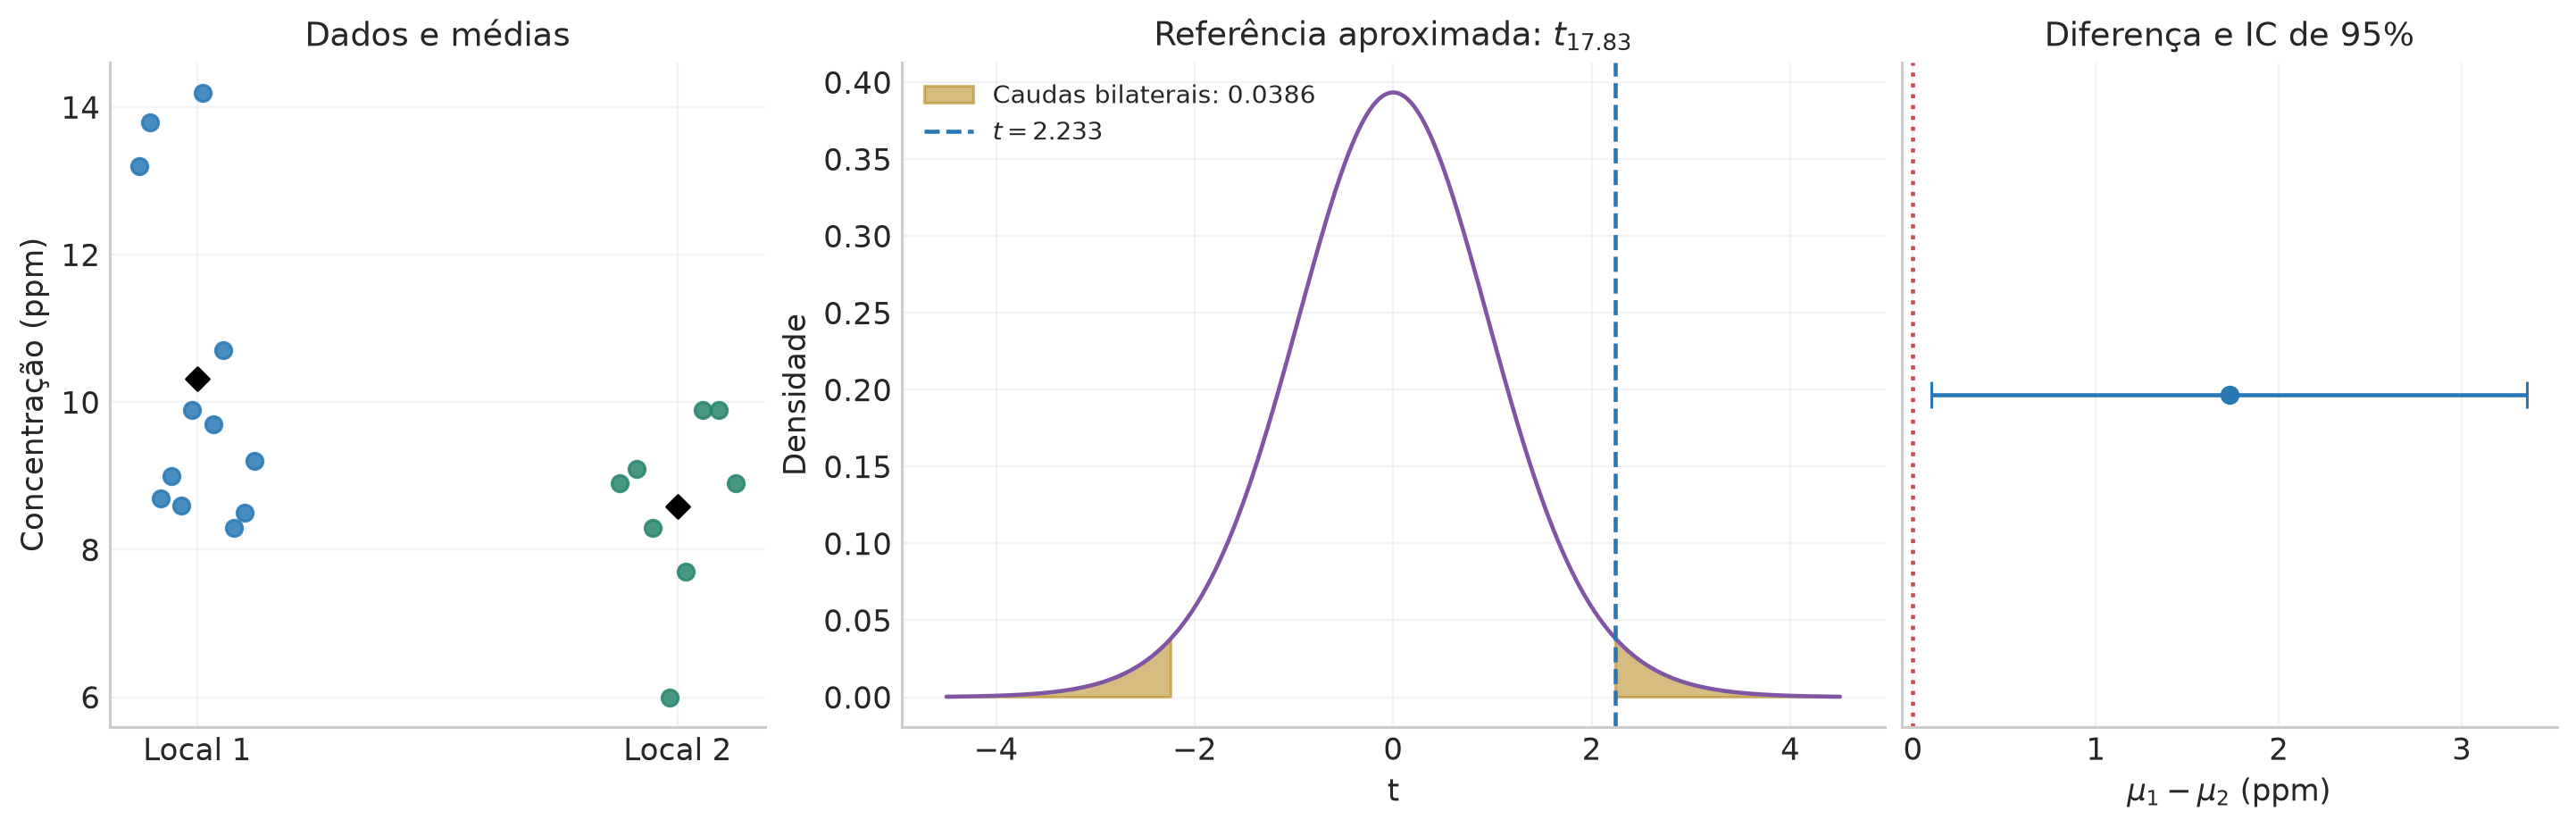

A diferença estimada é **1.729 ppm**, com IC frequentista de 95% **[0.101; 3.357] ppm**. O teste bilateral fornece $p=0.038632$ e atravessa o limiar de 5%. Esse valor reproduz o Gregory; o número 0,0398 do slide 97 é uma discrepância de transcrição. As duas caudas calculadas com os dados somam aproximadamente 0,03863. A interpretação depende de amostras independentes e de uma aproximação normal adequada em cada local; com 12 e 8 medidas, o TCL por si só oferece uma justificativa limitada.

In [9]:
fig,axes=plt.subplots(1,3,figsize=(13,4.1),layout='constrained',gridspec_kw={'width_ratios':[1,1.5,1]})
for j,(x,col) in enumerate([(river1,BLUE),(river2,GREEN)]):
    jitter=np.linspace(-.12,.12,len(x))
    axes[0].scatter(j+jitter,x,color=col,alpha=.85)
    axes[0].scatter(j,x.mean(),marker='D',color='black',s=35,zorder=4)
axes[0].set(xticks=[0,1],xticklabels=['Local 1','Local 2'],ylabel='Concentração (ppm)',title='Dados e médias')
tt=np.linspace(-4.5,4.5,1000); pdf=stats.t.pdf(tt,river_nu)
axes[1].plot(tt,pdf,color=PURPLE)
axes[1].fill_between(tt,0,pdf,where=np.abs(tt)>=abs(river_t),color=GOLD,alpha=.55,
                     label=fr'Caudas bilaterais: {river_p_two:.4f}')
axes[1].axvline(river_t,color=BLUE,ls='--',label=fr'$t={river_t:.3f}$')
axes[1].set(xlabel='t',ylabel='Densidade',title=fr'Referência aproximada: $t_{{{river_nu:.2f}}}$');axes[1].legend()
axes[2].errorbar([river_diff],[0],xerr=[[river_diff-river_ci[0]],[river_ci[1]-river_diff]],
                 fmt='o',color=BLUE,capsize=5)
axes[2].axvline(0,color=RED,ls=':');axes[2].set(xlabel=r'$\mu_1-\mu_2$ (ppm)',yticks=[],title='Diferença e IC de 95%')
figure_done(fig,'06_rio_welch')
display(Markdown(fr'A diferença estimada é **{river_diff:.3f} ppm**, com IC frequentista de 95% '
                    fr'**[{river_ci[0]:.3f}; {river_ci[1]:.3f}] ppm**. '
                    fr'O teste bilateral fornece $p={river_p_two:.6f}$ e atravessa o limiar de 5%. '
                    r'Esse valor reproduz o Gregory; o número 0,0398 do slide 97 é uma discrepância de transcrição. '
                    r'As duas caudas calculadas com os dados somam aproximadamente 0,03863. '
                    r'A interpretação depende de amostras independentes e de uma aproximação normal adequada em cada local; '
                    r'com 12 e 8 medidas, o TCL por si só oferece uma justificativa limitada.'))

### 1.9 Qual cauda responde à pergunta? — slide 97

| Pergunta científica e alternativa definida previamente | Estatística | Região de discrepância |
|:--|:--|:--|
| Fluxo com variabilidade adicional | $Q=\sum(X_i-\bar X)^2/\sigma^2$ | Valores altos de $Q$ |
| Maior concentração no local 1: $\mu_1>\mu_2$ | $T_W$ | Cauda direita |
| Menor concentração no local 1: $\mu_1<\mu_2$ | $T_W$ | Cauda esquerda |
| Diferença em qualquer direção: $\mu_1\ne\mu_2$ | $T_W$ | Ambas as caudas |

Para uma Student simétrica, $p_{\rm bilateral}=2P(T\ge|t_{\rm obs}|)$. Para uma alternativa unilateral à direita, usamos $P(T\ge t_{\rm obs})$ mesmo quando o valor observado é negativo. A direção faz parte do problema antes de observar o sinal do resultado. Em distribuições assimétricas ou discretas, precisamos especificar o que significa “tão extremo”: dobrar uma cauda é uma convenção possível, e outras ordenações podem fornecer valores diferentes.

O intervalo para a diferença e o teste bilateral expressam a mesma decisão quando usam a mesma Student e o mesmo nível: zero fora do IC de 95% equivale a $p<0{,}05$. O tamanho da diferença em ppm continua essencial para discutir a relevância ambiental.

Para visualizar potência, tomemos uma versão normal com erro padrão conhecido $s_e$. Sob diferença verdadeira $\Delta$, a estatística $D/s_e$ é normal de média $\Delta/s_e$ e variância 1. Rejeitamos nas regiões $D/s_e>z_{1-\alpha/2}$ ou $D/s_e<-z_{1-\alpha/2}$. Somar suas probabilidades dá

$$\operatorname{Potência}(\Delta)=1-\Phi\!\left(z_{1-\alpha/2}-\frac{\Delta}{s_e}\right)
+\Phi\!\left(-z_{1-\alpha/2}-\frac{\Delta}{s_e}\right),$$

onde $\Phi$ é a CDF normal padrão. É a curva ilustrativa da próxima figura; no ponto $\Delta=0$, recuperamos a taxa de erro tipo I $\alpha$.

,Procedimento sob médias iguais,Fração de rejeições a 5%
0,Welch: nu estimado em cada repetição,0.049325
1,Normal: mesmo denominador estimado,0.0657


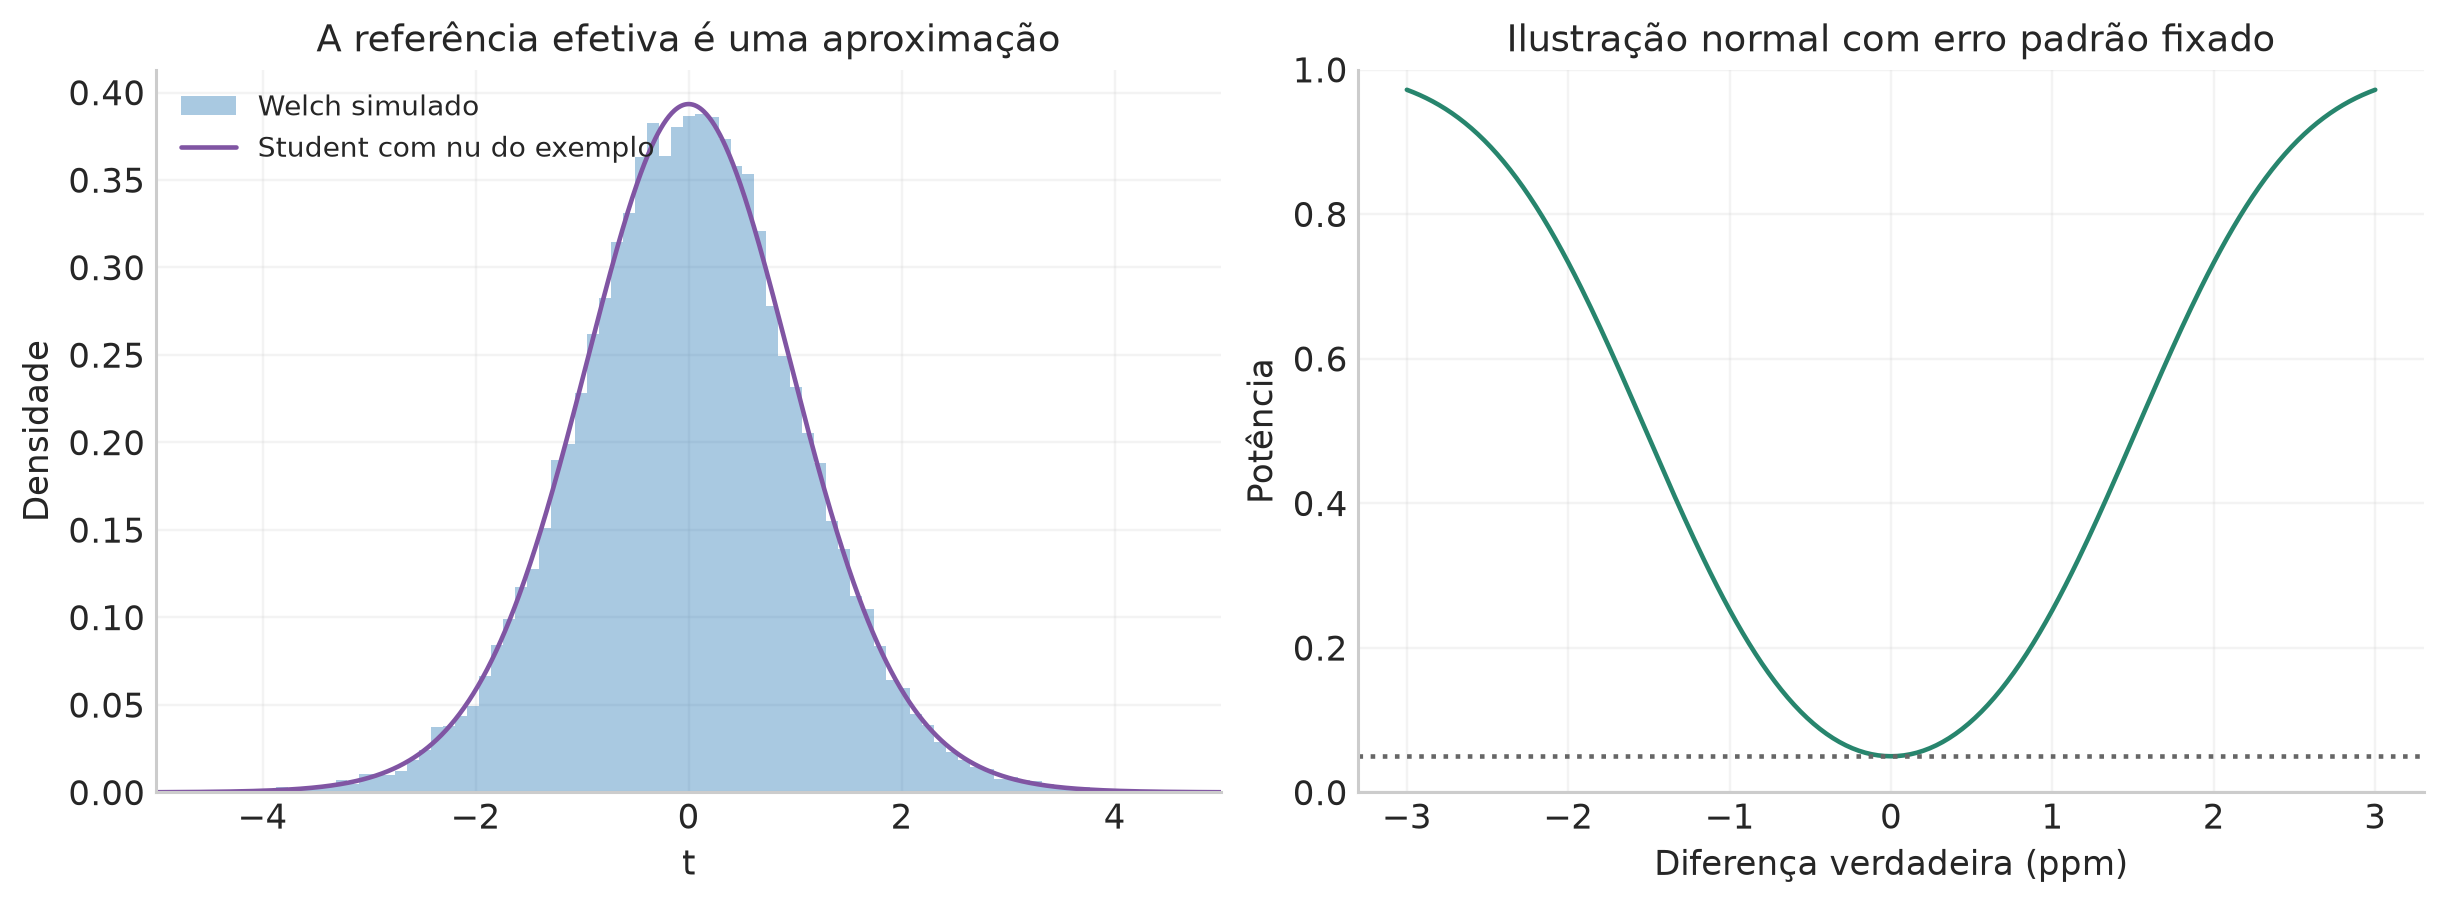

A curva de potência usa um experimento normal com erro padrão conhecido fixado no valor do exemplo. Ela ilustra a dependência no efeito; a potência exata de Welch exige considerar também os denominadores aleatórios.

In [10]:
# Controle numérico da aproximação de Welch sob populações normais com variâncias diferentes.
rng=rng_for(3); B=40000
x=rng.normal(0,river1.std(ddof=1),size=(B,len(river1)))
y=rng.normal(0,river2.std(ddof=1),size=(B,len(river2)))
a=x.var(1,ddof=1)/x.shape[1]; b=y.var(1,ddof=1)/y.shape[1]
tt=(x.mean(1)-y.mean(1))/np.sqrt(a+b)
nu=(a+b)**2/(a*a/(x.shape[1]-1)+b*b/(y.shape[1]-1))
pw=2*stats.t.sf(abs(tt),nu)
table([['Welch: nu estimado em cada repetição',np.mean(pw<.05)],
       ['Normal: mesmo denominador estimado',np.mean(2*stats.norm.sf(abs(tt))<.05)]],
      ['Procedimento sob médias iguais','Fração de rejeições a 5%'],name='welch_calibracao')
fig,axes=plt.subplots(1,2,figsize=(11,4),layout='constrained')
axes[0].hist(tt,bins=np.linspace(-5,5,90),density=True,color=BLUE,alpha=.4,label='Welch simulado')
axes[0].plot(tgrid,stats.t.pdf(tgrid,river_nu),color=PURPLE,label='Student com nu do exemplo')
axes[0].set(xlabel='t',ylabel='Densidade',title='A referência efetiva é uma aproximação',xlim=(-5,5));axes[0].legend()
effect=np.linspace(-3,3,301); se_fixed=river_se; critical=stats.norm.isf(.025)
power=stats.norm.sf(critical-effect/se_fixed)+stats.norm.cdf(-critical-effect/se_fixed)
axes[1].plot(effect,power,color=GREEN);axes[1].axhline(.05,color='0.4',ls=':')
axes[1].set(xlabel='Diferença verdadeira (ppm)',ylabel='Potência',title='Ilustração normal com erro padrão fixado',ylim=(0,1))
figure_done(fig,'07_welch_e_potencia')
display(Markdown('A curva de potência usa um experimento normal com erro padrão conhecido fixado no valor do exemplo. '
                 'Ela ilustra a dependência no efeito; a potência exata de Welch exige considerar também os denominadores aleatórios.'))

## Parte 2 — Comparar distribuições completas
### 2.1 Três perguntas, três formas de organizar os dados — slides 98–99

Comparar médias responde apenas a uma característica das populações. Duas distribuições podem ter a mesma média e dispersões, assimetrias ou caudas diferentes. Agora perguntamos se a **distribuição inteira** é compatível com um modelo, ou se dois grupos compartilham uma distribuição.

| Exemplo | Dado individual | Pergunta | Ferramenta principal |
|:--|:--|:--|:--|
| Estrelas | Direção no céu | A distribuição observada acompanha a área disponível? | CDF e Kolmogorov–Smirnov |
| Escolaridade | Categoria de instrução | As proporções por categoria são iguais em dois grupos? | Tabela de contingência e Pearson |
| Notas | Valor registrado em uma escala limitada | Um modelo normal com observação discretizada descreve a forma? | Contagens por intervalo e aderência |

**Goodness of fit** significa **aderência**: avaliar a compatibilidade dos dados com uma distribuição proposta. É o nome de uma pergunta e de uma família de procedimentos. O teste de Pearson usa contagens; KS usa a diferença entre acumuladas. Uma distribuição contínua pode ser comparada com dados agrupados integrando sua PDF em cada intervalo. A multinomial descreve então o **vetor das contagens**, enquanto a normal, Poisson ou outra distribuição descreve o **dado individual**. Na Parte 3 vamos construir essa conexão desde o início.

### 2.2 Estrelas: uniformidade na esfera exige considerar a área

Em coordenadas galácticas, $\ell$ é a longitude e $b$ a latitude. O elemento de área na esfera unitária é

$$d\Omega=\cos b\,db\,d\ell.$$

Uma população isotrópica tem densidade $1/(4\pi)$ por unidade de ângulo sólido. Integrando a longitude de 0 a $2\pi$,

$$f_B(b)=\frac12\cos b,\quad -\pi/2\le b\le\pi/2,
\qquad F_B(b)=\frac{1+\sin b}{2}.$$

Faixas de mesma largura em latitude possuem áreas diferentes. A mudança $u=(1+\sin b)/2$ tem $du=(\cos b/2)db$, de modo que **$U$ é uniforme em $[0,1]$ sob isotropia**. Essa transformação retira a geometria da comparação.

Usaremos um recorte real do **HYG v4.0, David Nash/Astronexus**: todas as 5.070 entradas estelares com magnitude visual $m_V\le6$, excluído o Sol, com ascensão reta e declinação disponíveis. O HYG reúne catálogos astrométricos, entre eles Hipparcos. A magnitude limita o brilho aparente do recorte; essa seleção faz parte do objeto analisado. O teste descreve a compatibilidade do **catálogo selecionado** com um modelo isotrópico IID. Inferir a população física requer também a função de seleção e possíveis dependências entre fontes.

Fontes e licença do recorte: [dados HYG v4.0](https://github.com/astronexus/HYG-Database/blob/main/hyg/CURRENT/hygdata_v40.csv.gz), [descrição dos campos](https://github.com/astronexus/HYG-Database/blob/main/hyg/README.md), [CC BY-SA 4.0](https://creativecommons.org/licenses/by-sa/4.0/). Os dados incorporados abaixo são uma redistribuição desse recorte sob a mesma licença. Data de acesso: 28/10/2026.

A célula de dados contém somente o instantâneo do catálogo comprimido para manter o arquivo manejável. A descompressão recupera o CSV; os cálculos científicos aparecem abertos nas células seguintes. O resumo SHA-256 permite identificar exatamente o recorte utilizado.

In [11]:
# Instantâneo de dados reais: HIP, ascensão reta em horas, declinação em graus e magnitude V.
stars_payload = (
    '...'
)
stars_csv = zlib.decompress(base64.b64decode(stars_payload))
stars_sha256 = 'dcabb4e7c93598215f448097ec2c4acb616539509c64a22f0612eba42d1eaf67'
check('Integridade do recorte estelar', hashlib.sha256(stars_csv).hexdigest()==stars_sha256)
stars = pd.read_csv(StringIO(stars_csv.decode('utf-8')))
check('Recorte HYG completo',len(stars)==5070 and stars['mag'].max()<=6)
print('Estrelas:',len(stars),'| SHA-256:',stars_sha256)
display(stars.head())

Estrelas: 5070 | SHA-256: dcabb4e7c93598215f448097ec2c4acb616539509c64a22f0612eba42d1eaf67


,hip,ra,dec,mag
0,88.0,0.017941,-48.809876,5.71
1,107.0,0.022255,-50.337373,5.53
2,122.0,0.026616,-77.065724,4.78
3,124.0,0.026949,61.222801,5.58
4,145.0,0.030402,-3.027504,5.13


### 2.3 Transformação de coordenadas e a CDF empírica

A ascensão reta do catálogo vem em horas: $\alpha=15\,\mathrm{RA}$ em graus. Com declinação $\delta$, a direção cartesiana é

$$\mathbf r=(\cos\delta\cos\alpha,\cos\delta\sin\alpha,\sin\delta).$$

Aplicamos a rotação fixa do sistema equatorial J2000 para o galáctico, indicada no código. De $\mathbf r_G=(x_G,y_G,z_G)$ recuperamos $b=\arcsin z_G$ e $\ell=\operatorname{atan2}(y_G,x_G)$. A matriz apenas muda a base: seu produto por sua transposta é a identidade, preservando normas e áreas. Como conferência independente, a latitude também satisfaz

$$\sin b=\sin\delta\sin\delta_{\rm NGP}+\cos\delta\cos\delta_{\rm NGP}
\cos(\alpha-\alpha_{\rm NGP}),$$

com o polo norte galáctico em $(\alpha_{\rm NGP},\delta_{\rm NGP})=(192{,}85948^\circ,27{,}12825^\circ)$; essa é a terceira linha da mesma rotação. A convenção está documentada nas [transformações galácticas do Astropy](https://docs.astropy.org/en/stable/coordinates/transforming.html).

Para uma amostra $u_1,\ldots,u_n$, a acumulada empírica é

$$\widehat F_n(u)=\frac1n\sum_{i=1}^n\mathbf1(u_i\le u).$$

Ela dá um salto de $1/n$ em cada observação. Com os dados ordenados $u_{(i)}$, a maior diferença para uma CDF contínua $F_0$ inclui os dois lados de cada salto:

$$D_n=\max_i\left\{\frac{i}{n}-F_0(u_{(i)}),\ F_0(u_{(i)})-\frac{i-1}{n}\right\}.$$

Esse é o **teste KS de uma amostra**. Sob uma referência contínua completamente especificada, transformar por $F_0$ leva a uniformes; por isso a distribuição de $D_n$ depende apenas de $n$. Para a hipótese estelar, $F_0(u)=u$. A uniformidade dessa marginal é uma condição necessária de isotropia; a distribuição conjunta em longitude e latitude contém informação adicional.

O teorema de Kolmogorov fornece, para amostras grandes, a cauda

$$P(\sqrt n D_n\ge z)\longrightarrow 2\sum_{j=1}^{\infty}(-1)^{j-1}e^{-2j^2z^2}.$$

A universalidade vem da transformação para uniformes; a série é o resultado do teorema de limite para a CDF empírica. Usaremos essa referência assintótica no catálogo e conferiremos sua avaliação pela série. Para ver a construção sem depender desse teorema, também podemos simular muitas amostras uniformes de tamanho fixo e calcular seus $D_n$; faremos essa conferência em uma amostra de tamanho 200, cujo quantil de 95% é acessível por simulação.

,Quantidade,Valor
0,Número de estrelas,5070
1,D KS,0.07915665
2,p KS assintótico sob modelo IID isotrópico,5.1067814e-28
3,Fração com |b| < 15 graus,0.36982249
4,Fração isotrópica esperada nessa faixa,0.25881905


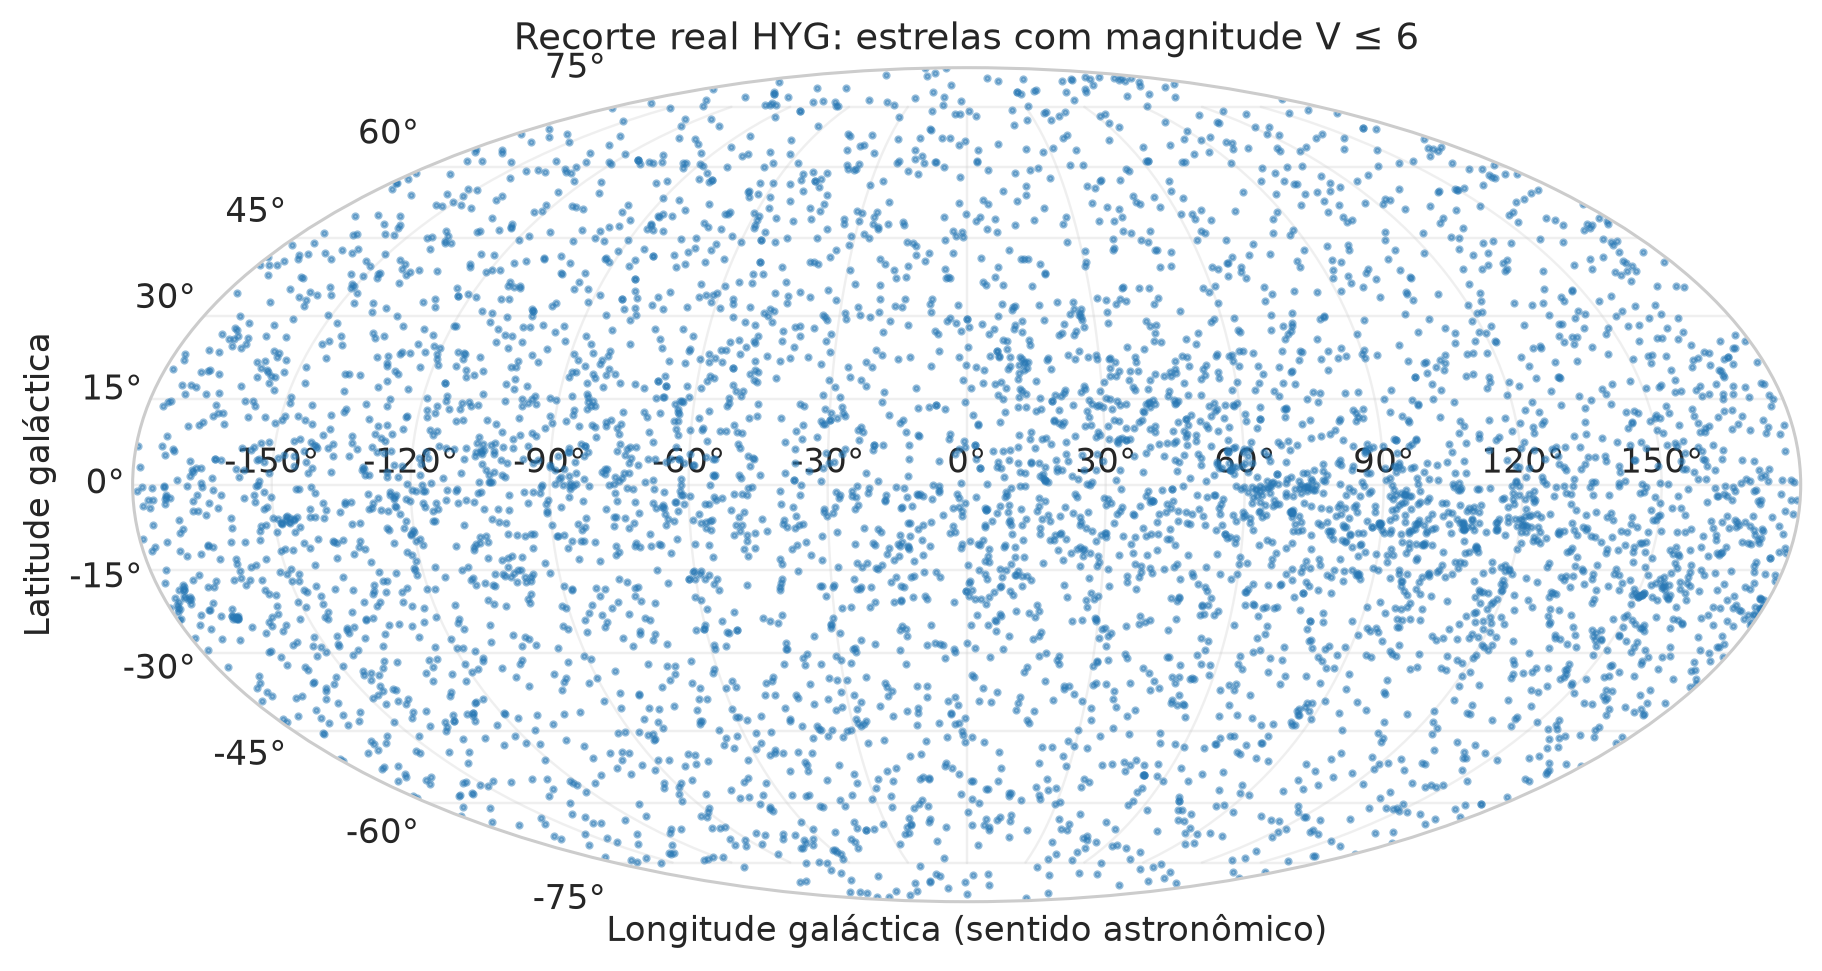

In [12]:
R_eq_gal=np.array([[-.0548755604,-.8734370902,-.4838350155],
                   [.4941094279,-.4448296300,.7469822445],
                   [-.8676661490,-.1980763734,.4559837762]])
alpha=np.deg2rad(15*stars.ra.to_numpy()); delta=np.deg2rad(stars.dec.to_numpy())
r_eq=np.array([np.cos(delta)*np.cos(alpha),np.cos(delta)*np.sin(alpha),np.sin(delta)])
r_gal=R_eq_gal@r_eq
star_b=np.arcsin(np.clip(r_gal[2],-1,1))
star_l=np.arctan2(r_gal[1],r_gal[0])
star_u=(1+np.sin(star_b))/2
star_n=len(star_u)
def ks_distance(values,cdf):
    x=np.sort(np.asarray(values)); n=len(x); fx=cdf(x)
    return max(np.max(np.arange(1,n+1)/n-fx),np.max(fx-np.arange(n)/n))
star_D=ks_distance(star_u,lambda u:u)
star_ks=stats.kstest(star_u,'uniform',method='asymp')
check('Rotação preserva a métrica',np.allclose(R_eq_gal@R_eq_gal.T,np.eye(3),atol=2e-10))
check('KS calculado à mão',np.isclose(star_D,star_ks.statistic))
ks_j=np.arange(1,80)
star_ks_series=2*np.sum((-1.)**(ks_j-1)*np.exp(-2*ks_j**2*star_n*star_D**2))
check('Cauda KS pela série de Kolmogorov',np.isclose(star_ks_series,star_ks.pvalue,rtol=1e-10,atol=0))
table([['Número de estrelas',star_n],['D KS',star_D],
       ['p KS assintótico sob modelo IID isotrópico',star_ks.pvalue],
       ['Fração com |b| < 15 graus',np.mean(np.abs(star_b)<np.deg2rad(15))],
       ['Fração isotrópica esperada nessa faixa',np.sin(np.deg2rad(15))]],
      ['Quantidade','Valor'],name='estrelas_ks',digits=8)
fig=plt.figure(figsize=(11,4.3),layout='constrained');ax=fig.add_subplot(111,projection='mollweide')
ax.scatter(-star_l,star_b,s=2.8,color=BLUE,alpha=.5,rasterized=True)
ax.grid(alpha=.3);ax.set(title='Recorte real HYG: estrelas com magnitude V ≤ 6',xlabel='Longitude galáctica (sentido astronômico)',ylabel='Latitude galáctica')
figure_done(fig,'08_estrelas_mapa')

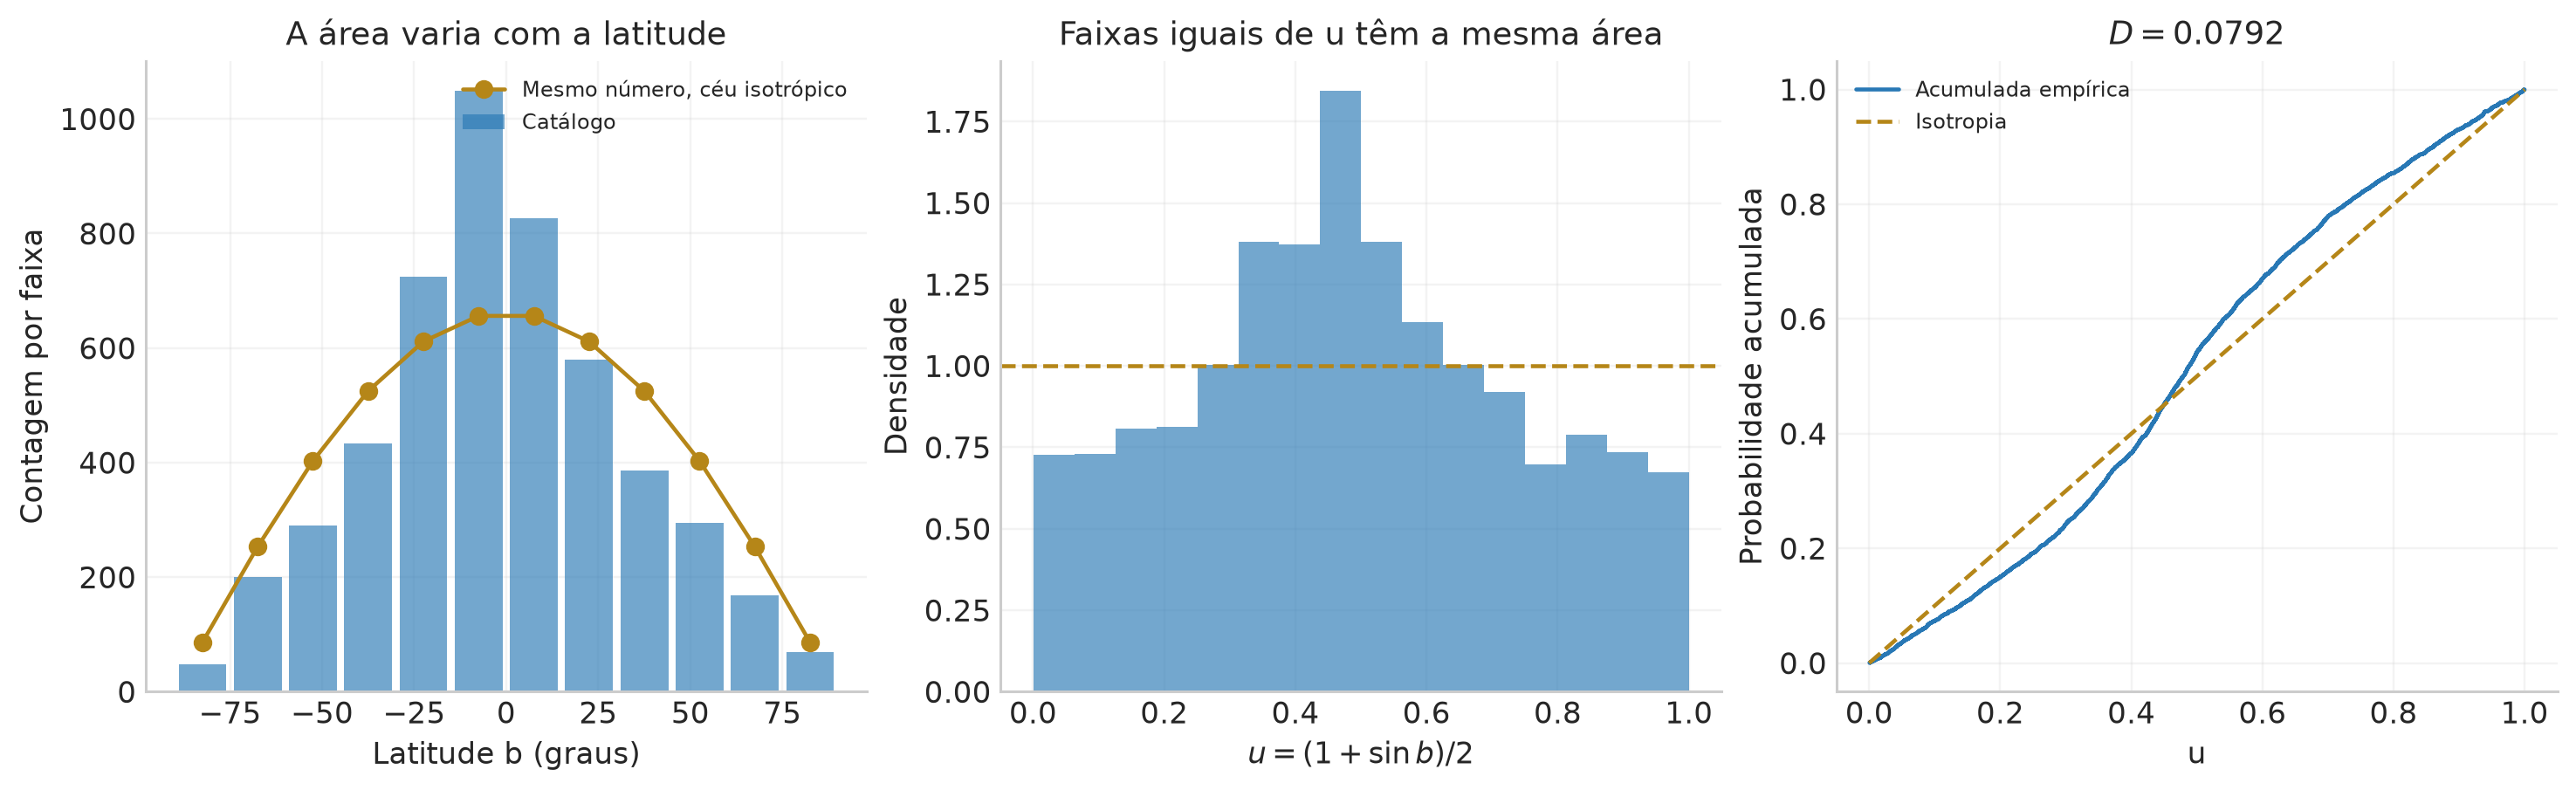

,Quantidade,Valor
0,Norte: sin |b|,2324
1,Sul: sin |b|,2746
2,D entre as duas marginais,0.052071046
3,p formal IID entre hemisférios,0.0020874838


O catálogo revela uma distribuição angular estruturada. O teste avalia a referência isotrópica do recorte observado. A concentração em torno do plano galáctico é uma interpretação física natural, que deve ser estudada junto com seleção, extinção e composição estelar. A comparação norte–sul usa $D_{n,m}=\sup_x|\widehat F_n(x)-\widehat G_m(x)|$; ela verifica a simetria dessa marginal, uma pergunta diferente da isotropia.

,Probabilidade acumulada,Quantil D: simulação uniforme,Quantil D: referência finita do SciPy
0,0.5,0.0572673,0.0577049
1,0.9,0.0854815,0.0856863
2,0.95,0.095367,0.0951579
3,0.99,0.115429,0.114156


In [13]:
fig,axes=plt.subplots(1,3,figsize=(13.3,4),layout='constrained')
bedges=np.linspace(-np.pi/2,np.pi/2,13)
counts,_=np.histogram(star_b,bedges)
expected=star_n*np.diff((1+np.sin(bedges))/2)
centers=np.rad2deg((bedges[:-1]+bedges[1:])/2)
axes[0].bar(centers,counts,width=13,color=BLUE,alpha=.65,label='Catálogo')
axes[0].plot(centers,expected,'o-',color=GOLD,label='Mesmo número, céu isotrópico')
axes[0].set(xlabel='Latitude b (graus)',ylabel='Contagem por faixa',title='A área varia com a latitude');axes[0].legend(fontsize=8)
axes[1].hist(star_u,bins=16,density=True,color=BLUE,alpha=.65)
axes[1].axhline(1,color=GOLD,ls='--');axes[1].set(xlabel=r'$u=(1+\sin b)/2$',ylabel='Densidade',title='Faixas iguais de u têm a mesma área')
su=np.sort(star_u);fn=np.arange(1,star_n+1)/star_n
axes[2].step(su,fn,where='post',color=BLUE,label='Acumulada empírica')
axes[2].plot([0,1],[0,1],color=GOLD,ls='--',label='Isotropia')
axes[2].set(xlabel='u',ylabel='Probabilidade acumulada',title=fr'$D={star_D:.4f}$');axes[2].legend(fontsize=8)
figure_done(fig,'09_estrelas_geometria_ks')
# Um KS de duas amostras compara duas CDFs empíricas.
north=np.sin(star_b[star_b>=0]);south=-np.sin(star_b[star_b<0])
star_two=stats.ks_2samp(north,south,method='asymp')
table([['Norte: sin |b|',len(north)],['Sul: sin |b|',len(south)],
       ['D entre as duas marginais',star_two.statistic],['p formal IID entre hemisférios',star_two.pvalue]],
      ['Quantidade','Valor'],name='estrelas_hemisferios',digits=8)
display(Markdown('O catálogo revela uma distribuição angular estruturada. O teste avalia a referência isotrópica do recorte observado. '
                 'A concentração em torno do plano galáctico é uma interpretação física natural, que deve ser estudada junto com seleção, extinção e composição estelar. '
                 r'A comparação norte–sul usa $D_{n,m}=\sup_x|\widehat F_n(x)-\widehat G_m(x)|$; '
                 'ela verifica a simetria dessa marginal, uma pergunta diferente da isotropia.'))
# Conferência de uma referência de KS por repetições uniformes.
rng=rng_for(8);ks_n=200
ks_uniform=np.sort(rng.uniform(size=(8000,ks_n)),axis=1)
ks_ref=np.maximum(np.max(np.arange(1,ks_n+1)/ks_n-ks_uniform,axis=1),
                  np.max(ks_uniform-np.arange(ks_n)/ks_n,axis=1))
table([[q,np.quantile(ks_ref,q),stats.kstwo.ppf(q,ks_n)] for q in [.5,.9,.95,.99]],
      ['Probabilidade acumulada','Quantil D: simulação uniforme','Quantil D: referência finita do SciPy'],
      name='ks_calibracao');

### 2.4 Escolaridade no Rio e em Salvador: usar os dados e respeitar o desenho da pesquisa

Os valores a seguir foram obtidos diretamente da **Tabela SIDRA 10061, Censo 2022**, variável 2667, nível municipal, sexo e cor/raça totais. O recorte é a população de **18 anos ou mais**, grupo de idade total da tabela, nos municípios do Rio de Janeiro (3304557) e Salvador (2927408). As categorias são níveis amplos de instrução, uma operacionalização disponível do exemplo “última série frequentada” dos slides.

[Tabela oficial](https://sidra.ibge.gov.br/tabela/10061) · [Consulta utilizada](https://api.sidra.ibge.gov.br/values/t/10061/n6/3304557,2927408/v/2667/p/2022/c1568/all) · [Informações sobre o Censo e a amostra](https://www.ibge.gov.br/estatisticas/sociais/populacao/22827-censo-demografico-2022.html). Acesso: 28/10/2026. As estimativas do recorte estão incorporadas sem arredondamento adicional.

Esses números são **estimativas expandidas da amostra do Censo**, expressas em pessoas. Pesos, estratificação e conglomerados influenciam sua variância. Por isso a tabela permite comparar os perfis publicados, enquanto um $p$-valor de pesquisa exige informação sobre o desenho amostral. Tratar milhões de pessoas estimadas como milhões de observações IID atribuiria uma precisão artificial à comparação.

Vamos fazer duas operações transparentes: primeiro comparar as proporções reais; depois simular duas amostras simples independentes, com tamanhos conhecidos, usando esses perfis como populações ilustrativas. **Os perfis são reais; as contagens da segunda etapa são simuladas.** O teste nessa etapa descreve o experimento simulado.

,Nível de instrução,Rio: pessoas estimadas,Salvador: pessoas estimadas,Rio (%),Salvador (%),Diferença Rio - Salvador (p.p.)
0,Sem instrução e fundamental incompleto,9.88e+05,4.18e+05,19.9,21.7,-1.77
1,Fundamental completo e médio incompleto,7.62e+05,3.03e+05,15.4,15.7,-0.368
2,Médio completo e superior incompleto,1.98e+06,8.3e+05,39.9,43.1,-3.18
3,Superior completo,1.23e+06,3.74e+05,24.7,19.4,5.32


Distância de variação total dos perfis: 0.0532
Somas das categorias: [4955146 1925615]
Totais publicados: Rio = 4.955.147; Salvador = 1.925.615.
A diferença de uma pessoa no Rio é de arredondamento da tabela; as proporções usam a soma das categorias.


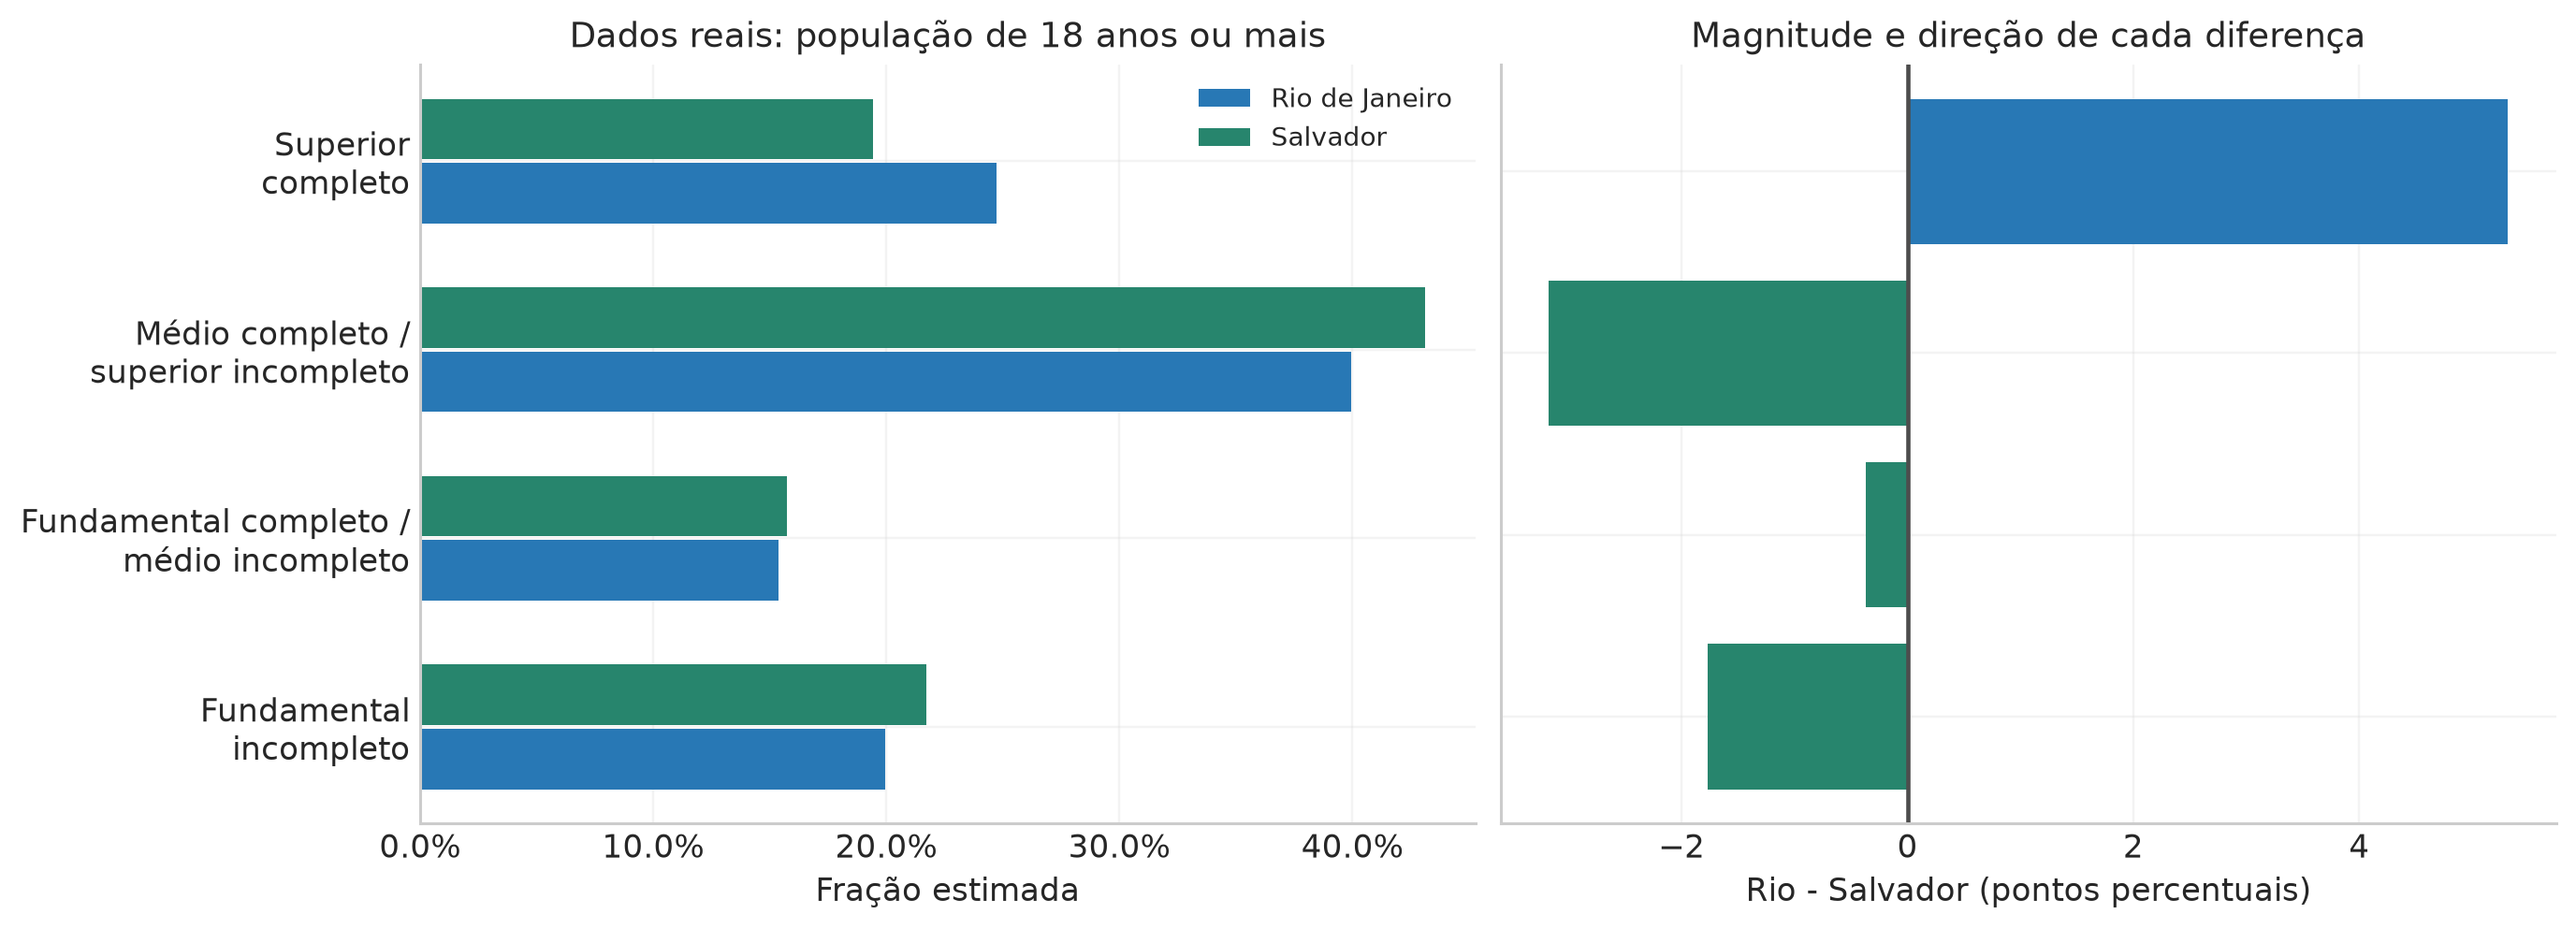

In [14]:
educ_categories = ['Sem instrução e fundamental incompleto', 'Fundamental completo e médio incompleto', 'Médio completo e superior incompleto', 'Superior completo']
educ_counts = np.array([[988278, 761544, 1979292, 1226032], [418197, 303035, 830341, 374042]],dtype=float)
educ_props=educ_counts/educ_counts.sum(axis=1,keepdims=True)
educ_real=pd.DataFrame({'Nível de instrução':educ_categories,
                        'Rio: pessoas estimadas':educ_counts[0],
                        'Salvador: pessoas estimadas':educ_counts[1],
                        'Rio (%)':100*educ_props[0],'Salvador (%)':100*educ_props[1],
                        'Diferença Rio - Salvador (p.p.)':100*(educ_props[0]-educ_props[1])})
table(educ_real,name='escolaridade_real',digits=3)
educ_tv=.5*np.abs(educ_props[0]-educ_props[1]).sum()
print(f'Distância de variação total dos perfis: {educ_tv:.4f}')
print('Somas das categorias:',educ_counts.sum(1).astype(int))
print('Totais publicados: Rio = 4.955.147; Salvador = 1.925.615.')
print('A diferença de uma pessoa no Rio é de arredondamento da tabela; as proporções usam a soma das categorias.')
fig,axes=plt.subplots(1,2,figsize=(12.4,4.4),layout='constrained')
labels=['Fundamental\nincompleto','Fundamental completo /\nmédio incompleto',
        'Médio completo /\nsuperior incompleto','Superior\ncompleto']
idx=np.arange(4)
axes[0].barh(idx-.17,educ_props[0],height=.32,color=BLUE,label='Rio de Janeiro')
axes[0].barh(idx+.17,educ_props[1],height=.32,color=GREEN,label='Salvador')
axes[0].set(yticks=idx,yticklabels=labels,xlabel='Fração estimada',title='Dados reais: população de 18 anos ou mais')
axes[0].xaxis.set_major_formatter(PercentFormatter(1));axes[0].legend()
axes[1].barh(idx,100*(educ_props[0]-educ_props[1]),color=[BLUE if v>0 else GREEN for v in educ_props[0]-educ_props[1]])
axes[1].axvline(0,color='0.3');axes[1].set(yticks=idx,yticklabels=[],xlabel='Rio - Salvador (pontos percentuais)',title='Magnitude e direção de cada diferença')
figure_done(fig,'10_escolaridade_real')

### 2.5 O teste de homogeneidade em amostras independentes

Agora $O_{ji}$ é a contagem da categoria $i$ no grupo $j$, com totais de linha $n_j$ fixados. Sob $H_0$, ambos os grupos têm as mesmas probabilidades $p_i$. Juntando as amostras, estimamos

$$\widehat p_i=\frac{O_{1i}+O_{2i}}{n_1+n_2},\qquad E_{ji}=n_j\widehat p_i.$$

A discrepância de Pearson é

$$X^2=\sum_{j=1}^2\sum_{i=1}^k\frac{(O_{ji}-E_{ji})^2}{E_{ji}}.$$

Cada linha tem $k-1$ contagens livres e estimamos $k-1$ probabilidades comuns. Restam $2(k-1)-(k-1)=k-1$ graus de liberdade; para $r$ grupos, $(r-1)(k-1)$. Com contagens esperadas adequadas, usamos a cauda direita da qui-quadrado. A Parte 3 explicará por que o quadrado dos desvios produz essa referência.

Se os totais dos dois grupos forem iguais a $n$, os valores esperados de uma categoria são $(R_i+S_i)/2$ em cada grupo. Somar as duas contribuições fornece $(R_i-S_i)^2/(R_i+S_i)$, recuperando a expressão do §7.3.2 do Gregory. A tabela de contingência é a generalização para tamanhos diferentes.

Para uma conferência por simulação, condicionamos nos totais de linha e coluna. Sob a hipótese comum, sortear as categorias destinadas ao primeiro grupo equivale a uma **hipergeométrica multivariada**, uma extensão de sortear sem reposição. O restante forma o segundo grupo. Isso mantém os totais e gera a referência condicional.

Se $M_i=O_{1i}+O_{2i}$ é o total combinado da categoria, a probabilidade de destinar $c_i$ desses registros ao primeiro grupo é $\prod_i\binom{M_i}{c_i}/\binom{N}{n_1}$, com $\sum_i c_i=n_1$. O numerador conta escolhas dentro das categorias, e o denominador conta todos os subconjuntos de tamanho $n_1$.
    

In [15]:
rng=rng_for(4)
educ_sim=np.vstack([rng.multinomial(1200,educ_props[0]),rng.multinomial(900,educ_props[1])])
def contingency_stat(observed):
    observed=np.asarray(observed,dtype=float)
    e=observed.sum(1,keepdims=True)*observed.sum(0,keepdims=True)/observed.sum()
    return np.sum((observed-e)**2/e),e
educ_X,educ_E=contingency_stat(educ_sim)
educ_df=3;educ_p=stats.chi2.sf(educ_X,educ_df)
column_totals=educ_sim.sum(0)
draws=rng.multivariate_hypergeometric(column_totals,int(educ_sim[0].sum()),size=20000)
sim2=column_totals-draws
educ_xref=np.sum((draws-educ_E[0])**2/educ_E[0]+(sim2-educ_E[1])**2/educ_E[1],axis=1)
educ_p_mc,educ_mcse=mc_tail(educ_xref,educ_X)
educ_V=np.sqrt(educ_X/educ_sim.sum())
table(pd.DataFrame({'Categoria':educ_categories,'Rio: contagem simulada':educ_sim[0],
                    'Salvador: contagem simulada':educ_sim[1],
                    'Rio: esperado sob H0':educ_E[0],'Salvador: esperado sob H0':educ_E[1]}),name='escolaridade_simulada')
table([['X²',educ_X],['nu',educ_df],['p qui-quadrado',educ_p],
       ['p condicional Monte Carlo',educ_p_mc],['Erro Monte Carlo aproximado',educ_mcse],
       ['V de Cramér',educ_V],['Menor contagem esperada',educ_E.min()]],
      ['Quantidade: experimento SIMULADO','Valor'],name='escolaridade_teste')
check('Homogeneidade confere com SciPy',np.isclose(educ_X,stats.chi2_contingency(educ_sim,correction=False).statistic))
display(Markdown(f'No experimento simulado, a decisão a 5% é **{verdict(educ_p)}**. '
                 'O teste e sua calibração são válidos para essa amostragem independente. '
                 'A comparação real do IBGE permanece nas proporções e diferenças acima. '
                 'A distância de variação total é metade da soma das diferenças absolutas entre proporções; '
                 r'o V de Cramér é uma medida padronizada de discrepância, aqui igual a $\sqrt{X^2/N}$ para duas linhas.'))

,Categoria,Rio: contagem simulada,Salvador: contagem simulada,Rio: esperado sob H0,Salvador: esperado sob H0
0,Sem instrução e fundamental incompleto,262,169,246.286,184.714
1,Fundamental completo e médio incompleto,188,155,196,147
2,Médio completo e superior incompleto,470,396,494.857,371.143
3,Superior completo,280,180,262.857,197.143


,Quantidade: experimento SIMULADO,Valor
0,X²,8.62352
1,nu,3
2,p qui-quadrado,0.0347388
3,p condicional Monte Carlo,0.0343483
4,Erro Monte Carlo aproximado,0.00128777
5,V de Cramér,0.0640815
6,Menor contagem esperada,147


No experimento simulado, a decisão a 5% é **rejeitar H0 neste nível**. O teste e sua calibração são válidos para essa amostragem independente. A comparação real do IBGE permanece nas proporções e diferenças acima. A distância de variação total é metade da soma das diferenças absolutas entre proporções; o V de Cramér é uma medida padronizada de discrepância, aqui igual a $\sqrt{X^2/N}$ para duas linhas.

### 2.6 Notas reais da P1 de Física 1 — 2026.2

O PDF **“Notas_P1F1_ 02_10_2026.pdf”** contém 1.352 registros: **1.041 provas realizadas** e **311 faltas**, indicadas por `F`. Entre as provas realizadas, **186 têm nota total zero**. Trabalhamos com a nota total, soma das partes objetiva e discursiva, em uma escala de 0 a 10. A soma das duas partes foi conferida em todos os 1.041 registros válidos. Todas as notas têm resolução de 0,1 ponto.

As frequências anônimas incorporadas abaixo preservam exatamente a distribuição das notas. Identificadores pessoais foram retirados. A população descrita é **quem realizou esta P1 e aparece no arquivo**. Esse PDF fornece o conjunto agregado; a análise de diferenças entre turmas dependeria dos rótulos das turmas. As faltas são um resultado de participação, separado da distribuição condicional das notas entre presentes.

O histograma permite formular uma pergunta precisa: **uma forma normal, após o registro das notas na escala utilizada, descreve adequadamente a distribuição observada?** A escala tem limites e arredondamento, então vamos explicitar o processo de observação em vez de aplicar automaticamente uma referência contínua a valores repetidos.

,Quantidade,Valor
0,Registros no PDF,1352
1,Provas realizadas,1041
2,Faltas,311
3,Notas zero entre presentes,186
4,Média entre presentes,2.31143
5,Desvio padrão entre presentes,2.31778
6,Mediana entre presentes,1.5
7,Fração com nota >= 5,0.142171


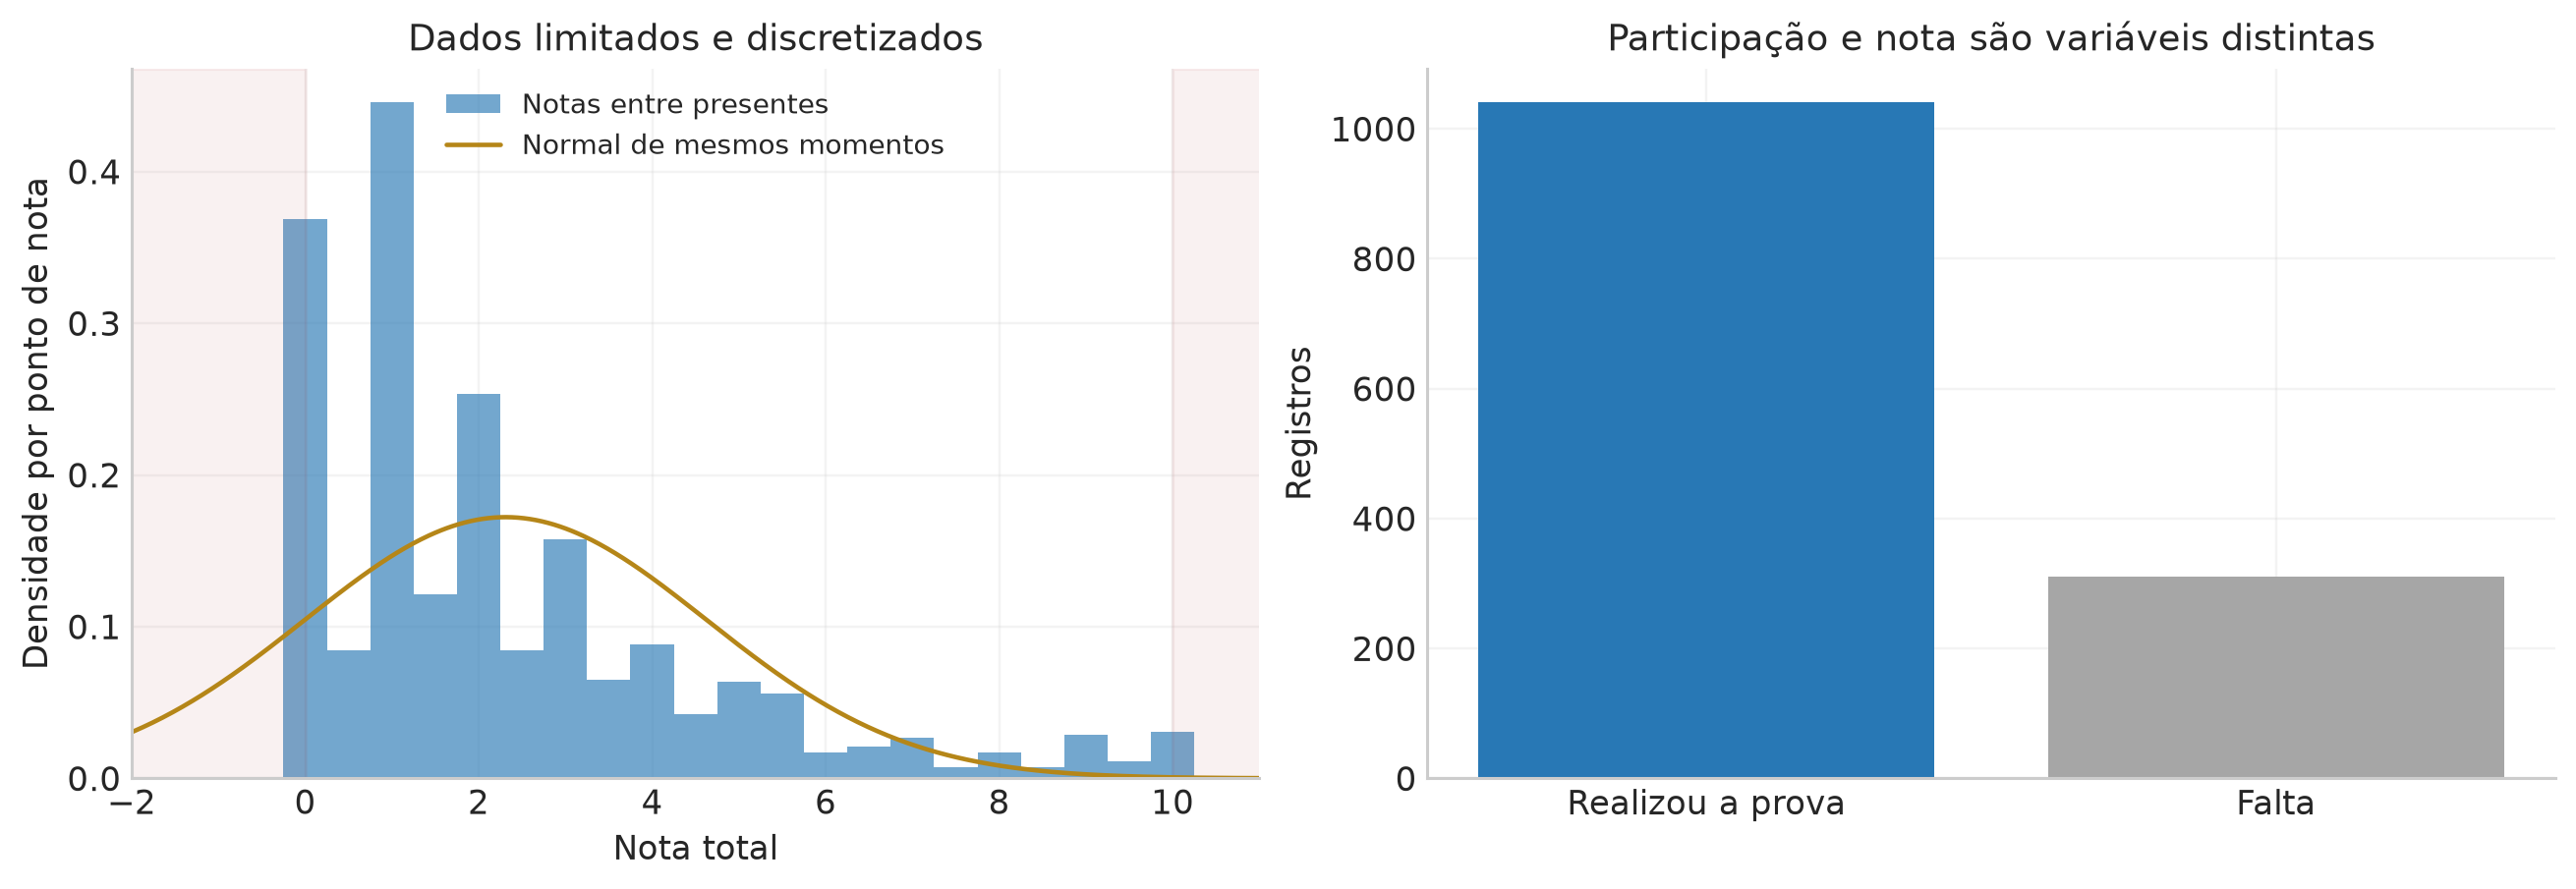

In [16]:
grade_frequency = [[0.0, 186], [0.1, 4], [0.2, 2], [0.3, 7], [0.4, 4], [0.5, 28], [0.6, 1], [0.7, 4], [0.8, 3], [1.0, 217], [1.1, 2], [1.2, 10], [1.3, 8], [1.4, 1], [1.5, 54], [1.8, 2], [1.9, 1], [2.0, 116], [2.1, 5], [2.2, 8], [2.3, 8], [2.4, 3], [2.5, 29], [2.6, 2], [2.7, 2], [2.8, 6], [3.0, 70], [3.1, 1], [3.2, 5], [3.3, 3], [3.4, 2], [3.5, 25], [3.6, 2], [3.7, 2], [3.8, 4], [3.9, 1], [4.0, 36], [4.1, 1], [4.2, 4], [4.3, 1], [4.4, 4], [4.5, 15], [4.7, 2], [4.8, 1], [4.9, 1], [5.0, 28], [5.2, 3], [5.3, 7], [5.4, 1], [5.5, 16], [5.7, 5], [6.0, 8], [6.2, 1], [6.3, 3], [6.5, 4], [6.6, 2], [6.7, 2], [6.8, 3], [6.9, 1], [7.0, 8], [7.2, 2], [7.5, 2], [7.6, 2], [7.8, 2], [8.0, 6], [8.2, 1], [8.3, 1], [8.5, 1], [8.6, 1], [8.7, 1], [8.8, 1], [9.0, 14], [9.4, 1], [9.5, 2], [9.7, 3], [10.0, 16]]
grade_values=np.array([r[0] for r in grade_frequency])
grade_counts=np.array([r[1] for r in grade_frequency],dtype=int)
grades=np.repeat(grade_values,grade_counts)
grade_n=len(grades); grade_absent=311
grade_mean=grades.mean();grade_s=grades.std(ddof=1)
table([['Registros no PDF',grade_n+grade_absent],['Provas realizadas',grade_n],
       ['Faltas',grade_absent],['Notas zero entre presentes',np.count_nonzero(grades==0)],
       ['Média entre presentes',grade_mean],['Desvio padrão entre presentes',grade_s],
       ['Mediana entre presentes',np.median(grades)],['Fração com nota >= 5',np.mean(grades>=5)]],
      ['Quantidade','Valor'],name='notas_resumo')
check('Contagem das notas',grade_n==1041 and grade_n+grade_absent==1352)
check('Escala de notas',grades.min()==0 and grades.max()==10 and np.allclose(10*grades,np.round(10*grades)))
fig,axes=plt.subplots(1,2,figsize=(11.8,4),layout='constrained')
edges=np.arange(-.25,10.76,.5)
axes[0].hist(grades,bins=edges,density=True,color=BLUE,alpha=.65,label='Notas entre presentes')
g=np.linspace(-4,12,700)
axes[0].plot(g,stats.norm.pdf(g,grade_mean,grades.std(ddof=0)),color=GOLD,label='Normal de mesmos momentos')
axes[0].axvspan(-4,0,color=RED,alpha=.08);axes[0].axvspan(10,12,color=RED,alpha=.08)
axes[0].set(xlabel='Nota total',ylabel='Densidade por ponto de nota',title='Dados limitados e discretizados',xlim=(-2,11));axes[0].legend()
axes[1].bar(['Realizou a prova','Falta'],[grade_n,grade_absent],color=[BLUE,'0.65'])
axes[1].set(ylabel='Registros',title='Participação e nota são variáveis distintas')
figure_done(fig,'11_notas_histograma')

### 2.7 Da normal contínua à nota registrada

Considere uma variável latente $X\sim\mathcal N(\mu,\sigma^2)$ e uma regra de registro $Y=\operatorname{clip}(\operatorname{round}(X,1),0,10)$. Essa é uma **hipótese de trabalho para a forma observada**, não uma descrição causal da aprendizagem. Ela atribui às notas centrais probabilidades dadas por integrais em intervalos de largura 0,1:

$$P(Y=y)=\Phi\!\left(\frac{y+0{,}05-\mu}{\sigma}\right)
-\Phi\!\left(\frac{y-0{,}05-\mu}{\sigma}\right),\quad y=0{,}1,\ldots,9{,}9.$$

Nos limites, $P(Y=0)=\Phi((0{,}05-\mu)/\sigma)$ e $P(Y=10)=1-\Phi((9{,}95-\mu)/\sigma)$. A regra inclui arredondamento e acumulação nas extremidades. Uma normal truncada, condicionada em $0\le X\le10$, seria outro modelo, com outra normalização.

Para o teste principal, fixamos grupos amplos: nota zero; $(0,1]$; $(1,2]$; $(2,3]$; $(3,4]$; $(4,5]$; $(5,7]$; $(7,10]$. Sob a regra de registro, seus limites na variável latente são $-\infty,0{,}05,1{,}05,\ldots,5{,}05,7{,}05,+\infty$. As probabilidades são diferenças da CDF normal nesses limites.

Com $O_i$ notas em cada grupo, a verossimilhança é multinomial. Os fatores que dependem apenas das contagens são constantes em $(\mu,\sigma)$; maximizar a verossimilhança equivale a maximizar

$$\ell(\mu,\sigma)=\sum_i O_i\log p_i(\mu,\sigma).$$

O código faz essa maximização com $\eta=\log\sigma$, garantindo $\sigma>0$. **O ajuste usa as mesmas contagens que serão testadas.** Para $k=8$ categorias e dois parâmetros estimados, a referência assintótica é $\chi^2_{k-1-2}=\chi^2_5$, desde que o ajuste seja regular e as contagens esperadas sejam adequadas.

Também construiremos a referência por simulação: sorteamos novas contagens com o modelo ajustado, reajustamos $\mu,\sigma$ em cada repetição e recalculamos a discrepância. Esse procedimento reproduz a estimação dos parâmetros e o registro das notas; é uma calibração numérica da pergunta sob o modelo proposto.

In [17]:
grade_edges=np.array([-np.inf,.05,1.05,2.05,3.05,4.05,5.05,7.05,np.inf])
grade_obs=np.histogram(grades,grade_edges)[0]
grade_labels=['0','0,1–1,0','1,1–2,0','2,1–3,0','3,1–4,0','4,1–5,0','5,1–7,0','7,1–10,0']
def grade_prob(theta):
    mu,log_sigma=theta
    return np.diff(stats.norm.cdf(grade_edges,loc=mu,scale=np.exp(log_sigma)))
def fit_grade_counts(counts,start=None):
    if start is None:start=np.array([grade_mean,np.log(grade_s)])
    def objective(theta):
        p=grade_prob(theta)
        return -np.sum(special.xlogy(counts,np.maximum(p,1e-300)))
    fit=optimize.minimize(objective,start,method='L-BFGS-B',bounds=[(-10,20),(-3,4)])
    if not fit.success:raise RuntimeError(fit.message)
    expected=np.sum(counts)*grade_prob(fit.x)
    return fit.x,np.sum((counts-expected)**2/expected),expected
grade_theta,grade_X,grade_expected=fit_grade_counts(grade_obs)
grade_df=len(grade_obs)-3;grade_p_asym=stats.chi2.sf(grade_X,grade_df)
table(pd.DataFrame({'Grupo de notas':grade_labels,'Observado':grade_obs,
                    'Esperado: normal registrada':grade_expected,
                    'Contribuição para X²':(grade_obs-grade_expected)**2/grade_expected}),
      name='notas_aderencia')
table([['mu latente ajustado',grade_theta[0]],['sigma latente ajustado',np.exp(grade_theta[1])],
       ['X² de Pearson',grade_X],['nu',grade_df],['Menor esperado',grade_expected.min()],
       ['p assintótico',grade_p_asym]],['Quantidade','Valor'],name='notas_teste',digits=8)
check('Probabilidades de registro somam 1',np.isclose(grade_prob(grade_theta).sum(),1))
check('Contagens esperadas positivas',np.all(grade_expected>5))

,Grupo de notas,Observado,Esperado: normal registrada,Contribuição para X²
0,0,186,254.077,18.2404
1,"0,1–1,0",270,143.822,110.699
2,"1,1–2,0",194,161.581,6.50436
3,"2,1–3,0",133,155.786,3.33273
4,"3,1–4,0",81,128.895,17.7968
5,"4,1–5,0",57,91.5191,13.0199
6,"5,1–7,0",64,84.9211,5.15411
7,"7,1–10,0",56,20.3993,62.1301


,Quantidade,Valor
0,mu latente ajustado,1.8112052
1,sigma latente ajustado,2.5404306
2,X² de Pearson,236.87745
3,nu,5
4,Menor esperado,20.3993
5,p assintótico,3.5876357e-49


,Quantidade,Valor
0,p por simulação com reajuste,0.0005
1,Erro Monte Carlo aproximado,0.00049987498
2,Resolução mínima 1/(B+1),0.0005
3,Repetições tão discrepantes quanto os dados,0
4,Limite binomial unilateral de 95% para a cauda simulada,0.0014974931


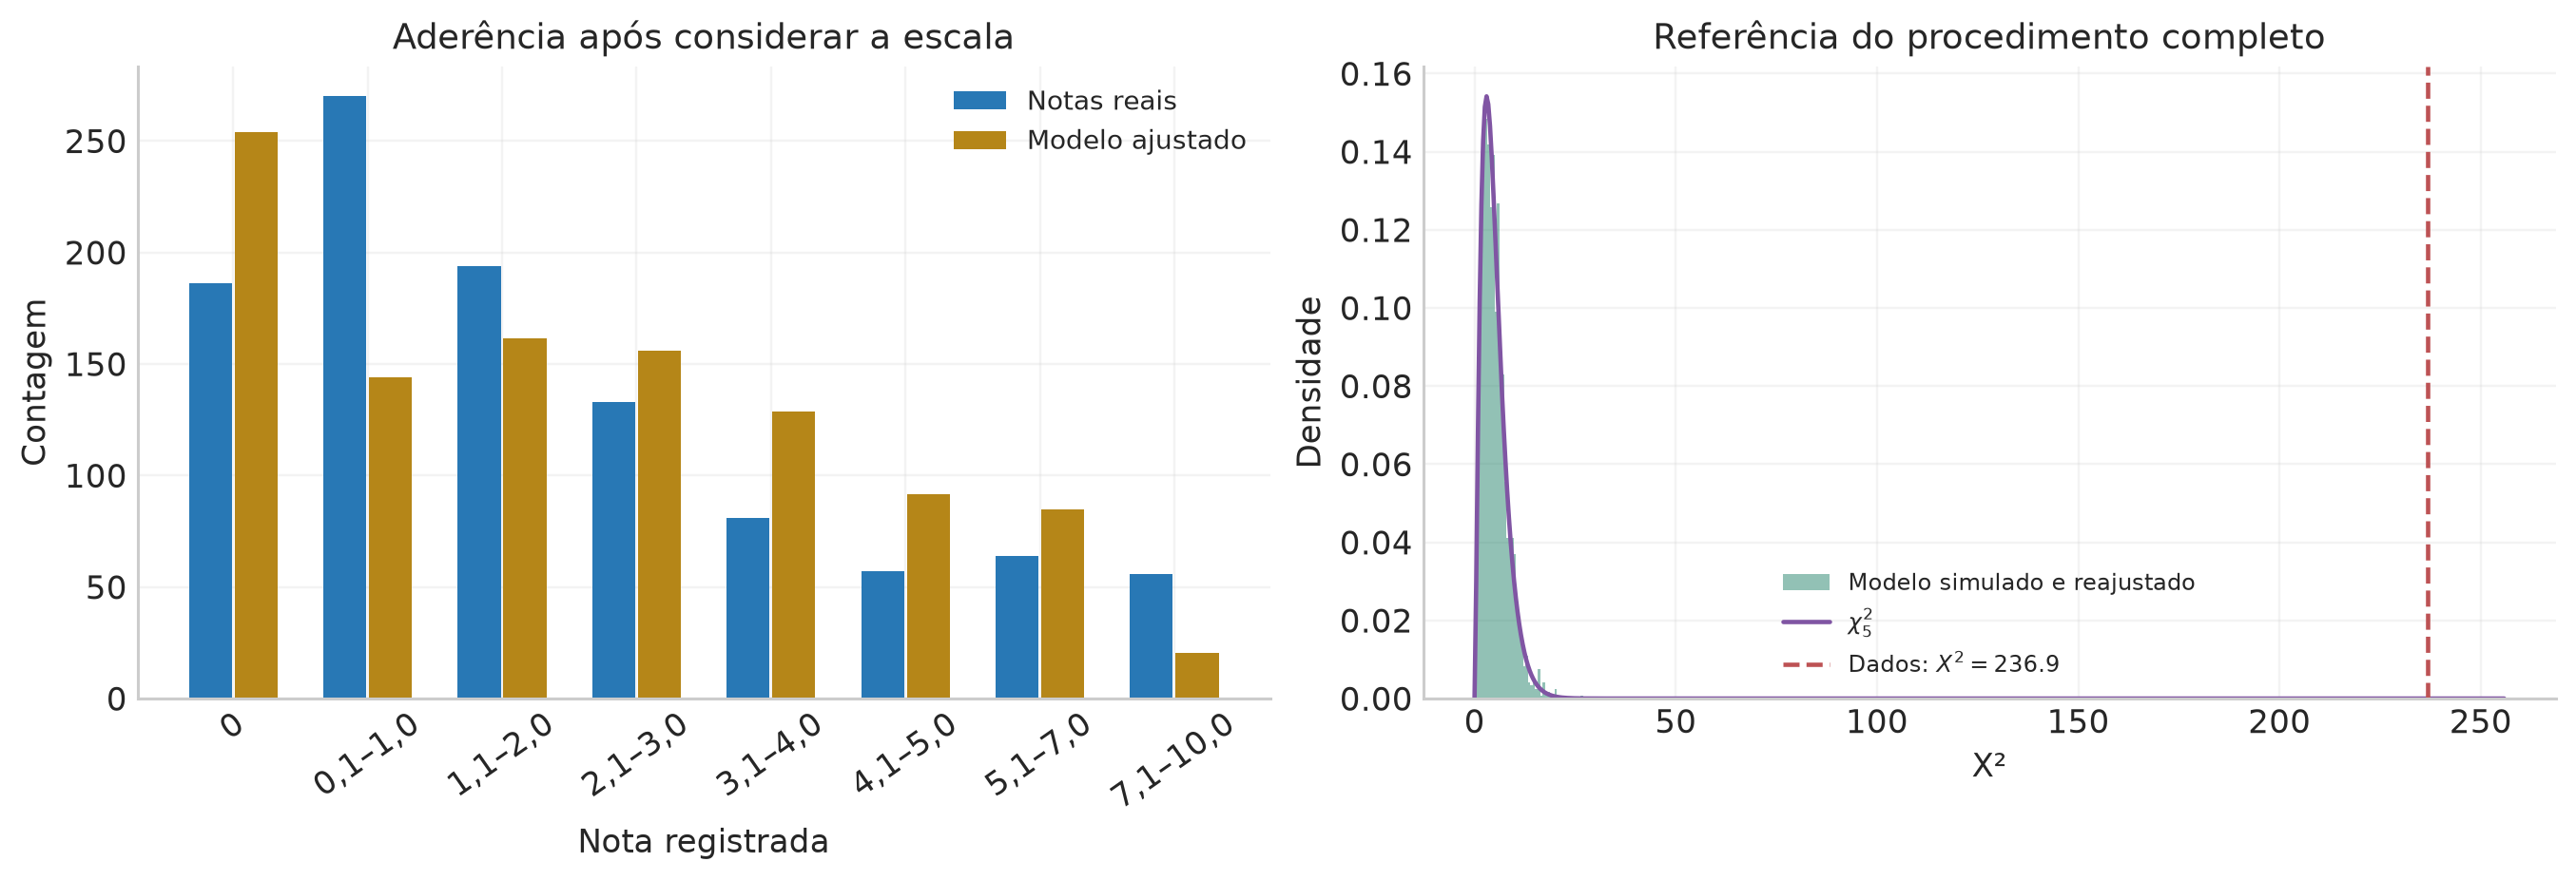

No nível de 5%, a decisão para esse modelo de forma é **rejeitar H0 neste nível**. A análise inclui todas as provas realizadas, inclusive os zeros. A comparação avalia a forma agregada sob um modelo de repetições hipotéticas; ela permite localizar discrepâncias, enquanto explicações sobre turmas, preparação ou instrumentos de avaliação exigem outras variáveis. Com zero ultrapassagens, a estimativa corrigida atinge a resolução mínima $1/(B+1)$; o quadro também mostra um limite binomial unilateral de 95% para a chance de ultrapassagem nessa referência. Se a chance de ultrapassagem é $p$, observar zero eventos em $B$ repetições tem probabilidade $(1-p)^B$. Resolver $(1-p)^B=0,05$ dá o limite $p=1-0,05^{1/B}$.

In [18]:
rng=rng_for(5);grade_B=1999
grade_boot_counts=rng.multinomial(grade_n,grade_prob(grade_theta),size=grade_B)
grade_Xref=np.array([fit_grade_counts(row,start=grade_theta)[1] for row in grade_boot_counts])
grade_p_mc,grade_mcse=mc_tail(grade_Xref,grade_X)
grade_hits=np.count_nonzero(grade_Xref>=grade_X)
grade_tail_upper=(1-.05**(1/grade_B) if grade_hits==0 else stats.beta.ppf(.95,grade_hits+1,grade_B-grade_hits))
table([['p por simulação com reajuste',grade_p_mc],['Erro Monte Carlo aproximado',grade_mcse],
       ['Resolução mínima 1/(B+1)',1/(grade_B+1)],
       ['Repetições tão discrepantes quanto os dados',grade_hits],
       ['Limite binomial unilateral de 95% para a cauda simulada',grade_tail_upper]],
      ['Quantidade','Valor'],name='notas_simulacao',digits=8)
fig,axes=plt.subplots(1,2,figsize=(12.2,4.1),layout='constrained')
idx=np.arange(len(grade_obs))
axes[0].bar(idx-.17,grade_obs,width=.32,color=BLUE,label='Notas reais')
axes[0].bar(idx+.17,grade_expected,width=.32,color=GOLD,label='Modelo ajustado')
axes[0].set(xticks=idx,xticklabels=grade_labels,xlabel='Nota registrada',ylabel='Contagem',title='Aderência após considerar a escala')
axes[0].tick_params(axis='x',rotation=35);axes[0].legend()
axes[1].hist(grade_Xref,bins=45,density=True,color=GREEN,alpha=.5,label='Modelo simulado e reajustado')
xx=np.linspace(0,max(25,grade_X*1.08),600)
axes[1].plot(xx,stats.chi2.pdf(xx,grade_df),color=PURPLE,label=fr'$\chi^2_{{{grade_df}}}$')
axes[1].axvline(grade_X,color=RED,ls='--',label=fr'Dados: $X^2={grade_X:.1f}$')
axes[1].set(xlabel='X²',ylabel='Densidade',title='Referência do procedimento completo');axes[1].legend(fontsize=8)
figure_done(fig,'12_notas_aderencia')
display(Markdown(f'No nível de 5%, a decisão para esse modelo de forma é **{verdict(grade_p_asym)}**. '
                 'A análise inclui todas as provas realizadas, inclusive os zeros. '
                 'A comparação avalia a forma agregada sob um modelo de repetições hipotéticas; '
                 'ela permite localizar discrepâncias, enquanto explicações sobre turmas, preparação ou instrumentos de avaliação exigem outras variáveis. '
                 'Com zero ultrapassagens, a estimativa corrigida atinge a resolução mínima $1/(B+1)$; '
                 'o quadro também mostra um limite binomial unilateral de 95% para a chance de ultrapassagem nessa referência. '
                 'Se a chance de ultrapassagem é $p$, observar zero eventos em $B$ repetições tem probabilidade $(1-p)^B$. '
                 'Resolver $(1-p)^B=0,05$ dá o limite $p=1-0,05^{1/B}$.'))

## Parte 3 — Histogramas, multinomial e aderência
### 3.1 O dado individual e o vetor das contagens — slides 100–103

Seja $X$ uma observação com distribuição $F_\theta$. Escolhemos $k$ classes disjuntas $B_1,\ldots,B_k$ que cobrem todas as possibilidades. As probabilidades são

$$p_i(\theta)=P_\theta(X\in B_i),\qquad \sum_i p_i=1.$$

Para $X$ contínuo, $p_i=\int_{B_i}f_\theta(x)dx$; em um intervalo $[a_i,b_i)$, $p_i=F_\theta(b_i)-F_\theta(a_i)$. Para $X$ discreto, somamos as massas de probabilidade pertencentes à classe. O modelo individual pode ser normal, exponencial, Poisson, binomial ou outro.

Agora tomamos **$n$ observações IID**, mantemos $n$ fixo e contamos $N_i=\sum_{j=1}^n\mathbf1(X_j\in B_i)$. Uma sequência específica de categorias com essas contagens tem probabilidade $\prod_i p_i^{N_i}$. Há $n!/\prod_iN_i!$ maneiras de ordenar a sequência. Somando essas possibilidades,

$$\boxed{P(N_1=n_1,\ldots,N_k=n_k\mid n,\mathbf p)
=\frac{n!}{\prod_i n_i!}\prod_i p_i^{n_i}},\qquad \sum_i n_i=n.$$

Essa é a **multinomial**. É a distribuição do vetor do histograma sob amostragem IID com tamanho fixo, e não uma exigência de que o dado original seja uma “variável multinomial”. Em particular, um histograma de dados gaussianos tem contagens multinomiais. Se $n$ também for aleatório, outro modelo de contagem poderá ser apropriado; processos Poisson independentes por classe são uma possibilidade.

Em um histograma, devemos ainda distinguir **contagem** $N_i$, **fração** $N_i/n$ e **densidade estimada** $N_i/(n\Delta_i)$. A altura de uma PDF é densidade por unidade de $x$; sua integral no intervalo, multiplicada por $n$, é a contagem esperada. Essa integração também funciona com classes de larguras diferentes e com caudas abertas.

### 3.2 Por que $E[N_i]=np_i$ e por que os bins são correlacionados?

Para uma observação, o indicador $I_{ji}=\mathbf1(X_j\in B_i)$ é Bernoulli com esperança $p_i$ e variância $p_i(1-p_i)$. Somando $n$ indicadores independentes entre observações,

$$E[N_i]=np_i,\qquad \operatorname{Var}(N_i)=np_i(1-p_i).$$

Dentro da mesma observação, $I_{ji}I_{jh}=0$ para $i\ne h$, pois uma medida ocupa uma classe. Portanto $\operatorname{Cov}(I_{ji},I_{jh})=-p_ip_h$ e

$$\operatorname{Cov}(N_i,N_h)=-np_ip_h.$$

Assim, os resíduos de bins diferentes são correlacionados: fixar o total acopla as contagens. Isso explica por que aparecem $k-1$ graus de liberdade, em vez de somar ingenuamente $k$ variáveis normais independentes.

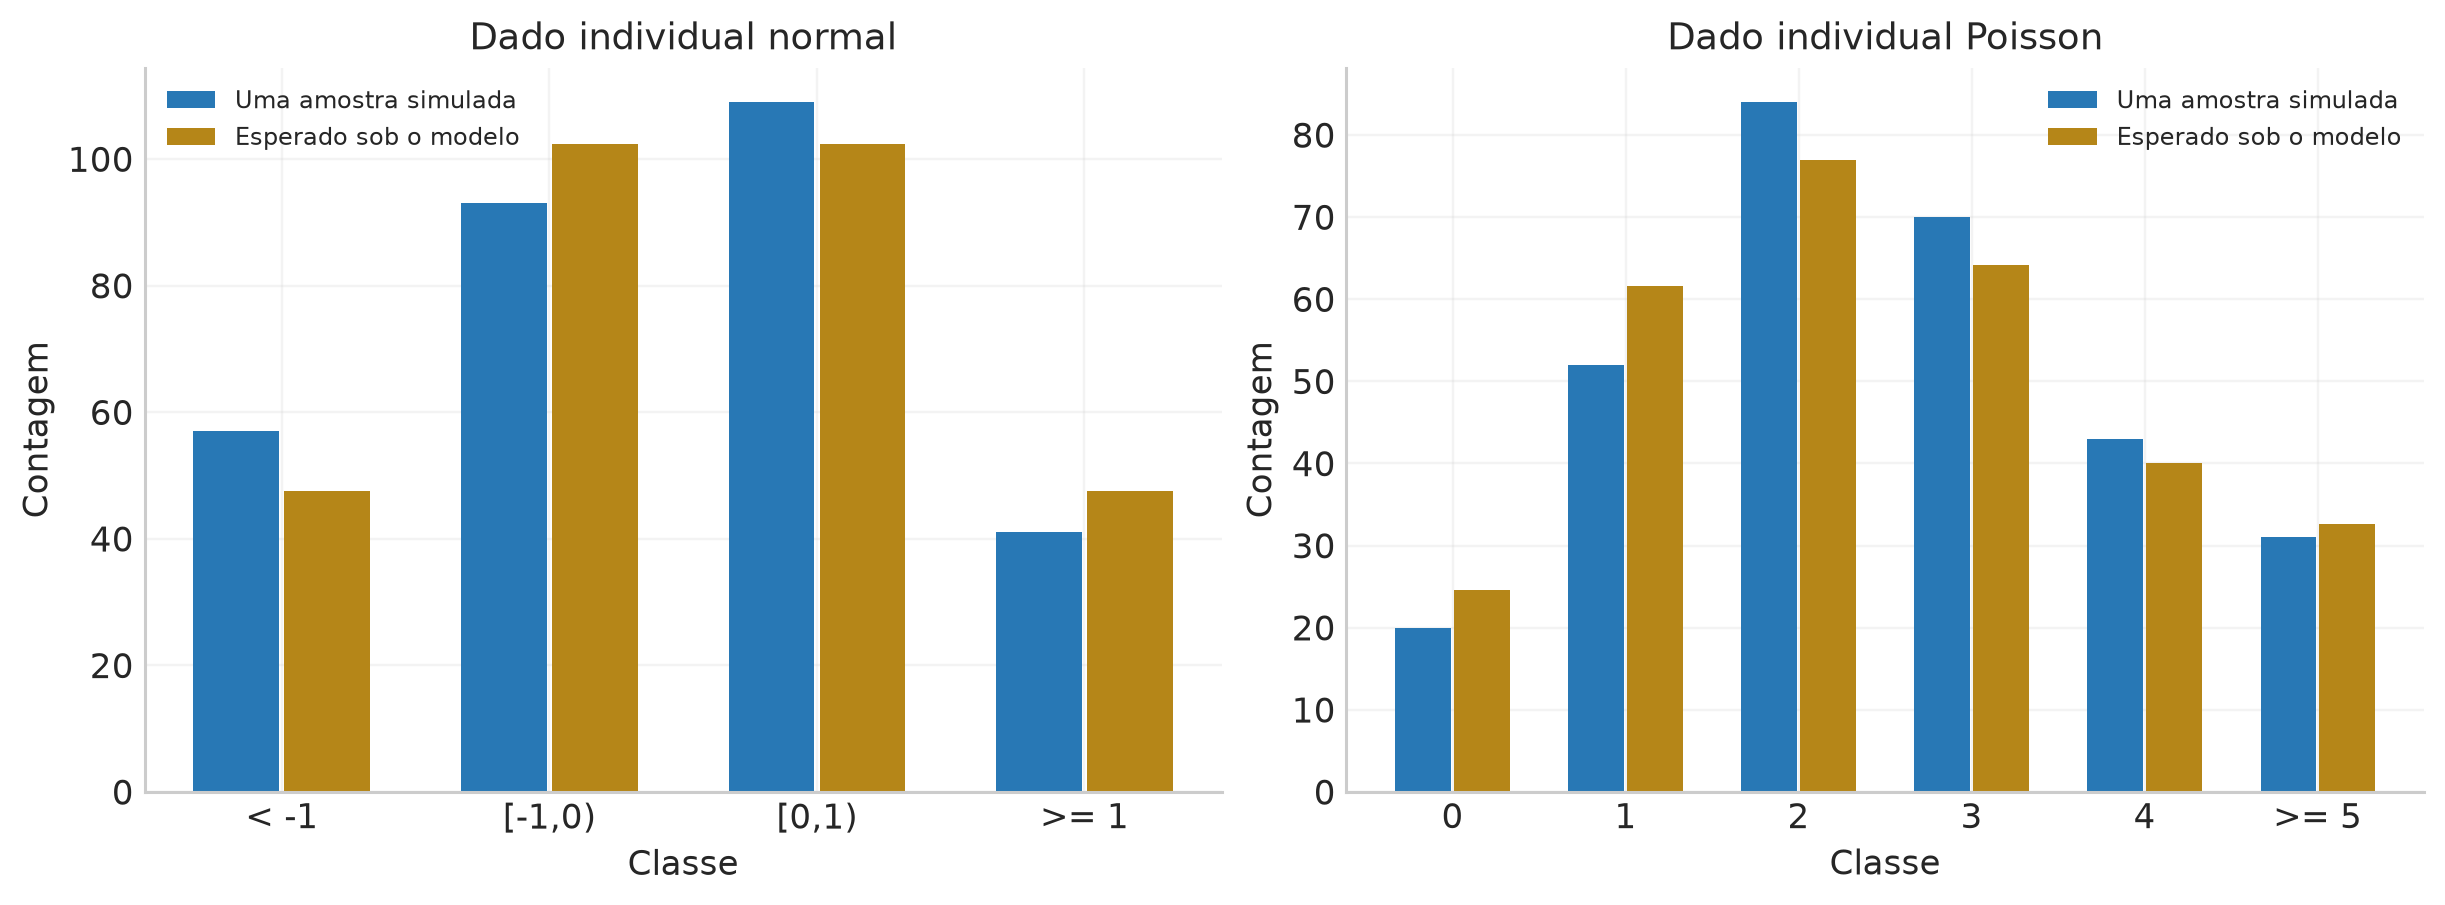

In [19]:
# A mesma construção para uma distribuição individual contínua e outra discreta.
rng=rng_for(6);hist_n=300
normal_edges=np.array([-np.inf,-1,0,1,np.inf])
normal_probs=np.diff(stats.norm.cdf(normal_edges))
normal_data=rng.normal(size=hist_n)
normal_counts=np.histogram(normal_data,normal_edges)[0]
pois_data=rng.poisson(2.5,size=hist_n)
pois_counts=np.array([np.sum(pois_data==i) for i in range(5)]+[np.sum(pois_data>=5)])
pois_probs=np.r_[stats.poisson.pmf(np.arange(5),2.5),stats.poisson.sf(4,2.5)]
fig,axes=plt.subplots(1,2,figsize=(11,4),layout='constrained')
for ax,obs,probs,labels,title in [
    (axes[0],normal_counts,normal_probs,['< -1','[-1,0)','[0,1)','>= 1'],'Dado individual normal'),
    (axes[1],pois_counts,pois_probs,['0','1','2','3','4','>= 5'],'Dado individual Poisson')]:
    idx=np.arange(len(obs))
    ax.bar(idx-.17,obs,width=.32,color=BLUE,label='Uma amostra simulada')
    ax.bar(idx+.17,hist_n*probs,width=.32,color=GOLD,label='Esperado sob o modelo')
    ax.set(xticks=idx,xticklabels=labels,xlabel='Classe',ylabel='Contagem',title=title);ax.legend(fontsize=8)
figure_done(fig,'13_multinomial_origem')
check('Classes normal exaustivas',np.isclose(normal_probs.sum(),1))
check('Classes Poisson exaustivas',np.isclose(pois_probs.sum(),1))

### 3.3 Deduzir a estatística de Pearson

Comecemos com $k=2$. Se $N_1\sim\operatorname{Binomial}(n,p)$, a aproximação normal dá

$$Y=\frac{N_1-np}{\sqrt{np(1-p)}}\approx\mathcal N(0,1).$$

Logo $Y^2\approx\chi^2_1$. Como $N_2=n-N_1$ e $p_2=1-p$,

$$Y^2=\frac{(N_1-np)^2}{np}+\frac{(N_2-n(1-p))^2}{n(1-p)}.$$

Os dois desvios têm sinais opostos; a soma dos dois termos representa **um** grau de liberdade. Para $k$ classes, definimos

$$R_i=\frac{N_i-np_i}{\sqrt{np_i}},\qquad
X^2=\sum_{i=1}^kR_i^2.$$

Pelo TCL multivariado, o vetor $\mathbf R$ é aproximadamente normal, com covariância

$$\operatorname{Cov}(\mathbf R)=I-\mathbf v\mathbf v^T,
\qquad \mathbf v=(\sqrt{p_1},\ldots,\sqrt{p_k}),\quad \mathbf v^T\mathbf v=1.$$

A restrição $\sum_iN_i=n$ equivale a $\mathbf v^T\mathbf R=0$. A matriz projeta em um espaço de dimensão $k-1$: tem $k-1$ autovalores iguais a 1 e um igual a zero. Nas direções independentes desse espaço, $X^2$ é aproximadamente uma soma de $k-1$ quadrados de normais padrão:

$$\boxed{X^2=\sum_i\frac{(N_i-E_i)^2}{E_i}\ \approx\ \chi^2_{k-1}},\qquad E_i=np_i.$$

O modelo completamente especificado fixa os $p_i$. Ao estimar $r$ parâmetros regulares pela verossimilhança das **contagens agrupadas**, ajustamos mais $r$ direções; a referência usual passa a $\chi^2_{k-1-r}$. Esse é o caso do ajuste das notas. Outros métodos de estimação, classes escolhidas pelos dados, parâmetros em fronteiras ou bins muito esparsos pedem uma calibração que reproduza o procedimento.

O teste é uma aproximação assintótica. Verificar os esperados, agrupar classes vizinhas quando necessário e conferir por simulação são boas práticas. Uma regra conservadora comum é buscar esperados de pelo menos 5; essa verificação é um diagnóstico prático, e não uma prova universal de validade. Aumentar o número de classes com o mesmo $n$ pode torná-las mais esparsas. Veja também o [NIST: teste de Pearson](https://www.itl.nist.gov/div898/handbook/eda/section3/eda35f.htm).

,R1,R2,R3
R1,0.851121,-0.211107,-0.28857
R2,-0.211107,0.697569,-0.404942
R3,-0.28857,-0.404942,0.44977


,R1,R2,R3
R1,0.85,-0.212132,-0.287228
R2,-0.212132,0.7,-0.406202
R3,-0.287228,-0.406202,0.45


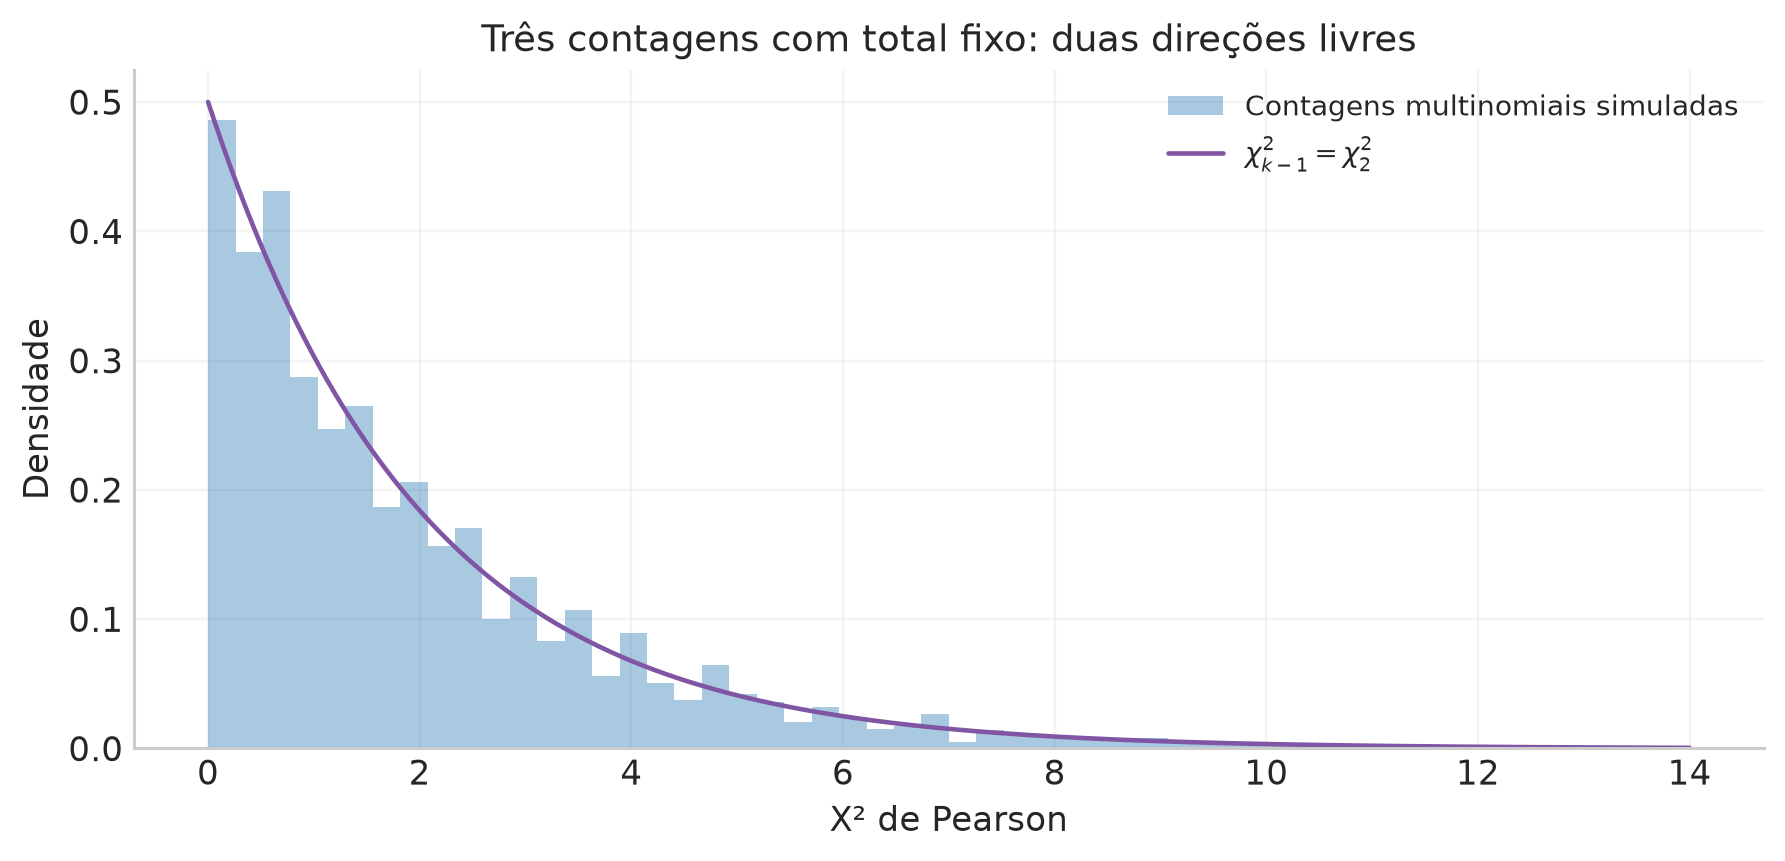

In [20]:
def pearson_counts(observed, probabilities):
    observed=np.asarray(observed,dtype=float);p=np.asarray(probabilities,dtype=float)
    if observed.shape!=p.shape or np.any(observed<0) or np.any(p<0):
        raise ValueError('Contagens e probabilidades devem ter a mesma forma e ser não negativas.')
    if not np.isclose(p.sum(),1,atol=1e-10):raise ValueError('As classes devem cobrir probabilidade total 1.')
    if np.any((p==0)&(observed>0)):return np.inf
    e=observed.sum()*p;mask=e>0
    return np.sum((observed[mask]-e[mask])**2/e[mask])

rng=rng_for(7);n=200;p=np.array([.15,.30,.55])
multinom=rng.multinomial(n,p,size=35000)
res=(multinom-n*p)/np.sqrt(n*p)
cov_theory=np.eye(3)-np.sqrt(p[:,None]*p[None,:])
Xsim=np.sum(res**2,axis=1)
table(pd.DataFrame(np.cov(res,rowvar=False),index=['R1','R2','R3'],columns=['R1','R2','R3']),name='multinomial_covariancia')
table(pd.DataFrame(cov_theory,index=['R1','R2','R3'],columns=['R1','R2','R3']),name='multinomial_covariancia_teorica')
fig,ax=plt.subplots(figsize=(8,3.8),layout='constrained')
ax.hist(Xsim,bins=np.linspace(0,14,55),density=True,color=BLUE,alpha=.4,label='Contagens multinomiais simuladas')
xx=np.linspace(0,14,400);ax.plot(xx,stats.chi2.pdf(xx,2),color=PURPLE,label=r'$\chi^2_{k-1}=\chi^2_2$')
ax.set(xlabel='X² de Pearson',ylabel='Densidade',title='Três contagens com total fixo: duas direções livres');ax.legend()
figure_done(fig,'14_pearson_referencia')
check('Covariância projetada',np.allclose(cov_theory@cov_theory,cov_theory))
check('Restrição multinomial',np.allclose(res@np.sqrt(p),0,atol=1e-12))
check('Zero estrutural impossível',np.isinf(pearson_counts([1,9],[0,1])))

### 3.4 Quasares: duas caudas binomiais viram uma cauda de $X^2$ — slides 104–105

O modelo dos slides prevê probabilidade $p_0=0{,}7$ de uma fonte ser um quasar. A contagem $K$ em $n$ fontes independentes é binomial. Os dois exemplos têm $(n,k)=(90,54)$ e $(2000,1360)$. As classes são “quasar” e “outra fonte”, portanto

$$X^2=\frac{(k-np_0)^2}{np_0}+\frac{(n-k-n(1-p_0))^2}{n(1-p_0)}
=\frac{(k-np_0)^2}{np_0(1-p_0)}.$$

Um excesso ou uma falta de quasares eleva o mesmo quadrado. Assim, usar a cauda **direita de $X^2$** testa desvios nas **duas direções de $K$**. A linguagem “unilateral” no espaço da estatística quadrática descreve a região de rejeição dessa estatística, enquanto a alternativa científica é $p\ne0{,}7$.

Na binomial discreta, há diferentes testes bilaterais válidos. Vamos distingui-los:

* **Duas caudas iguais:** $\min\{1,2\min[P(K\le k),P(K\ge k)]\}$. É a convenção usada pelo Gregory.
* **Ordenação por probabilidade:** somar as massas de todos os resultados cuja probabilidade é menor ou igual à de $k$. É a convenção de `binomtest(..., alternative='two-sided')`.
* **Ordenação pela discrepância de Pearson:** somar exatamente as massas com $X^2(K)\ge X^2(k)$. Mantém a mesma medida de discrepância, usando a distribuição binomial exata.

Essas definições podem diferir para dados discretos. Comparamos ainda a aproximação $\chi^2_1$ e a correção de continuidade, que troca $|k-np_0|$ por $\max(|k-np_0|-1/2,0)$ antes de elevar ao quadrado. Definir o procedimento antes da decisão evita escolher uma convenção pelo resultado que ela produz.

,n,Quasares k,X²,p Pearson assintótico,P(K <= k),p bilateral: dobro da cauda,p bilateral: probabilidade,p exato: discrepância Pearson,p Pearson com continuidade
0,90,54,4.285714,0.03843393,0.02744496,0.05488991,0.04969885,0.04969885,0.05056115
1,2000,1360,3.809524,0.05096194,0.02749559,0.05499117,0.05389061,0.05389061,0.05392947


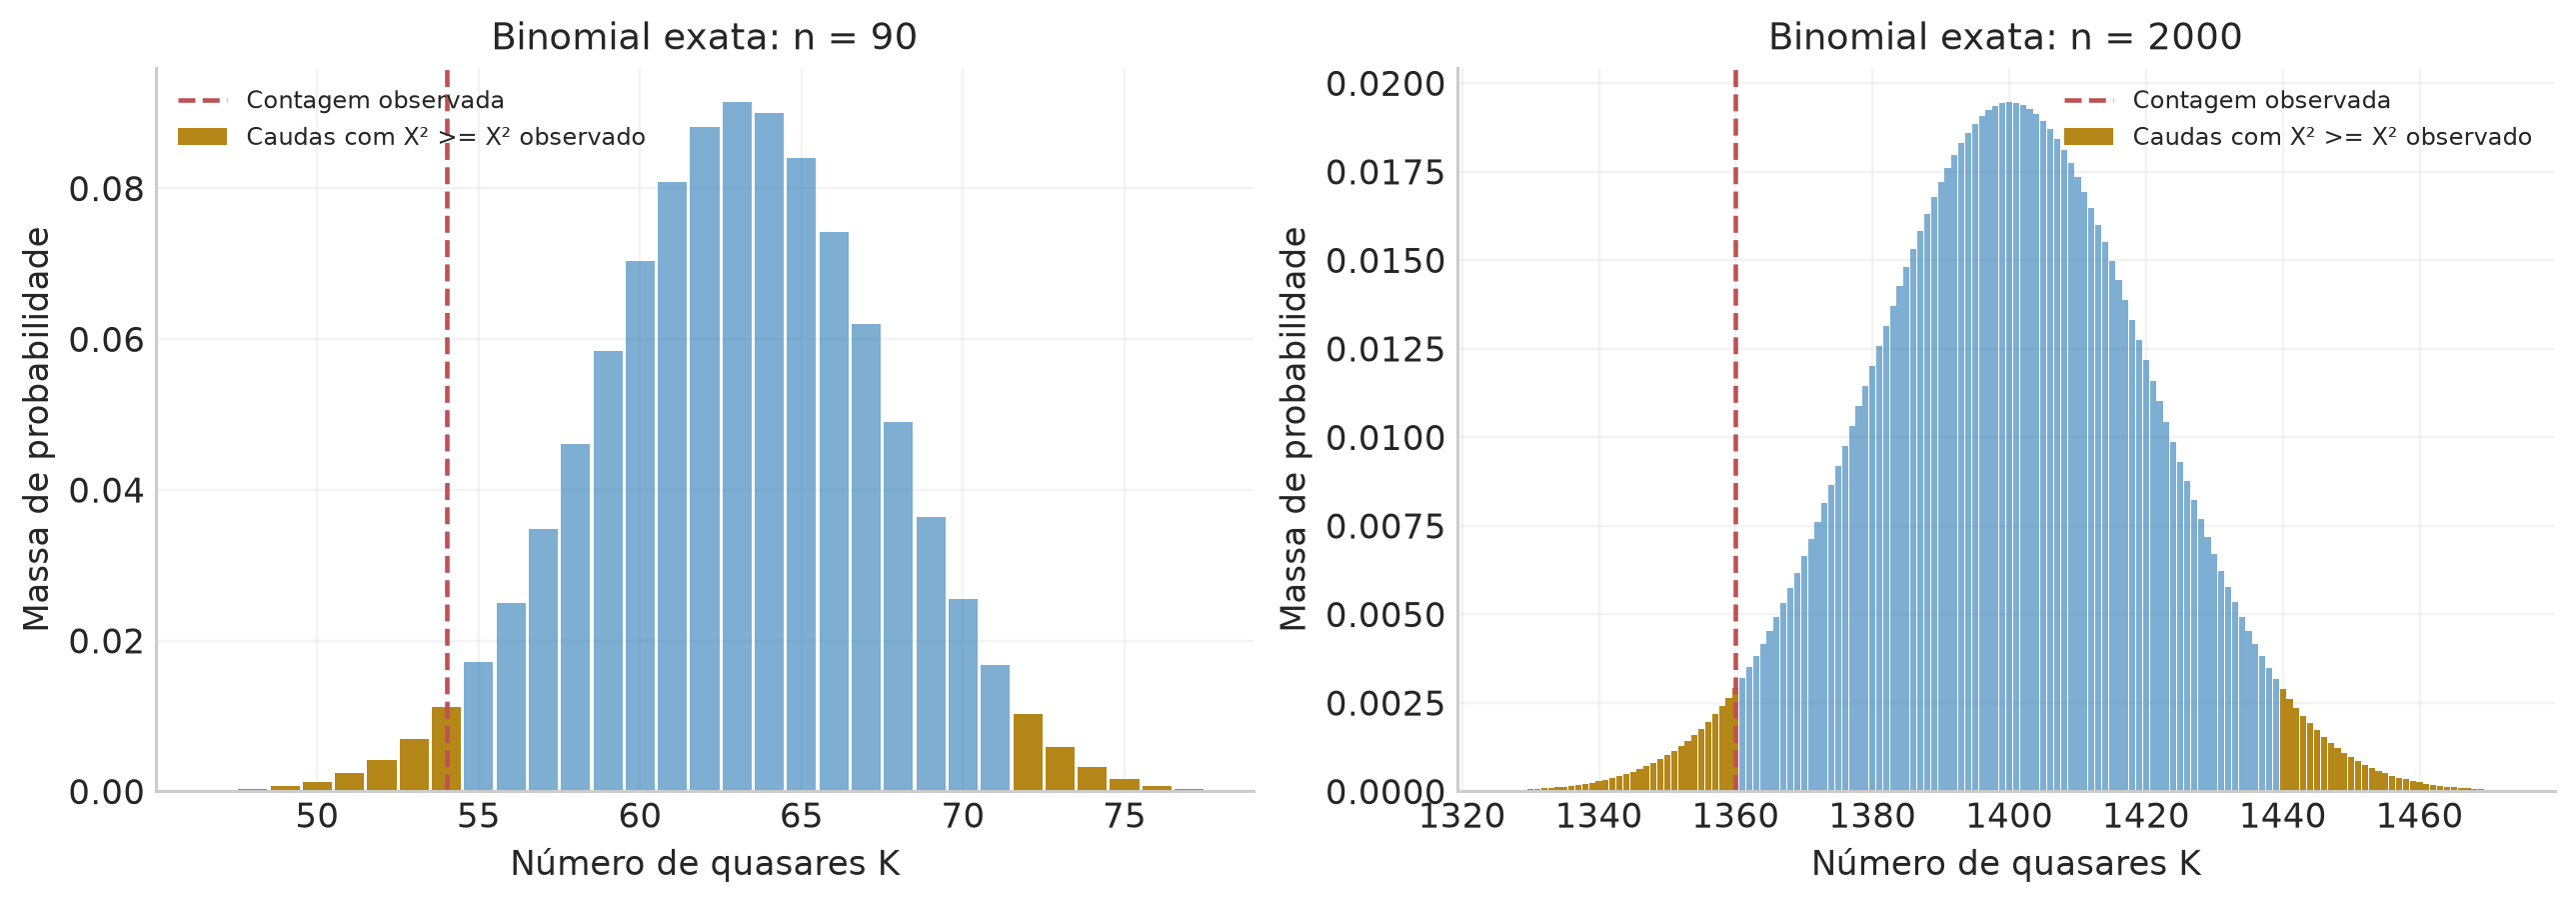

Para 90 fontes, o exemplo fica perto do limiar de 5%: a aproximação de Pearson e a convenção de caudas iguais podem produzir decisões diferentes. Com 2.000 fontes, a aproximação melhora. A comparação deve sempre nomear o teste bilateral utilizado; a expressão “p exato” sozinha deixa essa escolha incompleta.

In [21]:
quasar_rows=[];quasar_refs=[]
for n,k in [(90,54),(2000,1360)]:
    p0=.7;possible=np.arange(n+1);mass=stats.binom.pmf(possible,n,p0)
    qobs=(k-n*p0)**2/(n*p0*(1-p0))
    qpossible=(possible-n*p0)**2/(n*p0*(1-p0))
    left=stats.binom.cdf(k,n,p0);right=stats.binom.sf(k-1,n,p0)
    p_equal=min(1.,2*min(left,right))
    p_order=stats.binomtest(k,n,p0).pvalue
    p_qexact=mass[qpossible>=qobs-1e-12].sum()
    p_asym=stats.chi2.sf(qobs,1)
    q_yates=max(abs(k-n*p0)-.5,0)**2/(n*p0*(1-p0))
    quasar_rows.append([n,k,qobs,p_asym,left,p_equal,p_order,p_qexact,stats.chi2.sf(q_yates,1)])
    quasar_refs.append((n,k,possible,mass,qpossible,qobs))
    check(f'Quasares: total binomial n={n}',np.isclose(mass.sum(),1))
quasar_table=table(quasar_rows,['n','Quasares k','X²','p Pearson assintótico','P(K <= k)',
                              'p bilateral: dobro da cauda','p bilateral: probabilidade',
                              'p exato: discrepância Pearson','p Pearson com continuidade'],
                    name='quasares_testes',digits=7)
fig,axes=plt.subplots(1,2,figsize=(11.6,4),layout='constrained')
for ax,(n,k,possible,mass,qp,qo) in zip(axes,quasar_refs):
    window=(possible>=stats.binom.ppf(.0002,n,.7))&(possible<=stats.binom.ppf(.9998,n,.7))
    ax.bar(possible[window],mass[window],color=BLUE,alpha=.6,width=.9)
    extreme=window&(qp>=qo-1e-12)
    ax.bar(possible[extreme],mass[extreme],color=GOLD,width=.9,label='Caudas com X² >= X² observado')
    ax.axvline(k,color=RED,ls='--',label='Contagem observada')
    ax.set(xlabel='Número de quasares K',ylabel='Massa de probabilidade',title=f'Binomial exata: n = {n}');ax.legend(fontsize=8)
figure_done(fig,'15_quasares_caudas')
display(Markdown('Para 90 fontes, o exemplo fica perto do limiar de 5%: a aproximação de Pearson e a convenção de caudas iguais podem produzir decisões diferentes. '
                 'Com 2.000 fontes, a aproximação melhora. A comparação deve sempre nomear o teste bilateral utilizado; '
                 'a expressão “p exato” sozinha deixa essa escolha incompleta.'))

### 3.5 Gols nas Copas: reproduzir exatamente a tabela do Gregory — slides 106–107

No modelo mais simples, o número de gols $G$ de uma partida com exposição fixa tem massa

$$P(G=g\mid\lambda)=e^{-\lambda}\frac{\lambda^g}{g!},\qquad g=0,1,\ldots.$$

É a distribuição Poisson: pode ser obtida tomando o limite de uma binomial com muitos intervalos pequenos, probabilidade de gol $p=\lambda/m$ por intervalo e independência. De $\binom{m}{g}(\lambda/m)^g(1-\lambda/m)^{m-g}$, os fatores tendem a $\lambda^g/g!$ e $e^{-\lambda}$. No mesmo limite, a média binomial $mp$ é $\lambda$ e sua variância $mp(1-p)$ tende a $\lambda$. Assim $E[G]=\operatorname{Var}(G)=\lambda$.

Para dados individuais $g_1,\ldots,g_n$, a log-verossimilhança é $-n\lambda+(\sum_jg_j)\log\lambda-\sum_j\log(g_j!)$. Sua derivada se anula em $\widehat\lambda=\bar g$, com segunda derivada negativa quando há gols. Essa é a estimativa pela amostra sem agrupamento.

A tabela do Gregory contém **232 partidas**, e não 232 gols. Reproduzimos as frequências originais para 1990, 1994, 1998 e 2002: $[19,49,60,47,32,18,3,4]$, nas classes $0,1,2,3,4,5,6,\ge7$. Uma reconstrução independente com o [Fjelstul World Cup Database](https://github.com/jfjelstul/worldcup), arquivos de [partidas](https://github.com/jfjelstul/worldcup/blob/master/data-csv/matches.csv) e [gols](https://github.com/jfjelstul/worldcup/blob/master/data-csv/goals.csv), recupera as mesmas frequências **usando o tempo regulamentar**, inclusive acréscimos, e excluindo prorrogações. São 575 gols: $575/232\simeq2{,}478448$. O livro arredonda para $\lambda=2{,}4785$.

Na última classe usamos $P(G\ge7)$, incluindo toda a cauda, para que as probabilidades somem 1. O livro usa $\nu=8-1-1=6$: uma restrição pelo total de partidas e um parâmetro estimado. Vamos reproduzir esse cálculo e depois avaliar a adequação da aproximação nas classes esparsas.

Os dados Fjelstul são de Joshua C. Fjelstul, *The Fjelstul World Cup Database v1.2.0*, distribuídos sob [CC BY-SA 4.0](https://github.com/jfjelstul/worldcup/blob/master/LICENSE). As contagens históricas incorporadas a seguir são uma transformação desse conjunto, sob a mesma licença.

,Gols,Partidas observadas,Esperado no livro,Contribuição X²
0,0,19,19.4576,0.0107614
1,1,49,48.2256,0.0124338
2,2,60,59.7636,0.000934869
3,3,47,49.3747,0.114214
4,4,32,30.5938,0.064633
5,5,18,15.1654,0.529841
6,6,3,6.26455,1.70121
7,>= 7,4,3.1547,0.226497


Partidas = 232; gols regulamentares = 575; média = 2.478448276
Reprodução do livro: X² = 2.660524; nu = 6; p = 0.850088


,Procedimento,lambda,X²,nu,p assintótico,Menor esperado
0,"Livro: 8 classes, lambda arredondado",2.4785,2.66052,6,0.850088,3.1547
1,"7 classes, cauda >= 6 e lambda ajustado às classes",2.47099,1.36076,5,0.928557,9.30582


Os dados históricos permanecem compatíveis com a forma Poisson nesses procedimentos. O agrupamento melhora a situação das contagens esperadas. A área de 85% da cauda do exemplo expressa compatibilidade da estatística sob o modelo; uma probabilidade de 85% para a hipótese exigiria outra análise.

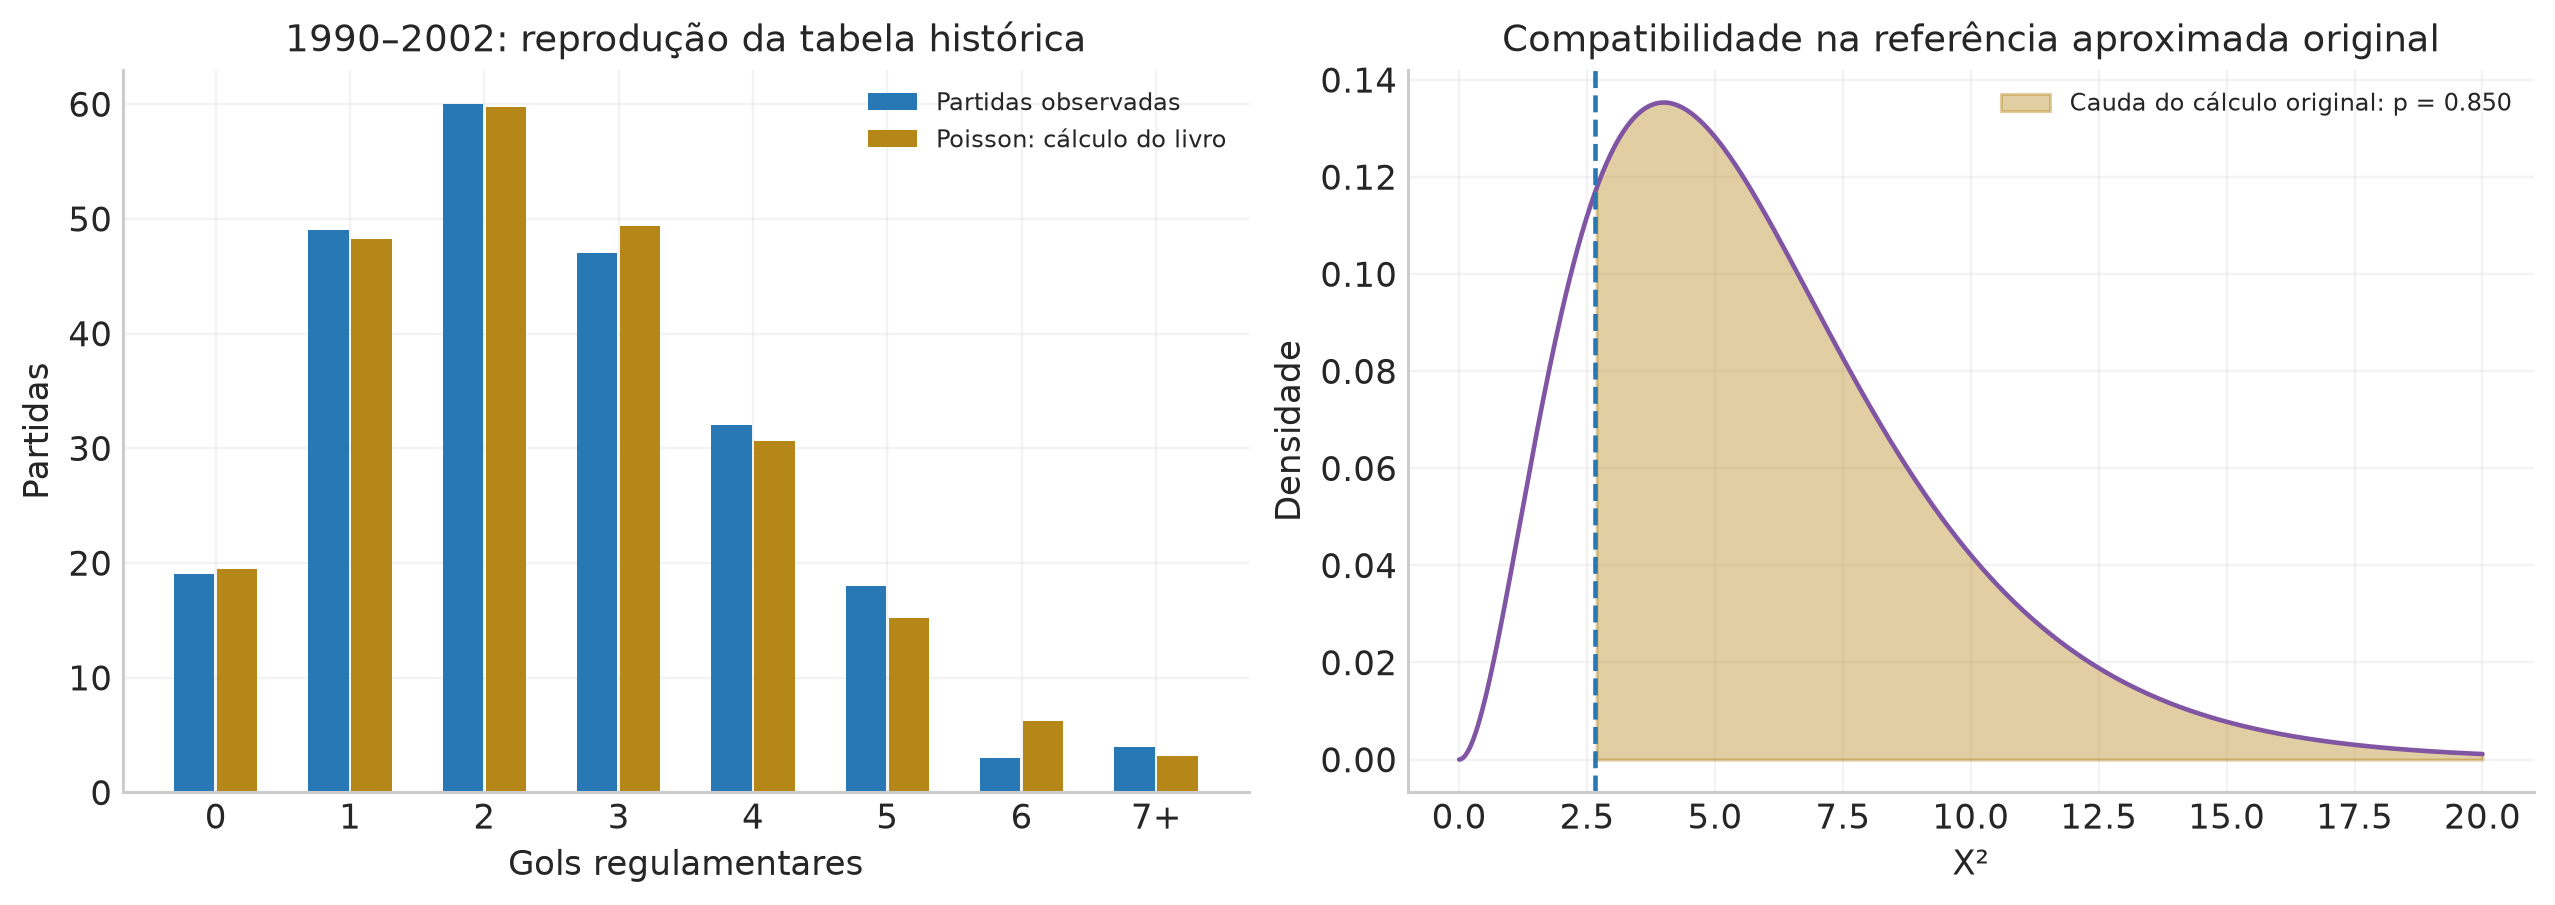

In [22]:
old_goals=np.array([1, 2, 2, 1, 6, 3, 5, 1, 2, 2, 2, 0, 2, 3, 1, 1, 1, 6, 1, 3, 0, 0, 4, 4, 2, 4, 2, 5, 3, 2, 1, 3, 3, 1, 1, 2, 0, 5, 1, 3, 0, 2, 2, 0, 0, 1, 1, 4, 2, 2, 3, 1, 1, 4, 2, 1, 4, 1, 1, 4, 2, 3, 4, 2, 3, 5, 3, 1, 0, 3, 3, 4, 1, 3, 3, 4, 2, 1, 4, 5, 2, 0, 7, 2, 1, 3, 2, 2, 5, 3, 4, 5, 2, 1, 2, 2, 3, 5, 3, 2, 3, 1, 4, 0, 3, 4, 4, 2, 0, 1, 3, 5, 4, 0, 1, 1, 4, 2, 1, 2, 2, 3, 2, 3, 2, 4, 1, 0, 1, 4, 5, 4, 5, 3, 1, 3, 2, 3, 3, 3, 3, 4, 4, 7, 2, 4, 2, 1, 1, 3, 2, 2, 1, 5, 0, 5, 3, 3, 1, 4, 0, 5, 3, 3, 2, 3, 3, 3, 1, 2, 3, 8, 1, 4, 2, 4, 1, 3, 2, 2, 4, 2, 2, 5, 2, 2, 1, 0, 3, 4, 1, 1, 3, 4, 3, 2, 1, 2, 2, 4, 2, 6, 2, 3, 0, 2, 4, 5, 7, 3, 1, 2, 5, 2, 4, 1, 1, 3, 2, 2, 2, 2, 1, 2, 3, 1, 0, 0, 1, 1, 5, 2],dtype=int)
old_counts=np.r_[[np.sum(old_goals==i) for i in range(7)],np.sum(old_goals>=7)]
old_lambda_book=2.4785
old_prob=np.r_[stats.poisson.pmf(np.arange(7),old_lambda_book),stats.poisson.sf(6,old_lambda_book)]
old_expected=len(old_goals)*old_prob
old_Q=pearson_counts(old_counts,old_prob);old_p=stats.chi2.sf(old_Q,6)
table(pd.DataFrame({'Gols':['0','1','2','3','4','5','6','>= 7'],
                    'Partidas observadas':old_counts,'Esperado no livro':old_expected,
                    'Contribuição X²':(old_counts-old_expected)**2/old_expected}),name='copas_gregory')
print(f'Partidas = {len(old_goals)}; gols regulamentares = {old_goals.sum()}; média = {old_goals.mean():.9f}')
print(f'Reprodução do livro: X² = {old_Q:.6f}; nu = 6; p = {old_p:.6f}')
check('Reprodução das oito classes',np.array_equal(old_counts,[19,49,60,47,32,18,3,4]))
check('Reprodução dos gols do Gregory',len(old_goals)==232 and old_goals.sum()==575)

# Conferência com a cauda esparsa agrupada em >= 6 e ajuste pelas contagens agrupadas.
old_merged=np.r_[old_counts[:6],old_counts[6:].sum()]
def old_merged_prob(lam):
    return np.r_[stats.poisson.pmf(np.arange(6),lam),stats.poisson.sf(5,lam)]
old_fit=optimize.minimize_scalar(lambda l:-np.sum(special.xlogy(old_merged,old_merged_prob(l))),
                                bounds=(.1,8),method='bounded')
old_merged_q=pearson_counts(old_merged,old_merged_prob(old_fit.x))
old_merged_p=stats.chi2.sf(old_merged_q,5)
table([['Livro: 8 classes, lambda arredondado',old_lambda_book,old_Q,6,old_p,old_expected.min()],
       ['7 classes, cauda >= 6 e lambda ajustado às classes',old_fit.x,old_merged_q,5,old_merged_p,
        (232*old_merged_prob(old_fit.x)).min()]],
      ['Procedimento','lambda','X²','nu','p assintótico','Menor esperado'],name='copas_gregory_agrupamento')
display(Markdown('Os dados históricos permanecem compatíveis com a forma Poisson nesses procedimentos. '
                 'O agrupamento melhora a situação das contagens esperadas. A área de 85% da cauda do exemplo '
                 'expressa compatibilidade da estatística sob o modelo; uma probabilidade de 85% para a hipótese exigiria outra análise.'))
fig,axes=plt.subplots(1,2,figsize=(11.5,4),layout='constrained')
idx=np.arange(8)
axes[0].bar(idx-.16,old_counts,width=.3,color=BLUE,label='Partidas observadas')
axes[0].bar(idx+.16,old_expected,width=.3,color=GOLD,label='Poisson: cálculo do livro')
axes[0].set(xticks=idx,xticklabels=['0','1','2','3','4','5','6','7+'],xlabel='Gols regulamentares',
            ylabel='Partidas',title='1990–2002: reprodução da tabela histórica');axes[0].legend(fontsize=8)
xx=np.linspace(0,20,500);pdf=stats.chi2.pdf(xx,6)
axes[1].plot(xx,pdf,color=PURPLE)
axes[1].fill_between(xx,0,pdf,where=xx>=old_Q,color=GOLD,alpha=.4,label=fr'Cauda do cálculo original: p = {old_p:.3f}')
axes[1].axvline(old_Q,color=BLUE,ls='--')
axes[1].set(xlabel='X²',ylabel='Densidade',title='Compatibilidade na referência aproximada original');axes[1].legend(fontsize=8)
figure_done(fig,'16_copas_gregory')

### 3.6 Dados de 2002 a 2026: definir a unidade de observação

Usaremos todas as partidas das Copas masculinas de **2002, 2006, 2010, 2014, 2018, 2022 e 2026**: seis edições com 64 jogos e a de 2026 com 104, totalizando **488 partidas**. A fonte é o conjunto aberto [world-cup-data](https://github.com/pawelMSoftware/world-cup-data), mantido por `pawelMSoftware` a partir do OpenFootball, com [auditoria publicada contra dados da FIFA](https://github.com/pawelMSoftware/world-cup-data/blob/main/docs/DATASET_AUDIT.md) e [definição dos campos](https://github.com/pawelMSoftware/world-cup-data/blob/main/docs/DATA_MODEL.md). Os instantâneos dos gols por jogo, em ordem dos códigos de partida, foram incorporados; a execução dispensa baixar os arquivos novamente. Acesso: 28/10/2026.

O campo `full_time_team_a + full_time_team_b` fornece o placar ao fim do tempo regulamentar. Quando existe prorrogação, o campo `extra_time` contém o placar acumulado ao fim dela. Disputas por pênaltis são uma etapa separada e ficam fora da contagem de gols de jogo. Para referência externa, a FIFA registra [308 gols em 104 partidas em 2026](https://inside.fifa.com/tournament-organisation/fifa-world-cup-2026-by-the-numbers/on-the-pitch), incluindo a prorrogação; o instantâneo recupera esse total. Na análise principal, são 300 gols regulamentares nessa edição.

O modelo de cada Copa supõe partidas independentes e uma mesma taxa de gols regulamentares $\lambda_y$ dentro da edição. Equipes com forças diferentes, dependência do placar e mudanças táticas podem afastar a distribuição dessa idealização. O teste examina a forma marginal dos totais por partida; estudar o processo temporal de cada gol é uma pergunta mais detalhada.

Para obter esperados estáveis mesmo nas amostras de 64 jogos, usaremos **as mesmas quatro classes em todas as edições**: 0–1, 2, 3 e $\ge4$ gols. Os histogramas continuarão mostrando classes mais finas para visualizar a distribuição. A classe de teste é uma escolha de análise, distinta da apresentação gráfica.

In [23]:
world_data = {2002: {'regulation': [1, 2, 3, 8, 1, 4, 2, 4, 1, 3, 2, 2, 4, 2, 2, 5, 2, 2, 1, 0, 3, 4, 1, 1, 3, 4, 3, 2, 1, 2, 2, 4, 2, 6, 2, 3, 2, 0, 5, 4, 7, 3, 2, 1, 2, 5, 1, 4, 1, 3, 2, 2, 2, 2, 1, 2, 3, 1, 0, 0, 1, 1, 5, 2], 'including_extra': [1, 2, 3, 8, 1, 4, 2, 4, 1, 3, 2, 2, 4, 2, 2, 5, 2, 2, 1, 0, 3, 4, 1, 1, 3, 4, 3, 2, 1, 2, 2, 4, 2, 6, 2, 3, 2, 0, 5, 4, 7, 3, 2, 1, 2, 5, 1, 4, 1, 3, 3, 2, 2, 2, 1, 3, 3, 1, 0, 1, 1, 1, 5, 2]}, 2006: {'regulation': [6, 2, 1, 0, 3, 1, 4, 1, 4, 3, 2, 3, 0, 1, 4, 4, 1, 3, 2, 1, 6, 3, 0, 2, 2, 2, 0, 2, 2, 2, 4, 4, 3, 3, 4, 2, 3, 2, 0, 5, 2, 3, 5, 4, 1, 1, 2, 2, 2, 2, 1, 1, 1, 0, 3, 4, 2, 3, 0, 1, 0, 1, 4, 2], 'including_extra': [6, 2, 1, 0, 3, 1, 4, 1, 4, 3, 2, 3, 0, 1, 4, 4, 1, 3, 2, 1, 6, 3, 0, 2, 2, 2, 0, 2, 2, 2, 4, 4, 3, 3, 4, 2, 3, 2, 0, 5, 2, 3, 5, 4, 1, 1, 2, 2, 2, 3, 1, 1, 1, 0, 3, 4, 2, 3, 0, 1, 2, 1, 4, 2]}, 2010: {'regulation': [2, 0, 2, 1, 2, 1, 1, 4, 2, 1, 2, 2, 0, 3, 1, 1, 3, 5, 3, 2, 1, 4, 0, 1, 2, 3, 2, 2, 4, 7, 1, 2, 1, 3, 4, 2, 1, 1, 3, 1, 5, 0, 4, 3, 0, 3, 3, 0, 3, 2, 5, 4, 3, 3, 0, 1, 3, 2, 4, 1, 5, 1, 5, 0], 'including_extra': [2, 0, 2, 1, 2, 1, 1, 4, 2, 1, 2, 2, 0, 3, 1, 1, 3, 5, 3, 2, 1, 4, 0, 1, 2, 3, 2, 2, 4, 7, 1, 2, 1, 3, 4, 2, 1, 1, 3, 1, 5, 0, 4, 3, 0, 3, 3, 0, 3, 3, 5, 4, 3, 3, 0, 1, 3, 2, 4, 1, 5, 1, 5, 1]}, 2014: {'regulation': [4, 1, 6, 4, 3, 4, 3, 3, 3, 3, 3, 4, 0, 3, 3, 0, 2, 5, 2, 4, 3, 3, 0, 1, 7, 3, 1, 4, 1, 1, 6, 4, 3, 2, 5, 4, 1, 0, 5, 3, 5, 4, 3, 0, 1, 3, 1, 2, 2, 2, 3, 2, 2, 0, 0, 0, 1, 3, 1, 0, 8, 0, 3, 0], 'including_extra': [4, 1, 6, 4, 3, 4, 3, 3, 3, 3, 3, 4, 0, 3, 3, 0, 2, 5, 2, 4, 3, 3, 0, 1, 7, 3, 1, 4, 1, 1, 6, 4, 3, 2, 5, 4, 1, 0, 5, 3, 5, 4, 3, 0, 1, 3, 1, 2, 2, 2, 3, 2, 2, 3, 1, 3, 1, 3, 1, 0, 8, 0, 3, 1]}, 2018: {'regulation': [5, 1, 1, 6, 3, 2, 1, 2, 1, 1, 2, 1, 3, 3, 3, 3, 4, 1, 1, 1, 2, 1, 3, 2, 2, 3, 7, 3, 3, 7, 4, 3, 3, 3, 2, 4, 0, 2, 3, 3, 2, 3, 2, 4, 1, 1, 1, 3, 7, 3, 2, 2, 2, 5, 1, 2, 2, 3, 2, 2, 1, 2, 2, 6], 'including_extra': [5, 1, 1, 6, 3, 2, 1, 2, 1, 1, 2, 1, 3, 3, 3, 3, 4, 1, 1, 1, 2, 1, 3, 2, 2, 3, 7, 3, 3, 7, 4, 3, 3, 3, 2, 4, 0, 2, 3, 3, 2, 3, 2, 4, 1, 1, 1, 3, 7, 3, 2, 2, 2, 5, 1, 2, 2, 3, 2, 4, 1, 3, 2, 6]}, 2022: {'regulation': [2, 8, 2, 2, 3, 0, 0, 5, 0, 3, 7, 1, 1, 0, 5, 2, 2, 4, 2, 0, 1, 2, 3, 2, 1, 2, 5, 2, 6, 5, 1, 2, 3, 2, 3, 1, 1, 1, 2, 3, 0, 3, 3, 6, 2, 3, 5, 1, 4, 3, 4, 3, 2, 5, 0, 7, 0, 4, 1, 3, 3, 2, 3, 4], 'including_extra': [2, 8, 2, 2, 3, 0, 0, 5, 0, 3, 7, 1, 1, 0, 5, 2, 2, 4, 2, 0, 1, 2, 3, 2, 1, 2, 5, 2, 6, 5, 1, 2, 3, 2, 3, 1, 1, 1, 2, 3, 0, 3, 3, 6, 2, 3, 5, 1, 4, 3, 4, 3, 2, 5, 0, 7, 2, 4, 1, 3, 3, 2, 3, 6]}, 2026: {'regulation': [2, 3, 2, 5, 2, 2, 1, 2, 8, 4, 1, 6, 0, 2, 2, 4, 4, 5, 3, 4, 2, 6, 1, 4, 2, 5, 6, 1, 2, 1, 3, 1, 6, 3, 0, 4, 4, 0, 4, 4, 2, 3, 5, 3, 5, 0, 1, 1, 3, 4, 3, 6, 3, 1, 2, 3, 2, 4, 5, 0, 5, 5, 0, 1, 2, 6, 2, 3, 0, 4, 6, 4, 1, 3, 2, 2, 3, 3, 2, 3, 4, 2, 3, 3, 2, 2, 2, 1, 3, 1, 3, 5, 1, 5, 5, 0, 2, 3, 2, 2, 2, 3, 10, 0], 'including_extra': [2, 3, 2, 5, 2, 2, 1, 2, 8, 4, 1, 6, 0, 2, 2, 4, 4, 5, 3, 4, 2, 6, 1, 4, 2, 5, 6, 1, 2, 1, 3, 1, 6, 3, 0, 4, 4, 0, 4, 4, 2, 3, 5, 3, 5, 0, 1, 1, 3, 4, 3, 6, 3, 1, 2, 3, 2, 4, 5, 0, 5, 5, 0, 1, 2, 6, 2, 3, 0, 4, 6, 4, 1, 3, 2, 2, 3, 3, 2, 3, 5, 2, 3, 3, 2, 2, 5, 1, 3, 1, 3, 5, 1, 5, 5, 0, 2, 3, 3, 4, 2, 3, 10, 1]}}
world_years=np.array(sorted(world_data))
world_reg={y:np.array(world_data[y]['regulation'],dtype=int) for y in world_years}
world_extra={y:np.array(world_data[y]['including_extra'],dtype=int) for y in world_years}
world_all=np.concatenate([world_reg[y] for y in world_years])
table([[y,len(world_reg[y]),world_reg[y].sum(),world_extra[y].sum(),world_reg[y].mean(),
        world_reg[y].var(ddof=1),world_reg[y].var(ddof=1)/world_reg[y].mean()]
       for y in world_years],
      ['Copa','Partidas','Gols regulamentares','Gols com prorrogação','Média regulamentar',
       'Variância amostral','Variância / média'],name='copas_dados')
check('488 partidas nas sete Copas',len(world_all)==488)
check('2026 confere com total oficial',len(world_extra[2026])==104 and world_extra[2026].sum()==308)
check('2002 confere com a reconstrução histórica',world_reg[2002].sum()==158)

,Copa,Partidas,Gols regulamentares,Gols com prorrogação,Média regulamentar,Variância amostral,Variância / média
0,2002,64,158,161,2.46875,2.69742,1.09263
1,2006,64,144,147,2.25,2.25397,1.00176
2,2010,64,143,145,2.23438,2.46801,1.10456
3,2014,64,163,171,2.54688,3.45809,1.35778
4,2018,64,166,169,2.59375,2.46726,0.951234
5,2022,64,168,172,2.625,3.53968,1.34845
6,2026,104,300,308,2.88462,3.46229,1.20026


### 3.7 Ajustar e testar a Poisson a partir das classes

Nas quatro classes escolhidas, as probabilidades são

$$p_1=e^{-\lambda}(1+\lambda),\quad p_2=e^{-\lambda}\lambda^2/2,
\quad p_3=e^{-\lambda}\lambda^3/6,\quad p_4=P(G\ge4).$$

Para preservar a justificativa de $k-1-r$, estimamos $\lambda$ pela verossimilhança **dessas contagens**. A média individual $\bar g$ continua aparecendo como resumo descritivo, enquanto o ajuste agrupado $\widetilde\lambda$ pode diferir dela por perda de informação nas classes de cauda.

Maximizamos $\ell(\lambda)=\sum_iO_i\log p_i(\lambda)$. Sua derivada é

$$\ell'(\lambda)=O_1\frac{-\lambda}{1+\lambda}
+O_2\left(\frac2\lambda-1\right)+O_3\left(\frac3\lambda-1\right)
+O_4\frac{P_\lambda(G=3)}{P_\lambda(G\ge4)}.$$

Para o último termo, derivar a cauda $1-e^{-\lambda}(1+\lambda+\lambda^2/2+\lambda^3/6)$ dá exatamente $P_\lambda(G=3)$. O código encontra a raiz da derivada por bisseção em um intervalo amplo, conferindo o resultado observado por uma otimização independente. Com um parâmetro estimado, $\nu=4-1-1=2$.

A calibração Monte Carlo repete **sortear contagens → estimar a taxa → calcular Pearson**. Os $p$-valores simulados têm erro de contagem e resolução finitos; exibiremos a estimativa e seu erro aproximado. Essa calibração se limita ao modelo independente proposto.

In [24]:
def world_counts(goals):
    goals=np.asarray(goals)
    return np.array([np.sum(goals<=1),np.sum(goals==2),np.sum(goals==3),np.sum(goals>=4)])
def world_prob(lam):
    lam=np.asarray(lam,dtype=float)
    e=np.exp(-lam)
    return np.stack([e*(1+lam),e*lam**2/2,e*lam**3/6,special.gammainc(4,lam)],axis=-1)
def fit_world_counts(counts):
    """Ajusta uma linha ou várias linhas de contagens; última dimensão = 4 classes."""
    c=np.asarray(counts,dtype=float)
    lo=np.full(c.shape[:-1],1e-5);hi=np.full(c.shape[:-1],30.)
    for _ in range(44):
        lam=(lo+hi)/2; p3=np.exp(-lam)*lam**3/6;tail=special.gammainc(4,lam)
        score=(c[...,0]*(-lam/(1+lam))+c[...,1]*(2/lam-1)
               +c[...,2]*(3/lam-1)+c[...,3]*p3/tail)
        lo=np.where(score>0,lam,lo);hi=np.where(score>0,hi,lam)
    return (lo+hi)/2
def world_stat(counts,lam):
    counts=np.asarray(counts);e=counts.sum(axis=-1,keepdims=True)*world_prob(lam)
    return np.sum((counts-e)**2/e,axis=-1)

world_results=[];world_refs={};world_fits={}
for index,(label,goals) in enumerate([(str(y),world_reg[y]) for y in world_years]+[('Combinada',world_all)]):
    o=world_counts(goals);lam=float(fit_world_counts(o));qobs=float(world_stat(o,lam))
    rng=rng_for(20+index);c=rng.multinomial(len(goals),world_prob(lam),size=12000)
    lr=fit_world_counts(c);qr=world_stat(c,lr)
    p_mc,se_mc=mc_tail(qr,qobs);p_asym=stats.chi2.sf(qobs,2)
    world_results.append([label,len(goals),goals.mean(),lam,qobs,2,
                          (len(goals)*world_prob(lam)).min(),p_asym,p_mc,se_mc,verdict(p_mc)])
    world_refs[label]=qr;world_fits[label]=(lam,qobs,p_mc)
    check(f'Probabilidades Copa {label}',np.isclose(world_prob(lam).sum(),1))
    direct=optimize.minimize_scalar(lambda l:-np.sum(special.xlogy(o,world_prob(l))),bounds=(.1,8),method='bounded')
    check(f'Ajuste agrupado Copa {label}',abs(lam-direct.x)<1e-4)
world_results=table(world_results,['Copa','Partidas','Média individual','Taxa ajustada às classes','X²','nu',
                                  'Menor esperado','p assintótico','p Monte Carlo','Erro MC aprox.','Decisão a 5%'],
                     name='copas_testes',digits=6)

,Copa,Partidas,Média individual,Taxa ajustada às classes,X²,nu,Menor esperado,p assintótico,p Monte Carlo,Erro MC aprox.,Decisão a 5%
0,2002,64,2.46875,2.40195,3.30156,2,13.3834,0.1919,0.193151,0.00360359,manter H0 entre os modelos compatíveis neste nível
1,2006,64,2.25,2.32214,0.463394,2,13.0979,0.793186,0.79835,0.00366258,manter H0 entre os modelos compatíveis neste nível
2,2010,64,2.23438,2.2426,0.804016,2,12.1017,0.668975,0.679443,0.0042601,manter H0 entre os modelos compatíveis neste nível
3,2014,64,2.54688,2.58913,6.10942,2,13.901,0.0471363,0.0485793,0.00196247,rejeitar H0 neste nível
4,2018,64,2.59375,2.41761,3.30533,2,13.4349,0.191538,0.195984,0.00362354,manter H0 entre os modelos compatíveis neste nível
5,2022,64,2.625,2.53769,0.00933872,2,13.7797,0.995342,0.994417,0.000680149,manter H0 entre os modelos compatíveis neste nível
6,2026,104,2.88462,2.8531,0.331375,2,23.1078,0.847311,0.853179,0.00323077,manter H0 entre os modelos compatíveis neste nível
7,Combinada,488,2.54508,2.50753,0.0580459,2,104.472,0.971394,0.973169,0.00147504,manter H0 entre os modelos compatíveis neste nível


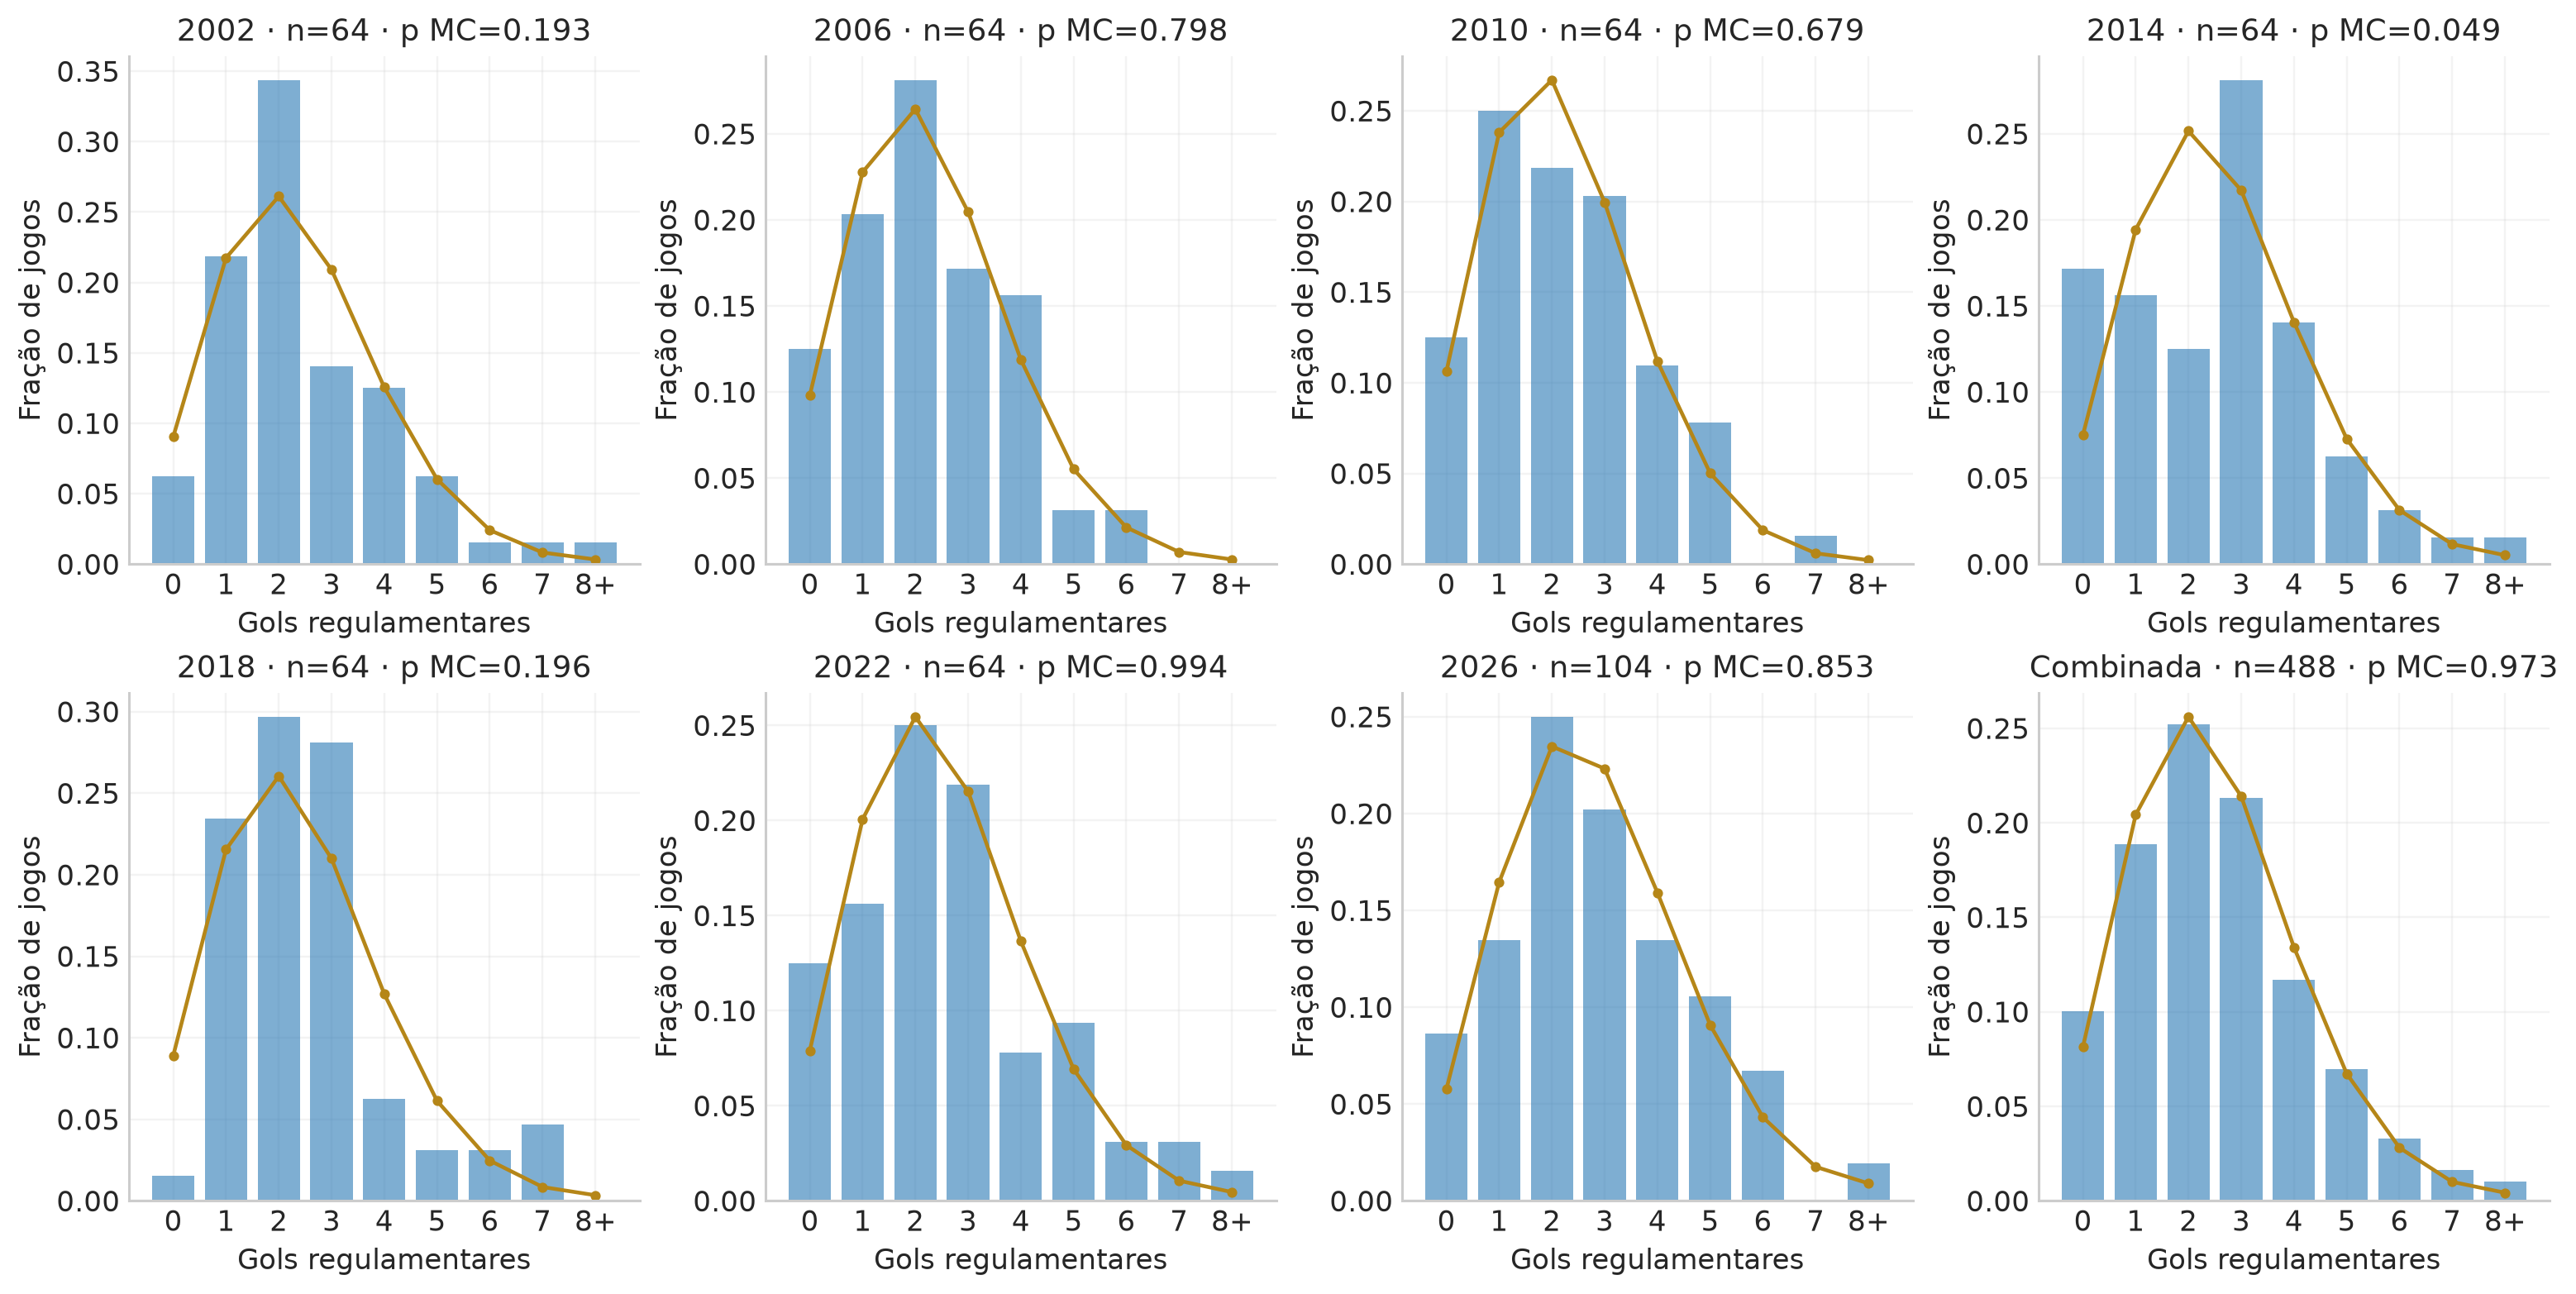

As barras mostram nove classes para inspeção visual. Os testes usam as quatro classes explicitadas, com a taxa reajustada a cada repetição. A tabela fornece a decisão para **cada edição** e para a amostra concatenada. Manter a hipótese entre os modelos compatíveis significa que essa discrepância, nessa resolução de classes, não forneceu evidência suficiente para afastá-la no nível escolhido.

In [26]:
fig,axes=plt.subplots(2,4,figsize=(14,7),layout='constrained')
for ax,(label,goals) in zip(axes.flat,[(str(y),world_reg[y]) for y in world_years]+[('Combinada',world_all)]):
    lam,qo,pm=world_fits[label]
    observed=np.r_[[np.sum(goals==i) for i in range(8)],np.sum(goals>=8)]
    probability=np.r_[stats.poisson.pmf(np.arange(8),lam),stats.poisson.sf(7,lam)]
    idx=np.arange(9)
    ax.bar(idx,observed/len(goals),color=BLUE,alpha=.6)
    ax.plot(idx,probability,'o-',color=GOLD,ms=3,lw=1.5)
    ax.set(xticks=idx,xticklabels=['0','1','2','3','4','5','6','7','8+'],
           xlabel='Gols regulamentares',ylabel='Fração de jogos',
           title=f'{label} · n={len(goals)} · p MC={pm:.3f}')
figure_done(fig,'16_copas_distribuicoes')
display(Markdown('As barras mostram nove classes para inspeção visual. Os testes usam as quatro classes explicitadas, '
                 'com a taxa reajustada a cada repetição. A tabela fornece a decisão para **cada edição** e para a amostra concatenada. '
                 'Manter a hipótese entre os modelos compatíveis significa que essa discrepância, nessa resolução de classes, '
                 'não forneceu evidência suficiente para afastá-la no nível escolhido.'))

### 3.8 O que significa “combinar as Copas”?

Há pelo menos três perguntas diferentes:

1. **Poisson única para todos os jogos:** concatenar as 488 partidas e ajustar uma taxa comum. É a linha “Combinada” da tabela anterior. Esse modelo exige forma Poisson e uma taxa comum entre edições.
2. **Forma Poisson em cada edição, permitindo taxas diferentes:** somar as discrepâncias dos sete testes, $Q_{\rm soma}=\sum_yX_y^2$. Sob independência e a aproximação qui-quadrado de cada ajuste, a soma tem $\sum_y\nu_y=14$ graus de liberdade. Somar uma referência simulada independente de cada edição oferece uma segunda calibração.
3. **Igualdade das taxas entre edições:** se os totais $S_y$ são Poisson independentes com esperanças $n_y\lambda$, condicionando em $S=\sum_yS_y$ temos $(S_y)_y\mid S\sim\operatorname{Multinomial}(S,(n_y/N)_y)$. Assim testamos especificamente se as taxas são iguais, respeitando os tamanhos diferentes das Copas.

A última relação pode ser deduzida dividindo $\prod_y e^{-n_y\lambda}(n_y\lambda)^{S_y}/S_y!$ pela probabilidade Poisson de $S$, cuja média é $N\lambda$. Os fatores em $\lambda$ se cancelam, restando $S!\prod_y(n_y/N)^{S_y}/S_y!$.

Uma mistura de Poissons com taxas distintas tem

$$E[G]=E[\lambda],\qquad \operatorname{Var}(G)=E[\lambda]+\operatorname{Var}(\lambda).$$

A lei da variância total explica a dispersão adicional de uma mistura. Essa estrutura pode aparecer mesmo se cada Copa, isoladamente, for bem descrita por Poisson. A combinação deve indicar qual dessas hipóteses está sendo testada.

,Hipótese combinada,Estatística,nu,p assintótico,p Monte Carlo,Erro MC aprox.
0,Uma Poisson para as 488 partidas,0.0580459,2,0.971394,0.973169,0.00147504
1,Poisson em cada edição; taxas próprias,14.3244,14,0.42583,0.436047,0.00452668
2,"Taxa igual entre edições, condicional nos gols",9.6948,6,0.138107,0.139194,0.0021892


Uma Poisson para as 488 partidas: manter H0 entre os modelos compatíveis neste nível
Poisson em cada edição; taxas próprias: manter H0 entre os modelos compatíveis neste nível
Taxa igual entre edições, condicional nos gols: manter H0 entre os modelos compatíveis neste nível


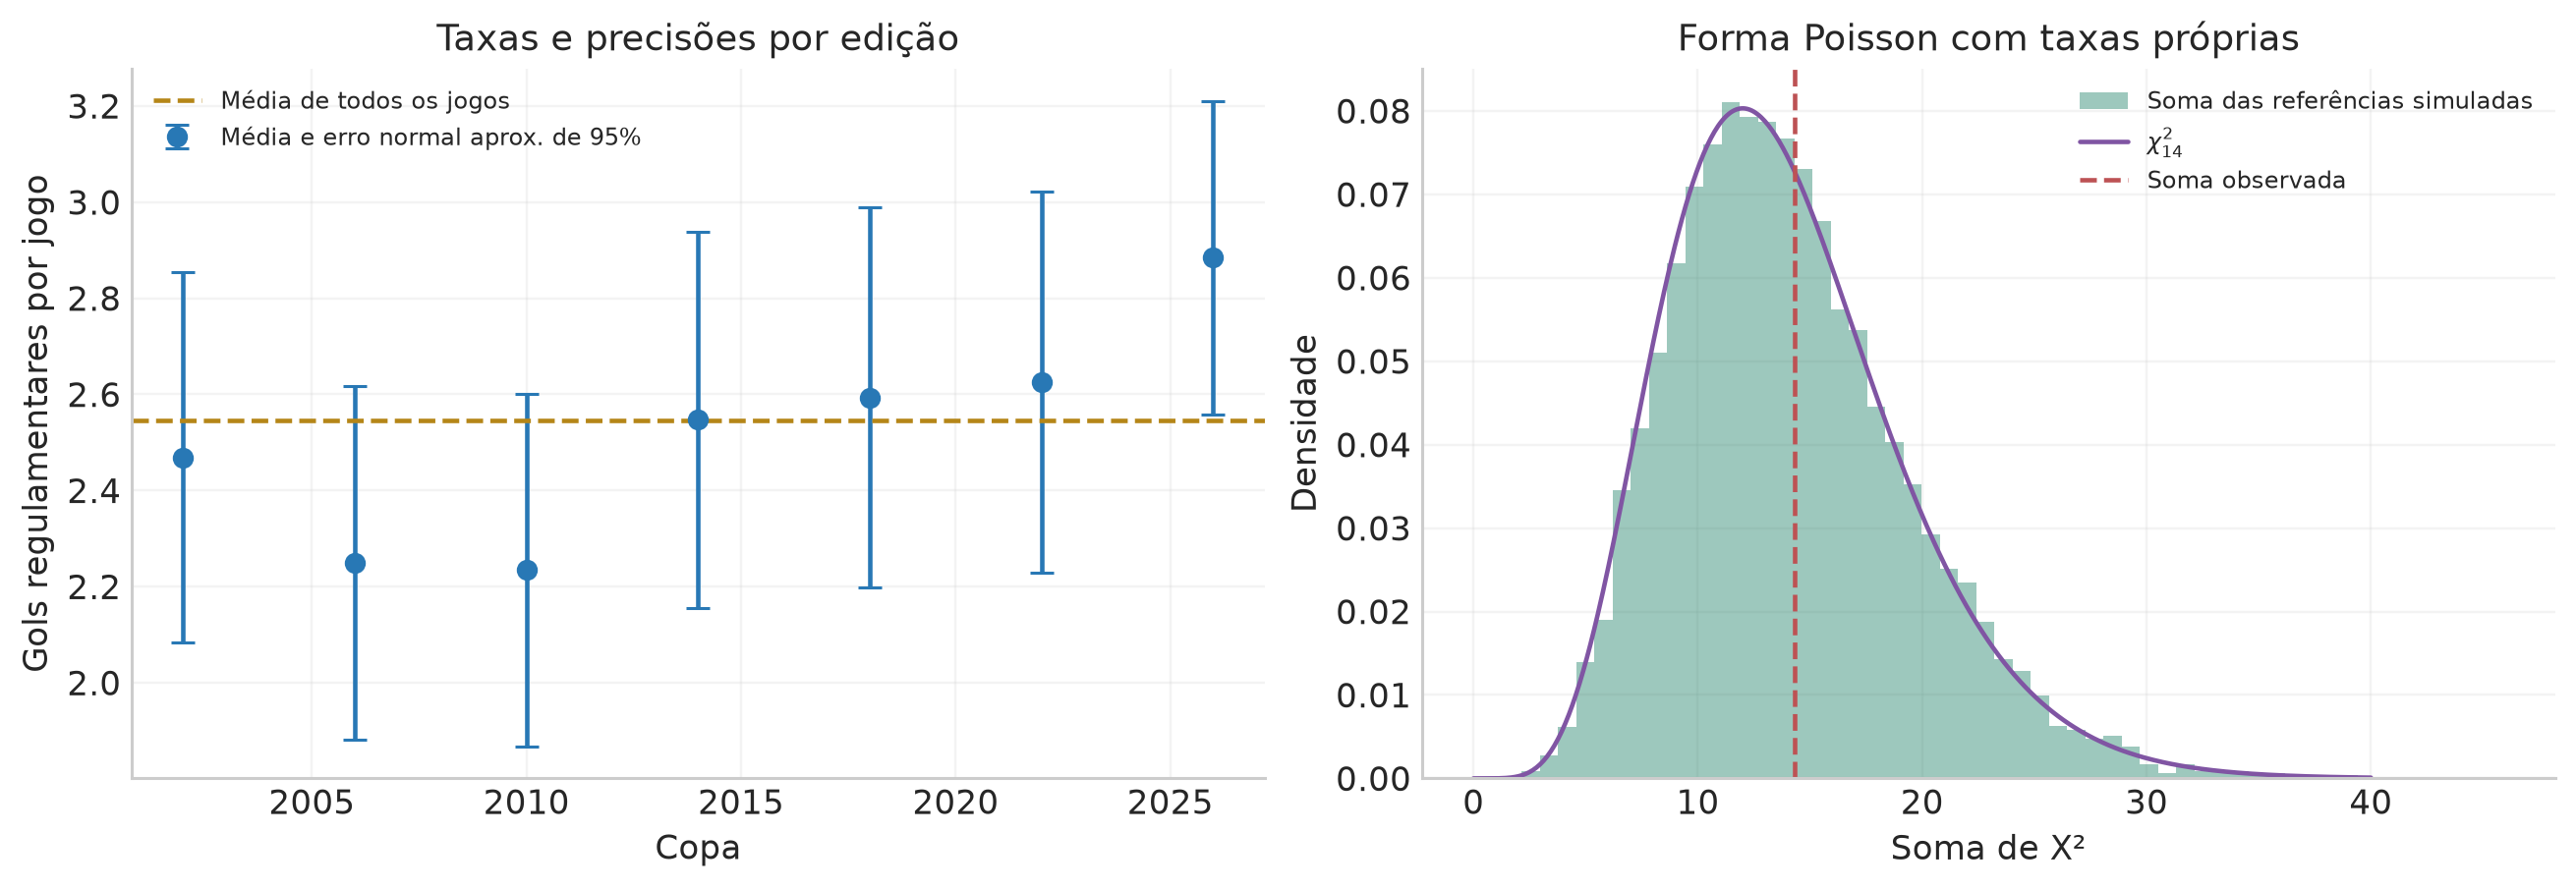

In [27]:
world_sum_Q=sum(world_fits[str(y)][1] for y in world_years)
world_sum_reference=sum(world_refs[str(y)] for y in world_years)
world_sum_p_mc,world_sum_se=mc_tail(world_sum_reference,world_sum_Q)
world_sizes=np.array([len(world_reg[y]) for y in world_years])
world_totals=np.array([world_reg[y].sum() for y in world_years])
world_weights=world_sizes/world_sizes.sum()
world_rate_Q=pearson_counts(world_totals,world_weights)
rng=rng_for(40)
rate_reference=rng.multinomial(world_totals.sum(),world_weights,size=25000)
rate_E=world_totals.sum()*world_weights
rate_Qref=np.sum((rate_reference-rate_E)**2/rate_E,axis=1)
world_rate_p_mc,world_rate_se=mc_tail(rate_Qref,world_rate_Q)
combined_table=table([
    ['Uma Poisson para as 488 partidas',world_fits['Combinada'][1],2,
     world_results.iloc[-1]['p assintótico'],world_fits['Combinada'][2],world_results.iloc[-1]['Erro MC aprox.']],
    ['Poisson em cada edição; taxas próprias',world_sum_Q,14,stats.chi2.sf(world_sum_Q,14),world_sum_p_mc,world_sum_se],
    ['Taxa igual entre edições, condicional nos gols',world_rate_Q,6,stats.chi2.sf(world_rate_Q,6),world_rate_p_mc,world_rate_se]],
    ['Hipótese combinada','Estatística','nu','p assintótico','p Monte Carlo','Erro MC aprox.'],
    name='copas_combinacoes')
for _,row in combined_table.iterrows():
    print(row['Hipótese combinada']+': '+verdict(row['p Monte Carlo']))
fig,axes=plt.subplots(1,2,figsize=(11.8,4),layout='constrained')
rates=world_totals/world_sizes;se=np.sqrt(world_totals)/world_sizes
axes[0].errorbar(world_years,rates,yerr=1.96*se,fmt='o',color=BLUE,capsize=4,label='Média e erro normal aprox. de 95%')
axes[0].axhline(world_all.mean(),color=GOLD,ls='--',label='Média de todos os jogos')
axes[0].set(xlabel='Copa',ylabel='Gols regulamentares por jogo',title='Taxas e precisões por edição');axes[0].legend(fontsize=8)
axes[1].hist(world_sum_reference,bins=55,density=True,color=GREEN,alpha=.45,label='Soma das referências simuladas')
xx=np.linspace(0,max(40,world_sum_Q*1.1),500)
axes[1].plot(xx,stats.chi2.pdf(xx,14),color=PURPLE,label=r'$\chi^2_{14}$')
axes[1].axvline(world_sum_Q,color=RED,ls='--',label='Soma observada')
axes[1].set(xlabel='Soma de X²',ylabel='Densidade',title='Forma Poisson com taxas próprias');axes[1].legend(fontsize=8)
figure_done(fig,'17_copas_combinacoes')

### 3.9 Interpretação, sensibilidade e limites da combinação

Os erros da figura de taxas usam $\operatorname{Var}(S_y)=n_y\lambda_y$, de modo que $\operatorname{SE}(S_y/n_y)=\sqrt{\lambda_y/n_y}\simeq\sqrt{S_y}/n_y$; as barras de $1{,}96$ erros são uma aproximação normal para esses totais. São resumos de precisão sob o modelo, distintos dos testes de forma.

Comparar sete edições separadamente envolve várias decisões. A soma das discrepâncias responde a uma pergunta global previamente definida. Uma média dos sete $p$-valores não tem, em geral, uma distribuição uniforme sob a hipótese global, por isso usamos a estatística e sua referência combinadas.

As partidas das Copas analisadas se sobrepõem entre equipes e têm estruturas de fase e chaveamento. Aqui a independência é uma idealização explícita. Passar em um teste marginal de forma fornece informação nessa idealização; investigar seleção de equipes, empates, gols dependentes do estado do jogo ou variação temporal exige modelos adicionais.

O quadro seguinte mostra o efeito da convenção de duração. Incluir prorrogação aumenta a exposição em apenas algumas partidas. Uma taxa por partida única passa então a misturar exposições diferentes. Para modelar essa versão de forma física, seria natural usar médias proporcionais aos minutos jogados, ou separar partidas com durações distintas.

In [28]:
table([[y,world_reg[y].sum(),world_extra[y].sum(),
        world_extra[y].sum()-world_reg[y].sum(),world_reg[y].mean(),world_extra[y].mean()]
       for y in world_years],
      ['Copa','Gols regulamentares','Gols com prorrogação','Gols adicionais','Média regulamentar','Média com prorrogação'],
      name='copas_prorrogacao');

,Copa,Gols regulamentares,Gols com prorrogação,Gols adicionais,Média regulamentar,Média com prorrogação
0,2002,158,161,3,2.46875,2.51562
1,2006,144,147,3,2.25,2.29688
2,2010,143,145,2,2.23438,2.26562
3,2014,163,171,8,2.54688,2.67188
4,2018,166,169,3,2.59375,2.64062
5,2022,168,172,4,2.625,2.6875
6,2026,300,308,8,2.88462,2.96154


## Parte 4 — Estrelas semelhantes ao Sol e a regra de parada
### 4.1 A fábula do observador e do teorista — slides 108–110

Esta é a **fábula estatística do Gregory, §7.4**, e não uma observação do catálogo HYG. O teorista prevê uma fração $f_0=0{,}1$ de estrelas de classe G, semelhantes ao Sol nesse critério espectral. O observador registra cinco estrelas G em 102 estrelas examinadas. A discrepância entre os personagens vem de dois desenhos de experimento:

* **Tamanho fixo:** escolher $N=102$ antes da observação e contar $K$, o número de estrelas G.
* **Número de sucessos fixo:** observar até registrar $r=5$ estrelas G e contar $N$, o número total necessário.

No primeiro experimento, $K\sim\operatorname{Binomial}(102,f)$, com massa $\binom{102}{k}f^k(1-f)^{102-k}$. No segundo, a última observação é o quinto sucesso; nas primeiras $N-1$ posições há exatamente quatro sucessos. Contando suas posições,

$$\boxed{P(N=n\mid r,f)=\binom{n-1}{r-1}f^r(1-f)^{n-r}},\qquad n=r,r+1,\ldots.$$

Essa é a binomial negativa escrita para o **número total de tentativas**. No SciPy, `nbinom(r,f)` representa o número de **fracassos antes do r-ésimo sucesso**, $F=N-r$. A mudança de variável precisa ser respeitada ao calcular caudas.

Para reproduzir a convenção bilateral de caudas iguais da fábula:

$$p_{N\ \rm fixo}=2P(K\le5\mid N=102,f_0),$$
$$p_{r\ \rm fixo}=2P(N\ge102\mid r=5,f_0).$$

Uma maneira independente de conferir o segundo evento é observar que $N\ge102$ equivale a ter no máximo quatro sucessos nas primeiras 101 tentativas:

$$P(N\ge102\mid r=5,f_0)=P\{\operatorname{Binomial}(101,f_0)\le4\}.$$

As referências diferem porque incluem resultados possíveis de experimentos diferentes. Definir a amostragem também define como o teste controla seus erros.

,Experimento,"Cauda relevante, antes do fator 2",p bilateral de caudas iguais,Decisão a 5%
0,N = 102 fixado antes; K observado = 5,K <= 5,0.10196728,manter H0 entre os modelos compatíveis neste nível
1,r = 5 fixado antes; N observado = 102,N >= 102,0.044247246,rejeitar H0 neste nível


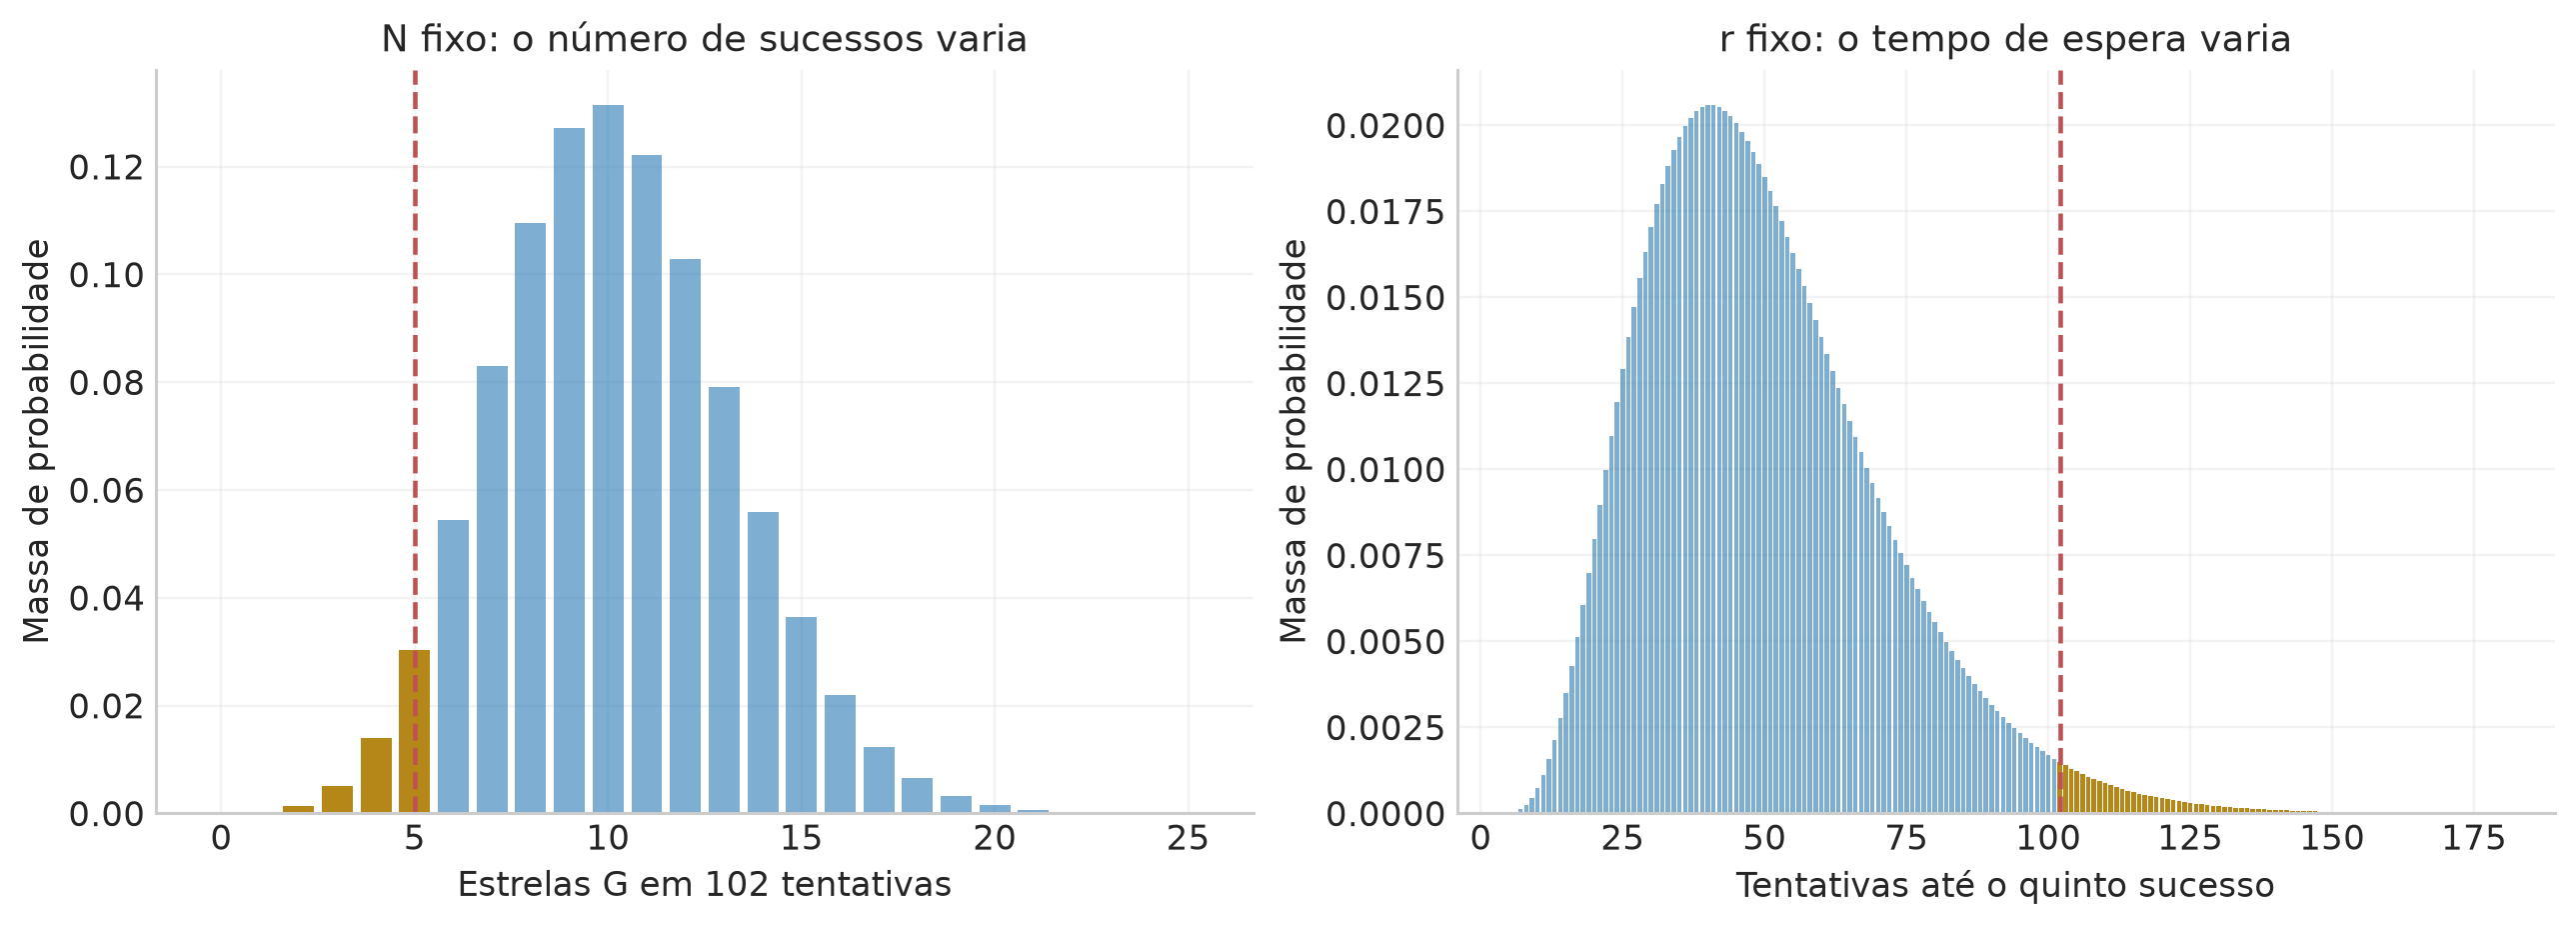

Com os eventos e limites inclusivos acima, os valores são **10.1967%** e **4.4247%**. A fábula cita cerca de 10% e 4,3%; o cálculo direto da segunda cauda é aproximadamente 4,42%, preservando a diferença de decisão a 5%. Os trechos dourados mostram a cauda observada relevante; os testes da tabela incluem o fator 2 da convenção bilateral.

In [29]:
sun_N=102;sun_r=5;sun_f0=.1
sun_p_fixed=min(1,2*stats.binom.cdf(sun_r,sun_N,sun_f0))
# F = N-r. P(F >= 97) = sf(96), pois sf(a) = P(F > a).
sun_p_stop=min(1,2*stats.nbinom.sf(sun_N-sun_r-1,sun_r,sun_f0))
sun_wait_check=2*stats.binom.cdf(sun_r-1,sun_N-1,sun_f0)
table([['N = 102 fixado antes; K observado = 5','K <= 5',sun_p_fixed,verdict(sun_p_fixed)],
       ['r = 5 fixado antes; N observado = 102','N >= 102',sun_p_stop,verdict(sun_p_stop)]],
      ['Experimento','Cauda relevante, antes do fator 2','p bilateral de caudas iguais','Decisão a 5%'],
      name='sol_regras_parada',digits=8)
check('Cauda binomial negativa: contagem equivalente',np.isclose(sun_p_stop,sun_wait_check))
fig,axes=plt.subplots(1,2,figsize=(11.6,4.1),layout='constrained')
k=np.arange(26);prob=stats.binom.pmf(k,sun_N,sun_f0)
axes[0].bar(k,prob,color=BLUE,alpha=.6);axes[0].bar(k[k<=sun_r],prob[k<=sun_r],color=GOLD)
axes[0].axvline(sun_r,color=RED,ls='--');axes[0].set(xlabel='Estrelas G em 102 tentativas',ylabel='Massa de probabilidade',title='N fixo: o número de sucessos varia')
nn=np.arange(sun_r,181);prob=stats.nbinom.pmf(nn-sun_r,sun_r,sun_f0)
axes[1].bar(nn,prob,color=BLUE,alpha=.6);axes[1].bar(nn[nn>=sun_N],prob[nn>=sun_N],color=GOLD)
axes[1].axvline(sun_N,color=RED,ls='--');axes[1].set(xlabel='Tentativas até o quinto sucesso',ylabel='Massa de probabilidade',title='r fixo: o tempo de espera varia')
figure_done(fig,'18_sol_amostragens')
display(Markdown(fr'Com os eventos e limites inclusivos acima, os valores são **{100*sun_p_fixed:.4f}%** '
                    fr'e **{100*sun_p_stop:.4f}%**. A fábula cita cerca de 10% e 4,3%; '
                    r'o cálculo direto da segunda cauda é aproximadamente 4,42%, preservando a diferença de decisão a 5%. '
                    r'Os trechos dourados mostram a cauda observada relevante; os testes da tabela incluem o fator 2 da convenção bilateral.'))

### 4.2 A mesma dependência em $f$ produz a mesma posterior — slides 111–112

Os dois desenhos levam, para os resultados observados, a

$$L_B(f)=\binom{102}{5}f^5(1-f)^{97},\qquad
L_{NB}(f)=\binom{101}{4}f^5(1-f)^{97}.$$

As constantes combinatórias diferem, mas ambas são independentes de $f$. Sua razão é $L_B/L_{NB}=102/5=20{,}4$. A informação sobre $f$ está na mesma função $f^5(1-f)^{97}$.

Escolhemos uma prior Beta, definida por

$$\pi(f)=\frac{f^{a-1}(1-f)^{b-1}}{B(a,b)},\quad
B(a,b)=\int_0^1 u^{a-1}(1-u)^{b-1}du,\quad a,b>0.$$

Multiplicar prior e verossimilhança soma os expoentes. A integral da função resultante é $B(a+5,b+97)$, de modo que

$$\boxed{f\mid D\sim\operatorname{Beta}(a+5,b+97)}.$$

Com prior uniforme, $a=b=1$, obtemos $\operatorname{Beta}(6,98)$. Para inteiros, a integral Beta pode ser obtida por integrações por partes, resultando em $B(a,b)=(a-1)!(b-1)!/(a+b-1)!$; a função Gamma estende a identidade para parâmetros positivos gerais.

A média posterior vem da razão $B(a'+1,b')/B(a',b')=a'/(a'+b')$. A moda interior resulta de derivar $(a'-1)\log f+(b'-1)\log(1-f)$, dando $(a'-1)/(a'+b'-2)$. Os intervalos centrais usam a inversa da CDF Beta, que calcularemos numericamente.

A invariância entre os dois desenhos vale quando a regra de parada e a seleção são **ignoráveis para a inferência em $f$**: contribuem fatores comuns independentes de $f$ ou já estão representadas no modelo. Uma seleção dependente do parâmetro ou a publicação seletiva dos resultados pode exigir outra verossimilhança. Interrupção por clima independente, por exemplo, permite aproveitar as observações obtidas com o modelo da interrupção apropriado.

,Quantidade,Valor
0,Média posterior de f,0.057692308
1,Moda posterior de f,0.049019608
2,ICr 95%: limite inferior,0.021675198
3,ICr 95%: limite superior,0.10965615
4,"P(f > 0,1 | D, modelo contínuo)",0.047948873


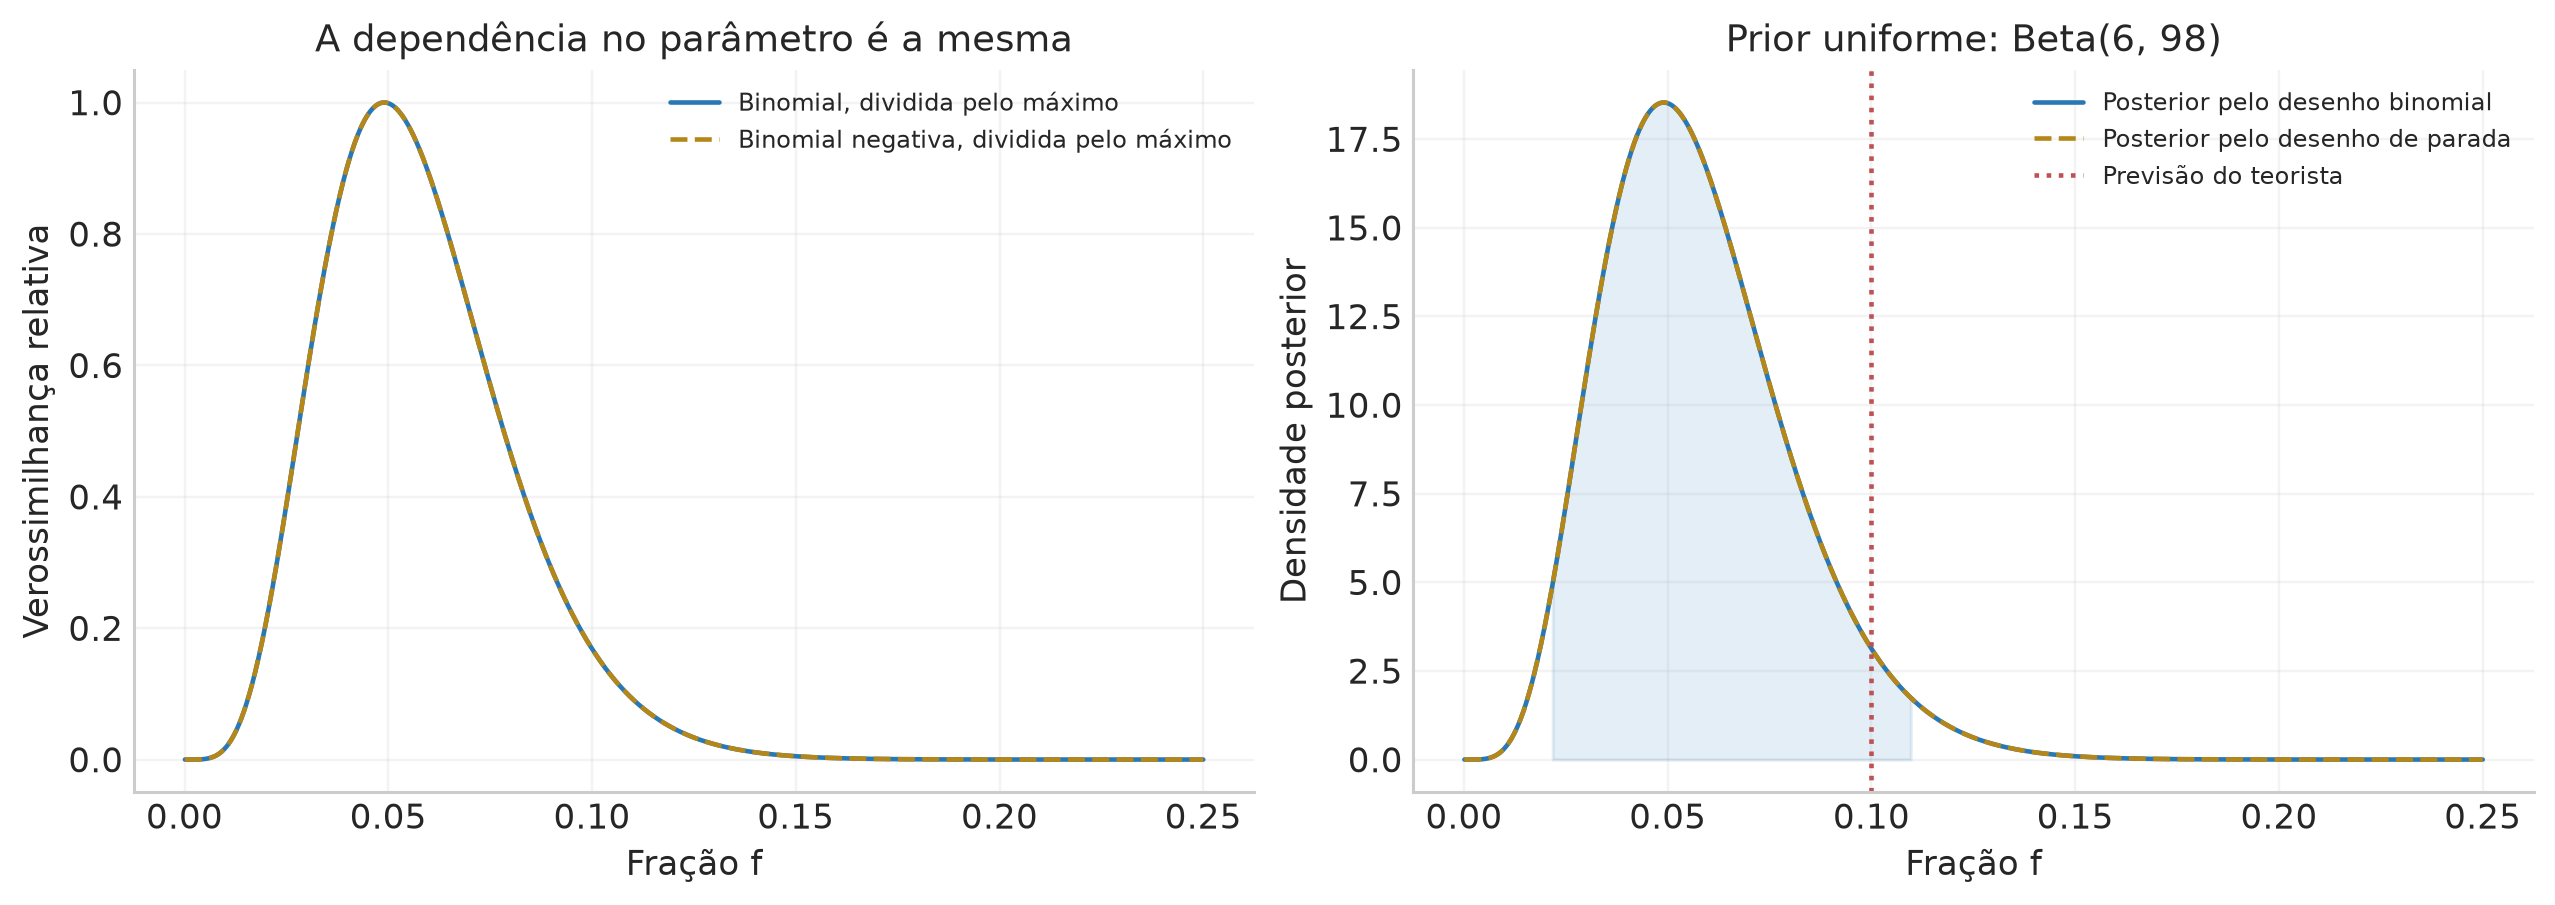

In [30]:
sun_a,sun_b=6,98
sun_post_mean=sun_a/(sun_a+sun_b)
sun_post_mode=(sun_a-1)/(sun_a+sun_b-2)
sun_ci=stats.beta.ppf([.025,.975],sun_a,sun_b)
fg=np.linspace(.0001,.25,1500)
sun_logkernel=sun_r*np.log(fg)+(sun_N-sun_r)*np.log1p(-fg)
sun_logcB=special.gammaln(sun_N+1)-special.gammaln(sun_r+1)-special.gammaln(sun_N-sun_r+1)
sun_logcNB=special.gammaln(sun_N)-special.gammaln(sun_r)-special.gammaln(sun_N-sun_r+1)
# A normalização analítica cancela as constantes do desenho.
sun_pdf_B=np.exp(sun_logcB+sun_logkernel-(sun_logcB+special.betaln(sun_a,sun_b)))
sun_pdf_NB=np.exp(sun_logcNB+sun_logkernel-(sun_logcNB+special.betaln(sun_a,sun_b)))
table([['Média posterior de f',sun_post_mean],['Moda posterior de f',sun_post_mode],
       ['ICr 95%: limite inferior',sun_ci[0]],['ICr 95%: limite superior',sun_ci[1]],
       ['P(f > 0,1 | D, modelo contínuo)',stats.beta.sf(.1,sun_a,sun_b)]],
      ['Quantidade','Valor'],name='sol_posterior',digits=8)
fig,axes=plt.subplots(1,2,figsize=(11.5,4),layout='constrained')
axes[0].plot(fg,np.exp(sun_logkernel-sun_logkernel.max()),color=BLUE,label='Binomial, dividida pelo máximo')
axes[0].plot(fg,np.exp(sun_logkernel-sun_logkernel.max()),color=GOLD,ls='--',label='Binomial negativa, dividida pelo máximo')
axes[0].set(xlabel='Fração f',ylabel='Verossimilhança relativa',title='A dependência no parâmetro é a mesma');axes[0].legend(fontsize=8)
axes[1].plot(fg,sun_pdf_B,color=BLUE,label='Posterior pelo desenho binomial')
axes[1].plot(fg,sun_pdf_NB,color=GOLD,ls='--',label='Posterior pelo desenho de parada')
axes[1].fill_between(fg,0,sun_pdf_B,where=(fg>=sun_ci[0])&(fg<=sun_ci[1]),color=BLUE,alpha=.12)
axes[1].axvline(.1,color=RED,ls=':',label='Previsão do teorista')
axes[1].set(xlabel='Fração f',ylabel='Densidade posterior',title='Prior uniforme: Beta(6, 98)');axes[1].legend(fontsize=8)
figure_done(fig,'19_sol_posterior')
check('Posteriors das duas amostragens',np.allclose(sun_pdf_B,sun_pdf_NB))
check('Posterior Beta normalizada',np.isclose(integrate.quad(lambda f:stats.beta.pdf(f,6,98),0,1)[0],1))

### 4.3 Resolver a pergunta final do slide 113: e as evidências dos modelos?

Vamos comparar $M_0:f=f_0=0{,}1$ com $M_1:f$ livre e prior uniforme em $[0,1]$. No modelo pontual, a evidência é a verossimilhança em $f_0$. No modelo livre, ela é a integral da verossimilhança pela prior. Escrevendo $C_D$ para a constante combinatória do desenho,

$$m_0(D)=C_Df_0^5(1-f_0)^{97},\qquad
m_1(D)=C_DB(6,98).$$

O **fator de Bayes a favor do modelo livre** é

$$\boxed{B_{10}=\frac{m_1(D)}{m_0(D)}=
\frac{B(6,98)}{f_0^5(1-f_0)^{97}}}.$$

O fator combinatório se cancela **na comparação dentro de cada desenho**, produzindo o mesmo fator de Bayes para as duas regras. As evidências absolutas diferem: são probabilidades de resultados definidos em espaços amostrais diferentes. O objeto comparável entre os modelos é a razão para o mesmo experimento.

Com probabilidades a priori iguais para $M_0$ e $M_1$, as odds posteriores são $B_{10}$ e

$$P(M_0\mid D)=\frac{1}{1+B_{10}},\qquad P(M_1\mid D)=\frac{B_{10}}{1+B_{10}}.$$

Essa é uma probabilidade para um **modelo com massa pontual em $f_0$**, comparado com um modelo contínuo. Já $P(f>f_0\mid D,M_1)$ é uma probabilidade de região **dentro do modelo contínuo**. As duas quantidades respondem a perguntas distintas.

A evidência do modelo livre pondera todas as suas previsões pela prior. Uma prior muito ampla distribui probabilidade por muitas frações que poderiam ter produzido outros resultados. Por isso uma boa verossimilhança no melhor ajuste e um pequeno $p$-valor em um teste específico podem coexistir com um fator de Bayes que favorece o modelo pontual. Cada análise precisa declarar sua hipótese, seu desenho e, no caso bayesiano, suas priors.

In [31]:
sun_logm0_B=stats.binom.logpmf(sun_r,sun_N,sun_f0)
sun_logm1_B=sun_logcB+special.betaln(sun_a,sun_b)
sun_logm0_NB=stats.nbinom.logpmf(sun_N-sun_r,sun_r,sun_f0)
sun_logm1_NB=sun_logcNB+special.betaln(sun_a,sun_b)
sun_B10=np.exp(sun_logm1_B-sun_logm0_B)
sun_model0=1/(1+sun_B10)
table([['N fixo',np.exp(sun_logm0_B),np.exp(sun_logm1_B),sun_B10,sun_model0],
       ['r fixo',np.exp(sun_logm0_NB),np.exp(sun_logm1_NB),
        np.exp(sun_logm1_NB-sun_logm0_NB),sun_model0]],
      ['Desenho','Evidência de M0','Evidência de M1','B10','P(M0 | D), odds prévias iguais'],
      name='sol_evidencias',digits=9)
prior_rows=[]
for a,b in [(1,1),(.5,.5),(2,18)]:
    logbf=special.betaln(a+sun_r,b+sun_N-sun_r)-special.betaln(a,b)
    logbf-=sun_r*np.log(sun_f0)+(sun_N-sun_r)*np.log1p(-sun_f0)
    bf=np.exp(logbf)
    prior_rows.append([a,b,a/(a+b),bf,1/(1+bf)])
table(prior_rows,['a da prior de M1','b da prior de M1','Média a priori de f','B10',
                  'P(M0 | D), odds prévias iguais'],name='sol_sensibilidade_prior')
check('BF invariável nos dois desenhos',np.isclose(sun_logm1_B-sun_logm0_B,sun_logm1_NB-sun_logm0_NB))
check('Evidência uniforme binomial',np.isclose(np.exp(sun_logm1_B),1/(sun_N+1)))
check('Razão de constantes combinatórias',np.isclose(np.exp(sun_logcB-sun_logcNB),sun_N/sun_r))
display(Markdown(fr'Com prior uniforme em $M_1$, temos $B_{{10}}={sun_B10:.6f}$ e '
                    fr'$P(M_0\mid D)={sun_model0:.4f}$ sob odds prévias iguais. '
                    r'A sensibilidade às priors de $M_1$ está explícita na tabela. '
                    r'As priors são escolhas de modelos para comparação, definidas antes da atualização; '
                    r'a tabela mostra como essas escolhas afetam a evidência.'))

,Desenho,Evidência de M0,Evidência de M1,B10,"P(M0 | D), odds prévias iguais"
0,N fixo,0.0303476443,0.00970873786,0.319917347,0.757623197
1,r fixo,0.00148762962,0.000475918523,0.319917347,0.757623197


,a da prior de M1,b da prior de M1,Média a priori de f,B10,"P(M0 | D), odds prévias iguais"
0,1,1,0.5,0.319917,0.757623
1,0.5,0.5,0.5,0.463933,0.683091
2,2,18,0.1,2.12372,0.320131


Com prior uniforme em $M_1$, temos $B_{10}=0.319917$ e $P(M_0\mid D)=0.7576$ sob odds prévias iguais. A sensibilidade às priors de $M_1$ está explícita na tabela. As priors são escolhas de modelos para comparação, definidas antes da atualização; a tabela mostra como essas escolhas afetam a evidência.

## Fechamento — Organizar as perguntas antes de calcular

| Pergunta | Hipótese e dados | Referência / cálculo | Ponto central |
|:--|:--|:--|:--|
| A galáxia é compatível com fluxo constante? | Normal, erros instrumentais conhecidos, média ajustada | $\chi^2_{n-1}$ | O erro instrumental fixa a escala dos resíduos |
| As médias da toxina diferem? | Amostras independentes, normalidade aproximada, variâncias próprias | Student aproximada de Welch | O erro padrão da diferença é estimado |
| A marginal estelar acompanha a área do céu? | Catálogo selecionado e referência isotrópica | KS da variável $(1+\sin b)/2$ | A geometria determina a distribuição de comparação |
| Os perfis educacionais são iguais? | Categorias comuns e desenho amostral declarado | Pearson de homogeneidade | Estimativas expandidas e contagens IID têm precisões diferentes |
| Uma forma normal descreve as notas? | Escala discreta, limites, parâmetros ajustados | Pearson e simulação com reajuste | A observação e a estimação entram na referência |
| A fração de quasares é 0,7? | Fontes independentes, binomial | Caudas exatas ou aproximação de Pearson | A definição bilateral deve ser identificada |
| Gols por jogo seguem Poisson? | Exposição de 90 minutos e independência idealizada | Pearson agrupado, ajuste e simulação | Forma e igualdade de taxas são perguntas distintas |
| A fração de estrelas G é 0,1? | Tamanho fixo ou parada no quinto sucesso | Binomial / binomial negativa | O desenho determina o conjunto de referência |
| Como atualizar a informação sobre f? | Mesma prior e verossimilhanças proporcionais | Posterior Beta | Fatores de parada ignoráveis se cancelam na normalização |
| Como comparar f livre com f = 0,1? | Priors nos modelos e no parâmetro do modelo livre | Evidências e fator de Bayes | As constantes se cancelam na razão dentro de cada desenho |

O roteiro que se repetiu foi **pergunta → modelo e hipóteses → estatística → distribuição de referência → cálculo → tamanho do efeito e interpretação**. Na perspectiva frequentista, o procedimento é avaliado por suas repetições; na bayesiana, a atualização compara o suporte dos dados aos valores de parâmetros ou aos modelos declarados. Identificar o condicionamento em cada probabilidade permite aproveitar o que cada cálculo responde.

### Leituras e conferências

* **Gregory, capítulo 7:** Tabelas 7.1 e 7.2 para os dados originais; §7.3 para aderência e distribuições agrupadas; §7.4 para a fábula e a resolução bayesiana. O capítulo 6 fornece a base das distribuições amostrais, reconstruída aqui quando utilizada.
* **Slides da Parte 2, 85–114:** roteiro da exposição. No exemplo da galáxia, $\sigma=2,7$ é o erro instrumental conhecido; no rio, o denominador de Welch soma os termos de variância e o cálculo bilateral com os dados fornece 0,03863. Na Copa histórica, 232 é o número de partidas. A regra de parada pede uma referência compatível com a decisão; os dados de uma interrupção podem ser analisados com um modelo adequado.
* **Fontes dos dados públicos:** HYG v4.0 (5070 estrelas, $m_V\le6$), SIDRA 10061 (18 anos ou mais, 2022), Fjelstul World Cup Database (1990–2002) e world-cup-data (2002–2026). Os links, filtros e convenções estão nas seções correspondentes. O recorte estelar e os dados históricos derivados de bases CC BY-SA 4.0 mantêm essa licença e a atribuição dos autores; essa indicação se refere aos dados, enquanto as explicações e os cálculos são desenvolvidos neste notebook.
* **Referências metodológicas complementares:** [NIST: Pearson](https://www.itl.nist.gov/div898/handbook/eda/section3/eda35f.htm), [NIST: KS](https://www.itl.nist.gov/div898/handbook/eda/section3/eda35g.htm), [SciPy: Welch](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html) e [calibração de aderência com parâmetros ajustados](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.goodness_of_fit.html).


In [32]:
# Auditoria do instantâneo: identifica as entradas públicas usadas, sem acessar a rede.
source_hashes = [['HYG v4.0: CSV filtrado', 'dcabb4e7c93598215f448097ec2c4acb616539509c64a22f0612eba42d1eaf67'], ['SIDRA 10061: resposta JSON', '8f2799b088d3e2245fed4322ca01be21fb10a995112fcde7906106d1ab8f8245'], ['Fjelstul: partidas, CSV original', '037f718764758e7dda3a2918276f85fa8389af1d50999d2a480c8a6a49408875'], ['Fjelstul: gols, CSV original', '4fbe990b7f42bb8af00d1587af09359ecfdb4ee4101bb44fda0eb336fc1e5be3'], ['world-cup-data: 2002.json', '25a4309c7408e74179a5fb8b9dd3883cefab0d631bfcaedcefcb0df3db7c8651'], ['world-cup-data: 2006.json', '7f7da2f096cbefed9a176b6acc3ec3ec92473510c839e82454eb433ef965823c'], ['world-cup-data: 2010.json', '1d96b59d370c316ba79cab608283eb2c13de0a185180bf5abc5b3dfca739b2d8'], ['world-cup-data: 2014.json', '1ef3c68ef50123b42f44f2f11bffe87e5ce73030308f5a642d09871c93d37f1a'], ['world-cup-data: 2018.json', 'ba70ba0ee35873dc174a510be68cbf08baa853760a7c2638bf76353b3b9e1f3b'], ['world-cup-data: 2022.json', '03ef83b7a6d37184de046b82d5e34b77a3b2a29e44dcd74e4cef72972ab3395f'], ['world-cup-data: 2026.json', '3758b1b626c7dd19fbde575806bc910156bc38df53de452fde2a879b3a4c8183']]
table(source_hashes,['Instantâneo','SHA-256'],name='fontes_incorporadas',digits=6)
check('Esperados das Copas acima de 5',world_results['Menor esperado'].min()>5)
check('p-valores calculados no intervalo unitário',
      np.all((world_results['p Monte Carlo']>0)&(world_results['p Monte Carlo']<=1)))
print(f'{len(checks)} verificações numéricas e de integridade concluídas.')
print('As células de simulação declaram o tamanho das repetições e as sementes utilizadas.')
print('Figuras e tabelas estão no notebook. Para exportar, ative SALVAR_ARQUIVOS e execute novamente.')

,Instantâneo,SHA-256
0,HYG v4.0: CSV filtrado,dcabb4e7c93598215f448097ec2c4acb616539509c64a22f0612eba42d1eaf67
1,SIDRA 10061: resposta JSON,8f2799b088d3e2245fed4322ca01be21fb10a995112fcde7906106d1ab8f8245
2,"Fjelstul: partidas, CSV original",037f718764758e7dda3a2918276f85fa8389af1d50999d2a480c8a6a49408875
3,"Fjelstul: gols, CSV original",4fbe990b7f42bb8af00d1587af09359ecfdb4ee4101bb44fda0eb336fc1e5be3
4,world-cup-data: 2002.json,25a4309c7408e74179a5fb8b9dd3883cefab0d631bfcaedcefcb0df3db7c8651
5,world-cup-data: 2006.json,7f7da2f096cbefed9a176b6acc3ec3ec92473510c839e82454eb433ef965823c
6,world-cup-data: 2010.json,1d96b59d370c316ba79cab608283eb2c13de0a185180bf5abc5b3dfca739b2d8
7,world-cup-data: 2014.json,1ef3c68ef50123b42f44f2f11bffe87e5ce73030308f5a642d09871c93d37f1a
8,world-cup-data: 2018.json,ba70ba0ee35873dc174a510be68cbf08baa853760a7c2638bf76353b3b9e1f3b
9,world-cup-data: 2022.json,03ef83b7a6d37184de046b82d5e34b77a3b2a29e44dcd74e4cef72972ab3395f


58 verificações numéricas e de integridade concluídas.
As células de simulação declaram o tamanho das repetições e as sementes utilizadas.
Figuras e tabelas estão no notebook. Para exportar, ative SALVAR_ARQUIVOS e execute novamente.
